# ANFIS-FCM sMoE U-Net — Explainable Edge Detection on BSDS500

**v13 — clean, modular rewrite of the v12 notebook.** The architecture, the training recipe and the research contributions are unchanged; the evaluation protocol is corrected, the code is reorganised into documented sections, and an ablation driver is added. The accompanying file `REVIEW_v12_to_v13.md` lists every finding of the v12 code review and what was changed in response.

## The method implemented here

| Component | What it is | Section |
|---|---|---|
| **Sobel-guided sMoE U-Net** (backbone) | A U-Net whose three deepest skip connections (e2/e3/e4) pass through a *sparse Mixture-of-Experts* block. A 1×1 gate on the Sobel edge magnitude of the input image chooses, per pixel, between a **context** expert (3×3, dilation 2), a **boundary** expert (1×1) and a **corner/junction** expert (1×3 · 3×1 · 3×3 · dilated-3×3 branches). | 4 |
| **ANFIS fuzzy head** | A five-layer Jang (1993) ANFIS on two per-pixel inputs: $x_1$ = calibrated Sobel magnitude, $x_2$ = backbone confidence. Gaussian membership functions → product T-norm → normalised firing (softmax over log-firings) → first-order TSK consequents on the backbone **log-odds** → sigmoid. | 5 |
| **FCM rule discovery** | Membership functions are initialised by Fuzzy C-Means on sampled $(x_1, x_2)$ training pixels (centre = cluster centre, width = membership-weighted std). The rule count $R^\*$ is chosen by the Xie–Beni index (shortlist) and a held-out validation score (parsimony rule). Consequents start from the closed-form IRLS solution (the logistic counterpart of Jang's hybrid LSE step). | 7 |
| **Training** | Phase 0a backbone warm-up (BCE+Dice, deep supervision) → Phase 0b rule discovery → Stage A (head only, backbone frozen) → Stage B (joint fine-tuning: gradual unfreeze, $x_2$ drift anchor, rule-utilisation regulariser, early stopping on validation loss). | 6–8 |
| **Evaluation** | The BSDS500 benchmark through the **pyEdgeEval** reference matcher (8-bit maps → NMS → 99 thresholds → thinning → per-annotator `correspondPixels` → BSDS MATLAB aggregation), bootstrap CIs over test images, paired ANFIS-vs-backbone comparisons, and a **coverage calibration** that makes the fixed threshold grid span each model's whole PR curve (section 9 explains why this is necessary and why it is rank-preserving). | 9–10 |
| **Explanations** | Rule firing maps, exact per-rule log-odds corrections, rule-base plots, rule health profiling (usage, dominance, purity, redundancy), and sMoE strategy maps. | 11 |

## What changed from v12 (summary — details in `REVIEW_v12_to_v13.md`)

1. **Evaluation (the ODS/OIS/AP inconsistency).** v12's rows disagreed with each other because the model's scores are compressed towards 0 (a consequence of the unweighted BCE+Dice objective on a 95 %-background problem): with the raw map the benchmark's 99 thresholds start *above* the ODS operating point (recall never exceeds 0.68 → ODS and AP under-estimated), and with v11's single logit shift the grid *ends* at recall 0.27 (AP counts precision 0 below it). v12 had already derived the right remedy — a rank-preserving logit-affine map $p' = \sigma(\mathrm{logit}(p)/T + c)$ whose 99 thresholds cover the curve — but rejected it with a rule that demanded a *higher ODS* from a transform that only changes *grid placement*. v13 fits this calibration **per model from validation recall alone** (no ODS tuning), applies it to every row, keeps the strict uncalibrated rows for transparency, and checks the grid coverage of every reported row. For the ANFIS head the calibration is exactly a rescaling of the TSK consequents, for the backbone a rescaling of its last 1×1 convolution — i.e. it lives inside the model's output layer, not in the benchmark.
2. **FCM / Xie–Beni.** The stratified FCM (edge and non-edge pixels clustered separately) averaged two Xie–Beni indices computed on different subsets; v13 computes the index on the combined partition, so "$R^\*$ by Xie–Beni" means what it says. Joint (non-stratified) FCM is available as an ablation.
3. **API clean-up.** One configuration dictionary (hashed into every checkpoint), a named model output, the head always returns `[B,1,H,W]`, no version-history comments, no duplicated cells, Sobel calibration stored as a buffer, every self-check kept.
4. **Ablation driver.** `EXPERIMENT` selects a configuration (2-expert sMoE, no sMoE, grid-initialised MFs, identity consequents, fixed $R$, joint FCM, class-balanced loss, extra seeds); head-only ablations reuse the warmed-up backbone; one cell collects every finished experiment into a single table.
5. **Smoke-test mode** (`SMOE_SMOKE_TEST=1`): the whole pipeline on 8 images at base width 8 in minutes, on CPU — the mode in which v13 was verified.

## How to run

* **Kaggle:** enable *Persistence → Files*, run all cells. Phase 0a/0b, the training loop and every benchmark row are checkpointed/cached: a session limit loses at most the images in flight, and re-running the notebook resumes. The `full` experiment reuses the existing v6 backbone, v12 rule base, v12 training state and the benchmark cache under `WORK_DIR`.
* **Ablations:** set `EXPERIMENT = '<name>'` (or the `SMOE_EXPERIMENT` environment variable) and run all cells; each experiment has its own folder under `WORK_DIR/experiments/`. The last cells aggregate all experiments.
* **Anywhere else:** `SMOE_SMOKE_TEST=1 python run_cells.py notebook.ipynb` (BSDS500 is downloaded if missing; a synthetic stand-in is generated when the download is impossible).

All reported numbers come from the reference matcher; the 8-bit PNG maps that were scored are kept under `benchmark_maps/` so every number can be recomputed with the MATLAB benchmark or the pyEdgeEval CLI.

In [1]:
# ============================================================================================================
# 1. ENVIRONMENT
# ============================================================================================================
import importlib.util, subprocess, sys, os, platform, time


def _ensure_packages(pkgs):
    """Install missing packages into THIS interpreter (Kaggle images already have all of them). No shell magics:
    the notebook also runs under a plain `python` process (see run_cells.py)."""
    missing = [pip_name for mod, pip_name in pkgs if importlib.util.find_spec(mod) is None]
    if missing:
        print('[env] installing', missing, flush=True)
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])


_ensure_packages([('numpy', 'numpy'), ('scipy', 'scipy'), ('sklearn', 'scikit-learn'), ('cv2', 'opencv-python-headless'),
                  ('PIL', 'Pillow'), ('tqdm', 'tqdm'), ('matplotlib', 'matplotlib'), ('torch', 'torch'),
                  ('torchvision', 'torchvision')])

import copy, gc, hashlib, itertools, json, math, random, shutil, warnings
from collections import namedtuple
from types import SimpleNamespace

import numpy as np
import scipy.io
from scipy.ndimage import binary_dilation, gaussian_filter, grey_dilation, map_coordinates
from scipy.stats import wasserstein_distance
from sklearn.metrics import adjusted_rand_score
import cv2
from PIL import Image
from tqdm import tqdm
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF

warnings.filterwarnings('ignore')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | numpy {np.__version__} | '
      f'{platform.system()} | device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}  VRAM {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

Python 3.13.16 | torch 2.11.0+cu130 | numpy 2.1.3 | Linux | device: cuda
GPU: Tesla T4  VRAM 15.6 GB


## 2. Configuration

Every knob lives in `BASE_CONFIG`. An **experiment** is a dictionary of overrides (`EXPERIMENTS`); the selected one is merged into the base configuration, exported as upper-case globals (what every later cell reads), hashed into each checkpoint's manifest and written next to every result file.

* `EXPERIMENT = 'full'` is the proposed model. It keeps the v4–v12 folder layout and checkpoint names, so the existing warm-up (`phase0a_warmup_v6.pt`), rule base (`phase0b_rstar_v12.pt`), training state (`training_state_v12.pt`) and benchmark cache are reused.
* Every other experiment gets its own folder under `WORK_DIR/experiments/<name>/`. Head-only ablations declare `SHARE_BACKBONE_FROM='full'` and skip the 150-epoch warm-up. The benchmark cache is shared (it is keyed by the bytes of the scored map).
* `SMOKE_TEST` shrinks everything to a few minutes on CPU; it is the mode in which this notebook was verified end-to-end.

In [2]:
# ============================================================================================================
# 2. CONFIGURATION -- one dictionary for the whole pipeline; experiments (ablations) override keys of it
# ============================================================================================================
EXPERIMENT = os.environ.get('SMOE_EXPERIMENT', 'full')        # key of EXPERIMENTS (below)
SMOKE_TEST = os.environ.get('SMOE_SMOKE_TEST', '0') == '1'    # tiny CPU run of the whole pipeline, for testing

BASE_CONFIG = dict(
    # ---- paths -------------------------------------------------------------------------------------------
    WORK_DIR = '/kaggle/working/smoe_results_v4',   # kept since v4 so the existing checkpoints and caches are found
    BSR_ROOT = '/kaggle/working/BSR/BSDS500',
    BSR_TGZ  = '/kaggle/working/BSR_bsds500.tgz',
    BSR_URL  = 'https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/grouping/BSR/BSR_bsds500.tgz',
    # ---- reproducibility ------------------------------------------------------------------------------------
    SEED = 42,
    RESTORE_RNG_ON_RESUME = True,     # restore Python/NumPy/Torch RNG states from a checkpoint when resuming
    # ---- data ------------------------------------------------------------------------------------------
    BATCH_SIZE = 4, CROP_SIZE = 320, EDGE_CROP_PROB = 0.50, SCALE_RANGE = (0.6, 1.8), NUM_WORKERS = 2,
    MAX_TRAIN_IMAGES = None, MAX_VAL_IMAGES = None, MAX_TEST_IMAGES = None,   # None = the full split
    # ---- backbone (sMoE U-Net) -------------------------------------------------------------------------
    BASE_CH = 64,
    USE_SMOE = True,                  # False -> plain U-Net skip connections (ablation)
    SMOE_EXPERTS = 3,                 # 3 = context + boundary + corner/junction (proposed); 2 = base paper (context + boundary)
    USE_DEEP_SUPERVISION = True, AUX_WEIGHT = 0.2, AUX_ANNEAL_FRAC = 0.8,   # train-time side heads on d4/d3/d2 (Phase 0a only)
    SOBEL_CALIB_PERCENTILE = 99.0, SOBEL_CALIB_BATCHES = 40,                 # global Sobel scale = this percentile of training magnitudes
    # ---- loss ------------------------------------------------------------------------------------------
    LOSS_MODE = 'bce_dice',           # 'bce_dice' (proposed: BCE on soft labels + Dice on labels > GT_THRESHOLD)
                                      # 'hed_balanced' (class-balanced BCE of HED/RCF; ablation only -- changes the method)
    LAMBDA_DICE = 0.5, GT_THRESHOLD = 0.3,
    # ---- phase 0a: backbone warm-up ----------------------------------------------------------------------
    BACKBONE_WARMUP_EPOCHS = 150, LR_WARMUP = 1e-4, GRAD_CLIP_NORM = 3.0,
    # ---- phase 0b: FCM rule discovery -----------------------------------------------------------------
    FCM_CANDIDATE_R = [4, 6, 8, 10, 12],
    FCM_FIXED_R = None,               # an int skips the Xie-Beni / validation sweep and uses this rule count (ablation)
    FCM_SEEDS = 5, FCM_SAMPLE_PIXELS = 1_000_000, FCM_MAX_ITER = 60, FCM_M = 2.0,
    FCM_SAMPLING_MODE = 'balanced',   # 'natural' | 'balanced' (edge pixels over-sampled to FCM_EDGE_FRACTION) | 'ratio_25_75'
    FCM_EDGE_FRACTION = 0.30, FCM_EDGE_GT_THRESH = 0.3,
    FCM_STRATIFIED = True,            # True: GT-edge and GT-non-edge pixels clustered separately, R split evenly (v12 behaviour);
                                      # False: one FCM run on all sampled pixels (classic unsupervised FCM-ANFIS)
    FCM_CONFIDENCE_FILTER = False, FCM_CONFIDENCE_PERCENTILE = 50,   # v10 behaviour (keep False: it removed hard negatives)
    XB_SHORTLIST_TOP_K = 3,           # candidates kept after the Xie-Beni sweep (by rank of the mean index over seeds)
    R_STAR_PARSIMONY_TOL = 0.003,     # smallest R whose validation score is within this of the best is R*
    PROXY_ODS_THRESHOLDS = 21, PROXY_TOL_PIX = 2,                       # tolerant-F proxy used ONLY to rank candidates
    FCM_CANDIDATE_TRAIN_EPOCHS = 8, FCM_CANDIDATE_LR = 1e-3,            # consequent-only fine-tune of each candidate
    # ---- ANFIS head ----------------------------------------------------------------------------------------
    MF_INIT = 'fcm',                  # 'fcm' (proposed) | 'grid' (fixed default centres and widths; ablation)
    HEAD_LOGIT_CONSEQUENTS = True,    # TSK consequents act on the backbone log-odds z (identity start = backbone)
    CONSEQUENT_INIT = 'irls',         # 'irls' (closed-form hybrid-learning start) | 'identity'
    HEAD_X2_TEMPERATURE = 'auto',     # x2 antecedent = sigmoid(z / T); 'auto' fits T once on training pixels; 1.0 = plain x2
    X2_TEMP_QUANTILE = 5.0, X2_TEMP_RANGE = (1.0, 8.0),
    IRLS_RIDGE = 1e-3, IRLS_MAX_PIXELS = 1_000_000, IRLS_ITERS = 12,
    LSE_LOGIT_EPS = 0.02,             # probability-mode head only (HEAD_LOGIT_CONSEQUENTS = False)
    SIGMA_INIT_EPS = 1e-3, SIGMA_CEILING_FACTOR = 0.5, SIGMA_CEILING_MIN = 0.02, SIGMA_CEILING_TAU_REL = 0.1,
    # ---- stage A (head only) / stage B (joint) -----------------------------------------------------------
    FROZEN_BASELINE_EPOCHS = 15, MAX_EPOCHS = 350, PATIENCE = 25,
    LR_ANFIS = 1e-4, MF_LR_MULTIPLIER = 2, LR_ANFIS_STAGE_A = 1e-3, LR_MF_STAGE_A = 5e-4,
    LR_DECODER = 2e-5, LR_ENCODER = 2e-6, LR_X2_HEAD = 1e-6,
    MF_FREEZE_EPOCHS = 5, ENCODER_UNFREEZE_EPOCH = 20, DECODER_UNFREEZE_EPOCH = 20,
    ALPHA_BACKBONE = 0.3, LAMBDA_DRIFT = 0.02, LAMBDA_RULE_UTIL = 0.02,
    RULE_UTIL_TARGET = 'fcm_prior',   # 'fcm_prior' (KL to the Phase-0b rule usage) | 'uniform'
    STAGEB_FREEZE_BN = True,          # BatchNorm running statistics stay frozen in Stage B (batch-4 statistics are noisy)
    RULE_DIAG_EVERY_N_EPOCHS = 20, DRIFT_REPORT_EVERY_N_EPOCHS = 10, FEATURE_DRIFT_N_BATCHES = 20,
    # ---- inference ----------------------------------------------------------------------------------------
    PAD_MULTIPLE = 16, EVAL_FULL_IMAGE_FIRST = True, TILE_SIZE = 320, TILE_STRIDE = 160,
    EVAL_MS_SCALES = (0.75, 1.0, 1.25, 1.5),   # multi-scale (+ horizontal flip) TTA, inside the training scale range
    # ---- benchmark (section 9) ------------------------------------------------------------------------------
    RUN_BENCHMARK_EVAL = True,
    BENCH_SPLIT = 'test',             # 'val' while developing; 'test' only for the final frozen run
    BENCH_NTHRESH = 99, BENCH_MAX_DIST = 0.0075, NMS_SIGMA = 2.0,
    BENCH_ROWS = [                    # head: 'anfis' | 'backbone'; mode: 'plain' | 'ms'; strict: also score the raw map
        dict(label='ANFIS head',              head='anfis',    mode='plain', nms=True, strict=True),
        dict(label='Backbone (sMoE U-Net)',   head='backbone', mode='plain', nms=True, strict=True),
        dict(label='ANFIS head, MS+flip TTA', head='anfis',    mode='ms',    nms=True, strict=False),
        dict(label='Backbone, MS+flip TTA',   head='backbone', mode='ms',    nms=True, strict=False),
    ],
    BENCH_NMS_OFF_ROW = False,        # True -> also score the backbone without NMS (thick edges; a sanity reference only)
    EVAL_BOOTSTRAP = 1000,            # test-image bootstrap resamples for 95% CIs and paired differences (0 = off)
    BENCH_CAL = 'span',               # 'span' = coverage calibration fitted on validation recall (section 9); 'none' = strict rows only
    CAL_RECALL_LO = 0.01,             # the highest threshold (0.99) is placed where validation recall falls to this value
    CAL_SAT_TOL = 0.005,              # the lowest threshold (0.01) where validation recall is within this of its maximum
    CAL_VAL_IMAGES = None,            # validation images used to fit the calibration (None = all; inference only, fast)
    BENCH_CONFIRM_CAL = 'plain',      # confirm the fitted grid with the reference matcher on validation: 'none' | 'plain' | 'all'
    BENCH_CONFIRM_IMAGES = 50,
    BENCH_PROBE_IMAGES = 8,           # validation images for the small-scale probe of the reference pipeline
    SESSION_LIMIT_H = 12.0, SESSION_MARGIN_H = 0.5,   # no benchmark image is STARTED this close to the session limit
    # ---- explanations ---------------------------------------------------------------------------------------
    PROFILE_SPLIT = 'val',            # rule semantics are defined on validation data, never on the test split
    QUALITATIVE_INDICES = [110, 27, 76, 34, 29, 46, 96, 89, 156, 140, 193],
    XAI_IMAGE_INDEX = 54,
    # ---- legacy checkpoint names (used by the 'full' experiment only) -------------------------------------
    CKPT_PHASE0A = 'phase0a_warmup_v6.pt', CKPT_PHASE0B = 'phase0b_rstar_v12.pt', CKPT_TRAIN = 'training_state_v12.pt',
    SHARE_BACKBONE_FROM = None,       # name of an experiment whose Phase-0a checkpoint is reused (head-only ablations)
)

EXPERIMENTS = {
    # the proposed model: 3-expert Sobel-guided sMoE U-Net + FCM-initialised ANFIS head, R* by Xie-Beni + validation
    'full':          dict(),
    # --- backbone ablations (each needs its own Phase-0a warm-up) ---
    'smoe_2experts': dict(SMOE_EXPERTS=2),              # the base paper's sMoE: context + boundary experts
    'no_smoe':       dict(USE_SMOE=False),              # plain U-Net skip connections
    'loss_balanced': dict(LOSS_MODE='hed_balanced'),    # class-balanced BCE (HED/RCF) instead of BCE+Dice
    # --- head ablations (reuse the warmed-up 'full' backbone: only Phase 0b and Stages A/B are re-run) ---
    'mf_grid_init':  dict(MF_INIT='grid', FCM_FIXED_R=6, SHARE_BACKBONE_FROM='full'),   # no FCM (R = the 'full' run's R*)
    'identity_init': dict(CONSEQUENT_INIT='identity', SHARE_BACKBONE_FROM='full'),
    'fixed_R4':      dict(FCM_FIXED_R=4, SHARE_BACKBONE_FROM='full'),
    'joint_fcm':     dict(FCM_STRATIFIED=False, SHARE_BACKBONE_FROM='full'),
    'no_x2_temp':    dict(HEAD_X2_TEMPERATURE=1.0, SHARE_BACKBONE_FROM='full'),
    # --- seed replicates of the full model (for the ANFIS-vs-backbone claim) ---
    'seed_1':        dict(SEED=1),
    'seed_2':        dict(SEED=2),
}

SMOKE_OVERRIDES = dict(
    WORK_DIR=os.environ.get('SMOE_WORK_DIR', './smoke_results'),
    BSR_ROOT=os.environ.get('SMOE_BSR_ROOT', './smoke_data/BSR/BSDS500'),
    BSR_TGZ=os.environ.get('SMOE_BSR_TGZ', './smoke_data/BSR_bsds500.tgz'),
    BASE_CH=8, BATCH_SIZE=2, CROP_SIZE=64, NUM_WORKERS=0,
    MAX_TRAIN_IMAGES=8, MAX_VAL_IMAGES=4, MAX_TEST_IMAGES=4, SOBEL_CALIB_BATCHES=2,
    BACKBONE_WARMUP_EPOCHS=2, FROZEN_BASELINE_EPOCHS=2, MAX_EPOCHS=3, PATIENCE=2,
    MF_FREEZE_EPOCHS=1, ENCODER_UNFREEZE_EPOCH=1, DECODER_UNFREEZE_EPOCH=1,
    FCM_CANDIDATE_R=[2, 4], FCM_SEEDS=2, FCM_SAMPLE_PIXELS=20_000, FCM_MAX_ITER=20, FCM_CANDIDATE_TRAIN_EPOCHS=2,
    IRLS_MAX_PIXELS=20_000, FEATURE_DRIFT_N_BATCHES=2, RULE_DIAG_EVERY_N_EPOCHS=1, DRIFT_REPORT_EVERY_N_EPOCHS=1,
    TILE_SIZE=64, TILE_STRIDE=32, EVAL_MS_SCALES=(0.75, 1.0), EVAL_BOOTSTRAP=20,
    BENCH_ROWS=BASE_CONFIG['BENCH_ROWS'][:2], BENCH_PROBE_IMAGES=2, BENCH_CONFIRM_IMAGES=2, CAL_VAL_IMAGES=4,
    RUN_BENCHMARK_EVAL=(os.name == 'posix'),   # the reference matcher runs in a Linux conda env
    QUALITATIVE_INDICES=[0, 1], XAI_IMAGE_INDEX=0,
    CKPT_PHASE0A='phase0a_backbone.pt', CKPT_PHASE0B='phase0b_rules.pt', CKPT_TRAIN='training_state.pt',
)

assert EXPERIMENT in EXPERIMENTS, f'unknown EXPERIMENT {EXPERIMENT!r}; choose one of {list(EXPERIMENTS)}'
CFG = dict(BASE_CONFIG)
CFG.update(EXPERIMENTS[EXPERIMENT])
if SMOKE_TEST:
    CFG.update(SMOKE_OVERRIDES)
globals().update(CFG)                                   # every later cell reads the upper-case names

assert LOSS_MODE in ('bce_dice', 'hed_balanced') and MF_INIT in ('fcm', 'grid') and CONSEQUENT_INIT in ('irls', 'identity')
assert SMOE_EXPERTS in (2, 3) and BENCH_CAL in ('span', 'none') and BENCH_CONFIRM_CAL in ('none', 'plain', 'all')
assert RULE_UTIL_TARGET in ('fcm_prior', 'uniform') and FCM_SAMPLING_MODE in ('natural', 'balanced', 'ratio_25_75')
assert MF_INIT == 'fcm' or FCM_FIXED_R is not None, "MF_INIT='grid' needs FCM_FIXED_R (no sweep without FCM)"


def resolve_paths(experiment, cfg):
    """Folder layout of one experiment. 'full' keeps the v4..v12 layout (WORK_DIR root, legacy checkpoint names) so
    the existing Phase-0a/0b/training checkpoints are found; every other experiment lives in experiments/<name>/.
    The benchmark cache is shared by all experiments (it is keyed by the bytes of the scored map)."""
    if experiment == 'full':
        root = cfg['WORK_DIR']
        names = dict(phase0a=cfg['CKPT_PHASE0A'], phase0b=cfg['CKPT_PHASE0B'], train=cfg['CKPT_TRAIN'])
    else:
        root = f"{cfg['WORK_DIR']}/experiments/{experiment}"
        names = dict(phase0a='phase0a_backbone.pt', phase0b='phase0b_rules.pt', train='training_state.pt')
    return SimpleNamespace(
        experiment=experiment, root=root, ckpt_dir=f'{root}/checkpoints', figures=f'{root}/figures',
        results=f'{root}/results', maps=f'{root}/benchmark_maps', bench_cache=f"{cfg['WORK_DIR']}/bench_cache",
        ckpt=SimpleNamespace(**{k: f'{root}/checkpoints/{v}' for k, v in names.items()}))


PATHS = resolve_paths(EXPERIMENT, CFG)
if SHARE_BACKBONE_FROM:
    _src_cfg = dict(BASE_CONFIG); _src_cfg.update(EXPERIMENTS[SHARE_BACKBONE_FROM])
    if SMOKE_TEST: _src_cfg.update(SMOKE_OVERRIDES)
    PATHS.shared_phase0a = resolve_paths(SHARE_BACKBONE_FROM, _src_cfg).ckpt.phase0a
else:
    PATHS.shared_phase0a = None

CONFIG_HASH = hashlib.md5(json.dumps(CFG, sort_keys=True, default=str).encode()).hexdigest()[:12]
print(f'experiment: {EXPERIMENT!r}  (smoke test: {SMOKE_TEST})   config hash {CONFIG_HASH}')
print(f'  root: {PATHS.root}')
print(f'  backbone: base {BASE_CH} ch, sMoE={USE_SMOE} ({SMOE_EXPERTS} experts), deep supervision={USE_DEEP_SUPERVISION}, loss={LOSS_MODE}')
print(f'  head: MF init={MF_INIT}, logit consequents={HEAD_LOGIT_CONSEQUENTS}, consequent init={CONSEQUENT_INIT}, '
      f'x2 temperature={HEAD_X2_TEMPERATURE}, R={"sweep " + str(FCM_CANDIDATE_R) if FCM_FIXED_R is None else FCM_FIXED_R}, '
      f'stratified FCM={FCM_STRATIFIED}')
print(f'  training: warm-up {BACKBONE_WARMUP_EPOCHS} ep, stage A {FROZEN_BASELINE_EPOCHS} ep, stage B <= {MAX_EPOCHS} ep (patience {PATIENCE})')
print(f'  benchmark: split={BENCH_SPLIT}, rows={len(BENCH_ROWS)} (+{sum(r["strict"] for r in BENCH_ROWS)} strict), '
      f'calibration={BENCH_CAL}, bootstrap={EVAL_BOOTSTRAP}, run={RUN_BENCHMARK_EVAL}')
if PATHS.shared_phase0a:
    print(f'  backbone warm-up shared from experiment {SHARE_BACKBONE_FROM!r}: {PATHS.shared_phase0a}')

experiment: 'full'  (smoke test: False)   config hash 657a10e0dff8
  root: /kaggle/working/smoe_results_v4
  backbone: base 64 ch, sMoE=True (3 experts), deep supervision=True, loss=bce_dice
  head: MF init=fcm, logit consequents=True, consequent init=irls, x2 temperature=auto, R=sweep [4, 6, 8, 10, 12], stratified FCM=True
  training: warm-up 150 ep, stage A 15 ep, stage B <= 350 ep (patience 25)
  benchmark: split=test, rows=4 (+2 strict), calibration=span, bootstrap=1000, run=True


In [3]:
# ============================================================================================================
# 3. UTILITIES -- logging, seeding, checkpoints (manifest + RNG state), tolerant state loading
# ============================================================================================================
for _d in (PATHS.root, PATHS.ckpt_dir, PATHS.figures, PATHS.results, PATHS.maps, PATHS.bench_cache):
    os.makedirs(_d, exist_ok=True)
LOG_FILE = f'{PATHS.root}/run.log'


def log(*parts):
    """print() that also appends to <experiment>/run.log, so the log of a Kaggle session survives a restart."""
    msg = ' '.join(str(p) for p in parts)
    print(msg, flush=True)
    try:
        with open(LOG_FILE, 'a', encoding='utf-8') as f:
            f.write(time.strftime('%Y-%m-%d %H:%M:%S  ') + msg + '\n')
    except OSError:
        pass


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def seed_worker(_worker_id):
    """DataLoader workers: PyTorch seeds `torch` and `random` per worker; NumPy has to be seeded by hand."""
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


set_seed(SEED)
LOADER_GENERATOR = torch.Generator()
LOADER_GENERATOR.manual_seed(SEED)

# ---- checkpoints ---------------------------------------------------------------------------------------------
# Every checkpoint stores (a) a manifest: the merged configuration, library versions and the model behaviour that is
# not part of a state_dict (rule count, width ceilings, Sobel scale, x2 temperature), and (b) the RNG states.
# Loading compares the critical configuration values and WARNS on a mismatch instead of silently resuming a
# different experiment.
_MANIFEST_CRITICAL = ['BASE_CH', 'USE_SMOE', 'SMOE_EXPERTS', 'USE_DEEP_SUPERVISION', 'LOSS_MODE', 'LAMBDA_DICE',
                      'CROP_SIZE', 'SCALE_RANGE', 'BACKBONE_WARMUP_EPOCHS', 'HEAD_LOGIT_CONSEQUENTS',
                      'SIGMA_CEILING_FACTOR', 'SIGMA_CEILING_MIN', 'SIGMA_CEILING_TAU_REL', 'SIGMA_INIT_EPS',
                      'FCM_CANDIDATE_R', 'FCM_STRATIFIED', 'FCM_CONFIDENCE_FILTER', 'HEAD_X2_TEMPERATURE',
                      'RULE_UTIL_TARGET', 'CONSEQUENT_INIT', 'MF_INIT', 'ALPHA_BACKBONE', 'LSE_LOGIT_EPS']


def capture_rng_state():
    st = {'python': random.getstate(), 'numpy': np.random.get_state(), 'torch': torch.get_rng_state(),
          'loader': LOADER_GENERATOR.get_state()}
    if torch.cuda.is_available():
        st['cuda'] = torch.cuda.get_rng_state_all()
    return st


def restore_rng_state(st):
    try:
        random.setstate(st['python']); np.random.set_state(st['numpy']); torch.set_rng_state(st['torch'].cpu())
        if st.get('loader') is not None:
            LOADER_GENERATOR.set_state(st['loader'].cpu())
        if torch.cuda.is_available() and st.get('cuda') is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in st['cuda']])
        log('  [resume] RNG states restored')
        return True
    except Exception as e:
        log(f'  [resume] WARNING: could not restore the RNG state ({type(e).__name__}: {e})')
        return False


def experiment_manifest(extra=None):
    cfg = {k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()
           if isinstance(v, (int, float, str, bool, type(None), tuple, list))}
    m = {'config': cfg, 'experiment': EXPERIMENT, 'config_hash': CONFIG_HASH,
         'versions': {'torch': torch.__version__, 'numpy': np.__version__, 'python': sys.version.split()[0]},
         'saved_at': time.strftime('%Y-%m-%d %H:%M:%S')}
    mdl = globals().get('model')
    if mdl is not None:
        beh = {}
        try:
            h = mdl.anfis_head
            beh.update(n_rules=int(h.n_rules), logit_consequents=bool(h.logit_consequents),
                       sigma_ceiling=[float(x) for x in h.sigma_ceiling.detach().cpu()],
                       x2_temperature=float(h.x2_temperature))
        except Exception:
            pass
        try:
            beh.update(sobel_calibrated=bool(mdl.sobel.calibrated), sobel_global_scale=float(mdl.sobel.global_scale),
                       deep_supervision=bool(getattr(mdl, 'deep_supervision', False)))
        except Exception:
            pass
        m['model_behaviour'] = beh
    if globals().get('EVALUATOR_CONFIG'):
        m['evaluator'] = EVALUATOR_CONFIG
    if extra:
        m.update(extra)
    return m


def save_checkpoint(state, path, verbose=False):
    state = dict(state)
    state['_manifest'] = experiment_manifest()
    state['_rng'] = capture_rng_state()
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + '.tmp'
    torch.save(state, tmp)
    os.replace(tmp, path)                     # never leaves a half-written checkpoint behind
    if verbose:
        log(f'  [checkpoint saved] {path}')


def _compare_manifest(saved, path):
    name = os.path.basename(path)
    if not saved:
        log(f'  [manifest] {name}: no manifest (older checkpoint) -- configuration cannot be verified'); return
    bad = [f'{k}: saved={saved["config"][k]!r} now={CFG[k]!r}' for k in _MANIFEST_CRITICAL
           if k in saved.get('config', {}) and k in CFG and saved['config'][k] != CFG[k]]
    if bad:
        log(f'  [manifest] WARNING {name}: configuration differs from the run that saved it:')
        for b in bad:
            log('     -', b)
    else:
        log(f'  [manifest] {name}: critical configuration matches (saved config hash {saved.get("config_hash")})')


def load_checkpoint(path, check_manifest=True):
    if path is None or not os.path.exists(path):
        return None
    log(f'[checkpoint found] loading {path}')
    try:                                      # torch >= 2.6 defaults to weights_only=True, which rejects our numpy arrays
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError:
        ck = torch.load(path, map_location=DEVICE)
    if check_manifest:
        _compare_manifest(ck.get('_manifest'), path)
    return ck


def apply_model_behaviour(model, ck):
    """Re-apply model attributes recorded in a checkpoint manifest that older state_dicts did not hold."""
    beh = (ck.get('_manifest') or {}).get('model_behaviour') or {}
    if 'sobel_calibrated' in beh:
        model.sobel.calibrated.fill_(bool(beh['sobel_calibrated']))


# Buffers that were added after the v6 / v12 checkpoints were written. A missing one is filled with the value that
# reproduces the OLD behaviour; any other missing or unexpected key still raises (strict load).
_OPTIONAL_BUFFERS = [
    ('x2_temperature', lambda sd, prefix: torch.tensor(1.0)),                          # pre-v12 heads: untempered x2
    ('calibrated', lambda sd, prefix: torch.tensor(                                    # Sobel: calibrated <=> scale != 1
        float(sd[prefix + 'global_scale'].item()) != 1.0 if (prefix + 'global_scale') in sd else False)),
]


def load_model_state(module, state_dict, skip_prefixes=()):
    """Strict load with two tolerances: the optional buffers above, and `skip_prefixes` (e.g. ('anfis_head.',) when a
    backbone-only checkpoint is loaded into a model whose head is still a placeholder with a different rule count).
    Keys outside the skipped prefixes must match exactly."""
    sd = dict(state_dict)
    own = module.state_dict()
    added = []
    for key in own:
        if key in sd:
            continue
        for suffix, factory in _OPTIONAL_BUFFERS:
            if key == suffix or key.endswith('.' + suffix):
                sd[key] = factory(sd, key[:-len(suffix)]).to(own[key].dtype)
                added.append(key)
    if added:
        log(f'  [state] missing buffer(s) set to their legacy default: {added}')
    if not skip_prefixes:
        return module.load_state_dict(sd, strict=True)
    skipped = lambda k: any(k.startswith(p) for p in skip_prefixes)
    sd = {k: v for k, v in sd.items() if not skipped(k)}
    res = module.load_state_dict(sd, strict=False)
    bad_missing = [k for k in res.missing_keys if not skipped(k)]
    if bad_missing or res.unexpected_keys:
        raise RuntimeError(f'state_dict mismatch outside {skip_prefixes}: missing={bad_missing} unexpected={res.unexpected_keys}')
    return res


log(f'Utilities ready. Experiment {EXPERIMENT!r}, seed {SEED}, log file {LOG_FILE}')

Utilities ready. Experiment 'full', seed 42, log file /kaggle/working/smoe_results_v4/run.log


## 4. Data — BSDS500

200 train / 100 val / 200 test images with 4–9 human boundary annotations each. Training uses the **train** split only; **val** is used for everything that selects or calibrates (rule count $R^\*$, early stopping, the benchmark calibration, rule profiling); **test** is scored once by the benchmark and otherwise only looked at (qualitative figures).

Labels are the mean annotator agreement (soft, in $[0,1]$); the Dice term and the FCM edge stratum binarise them at `GT_THRESHOLD`. Training crops (`CROP_SIZE`) are biased towards boundary pixels with probability `EDGE_CROP_PROB`, scaled in `SCALE_RANGE`, flipped, rotated by multiples of 90° (lossless transpose), colour-jittered and occasionally converted to grey. Validation and test images are used at native resolution.

In [4]:
# ============================================================================================================
# 4. DATA -- BSDS500 download, ground truth, dataset with augmentation, loaders
# ============================================================================================================
def download_bsds500(attempt_download=True):
    """Fetch and extract BSDS500 unless BSR_ROOT/data/images/train already exists. Returns True when usable."""
    img_train = os.path.join(BSR_ROOT, 'data', 'images', 'train')
    if os.path.isdir(img_train):
        log('BSDS500 already present.')
        return True
    if not attempt_download:
        return False
    extract_to = os.path.dirname(os.path.dirname(BSR_ROOT.rstrip('/')))       # BSR_ROOT = <extract_to>/BSR/BSDS500
    os.makedirs(extract_to, exist_ok=True)
    os.makedirs(os.path.dirname(BSR_TGZ) or '.', exist_ok=True)
    try:
        import urllib.request, tarfile, socket
        socket.setdefaulttimeout(120)
        if not os.path.exists(BSR_TGZ):
            log(f'Downloading BSDS500 from {BSR_URL} ...')
            urllib.request.urlretrieve(BSR_URL, BSR_TGZ)
        with tarfile.open(BSR_TGZ, 'r:gz') as tar:
            tar.extractall(extract_to)
        log('Extracted.')
    except Exception as e:
        log(f'BSDS500 download failed: {type(e).__name__}: {e}')
    return os.path.isdir(img_train)


def make_synthetic_bsds(root, n_train=8, n_val=4, n_test=4, size=(321, 481), seed=0):
    """A stand-in with the BSDS500 file layout (jpg images + groundTruth .mat files holding per-annotator
    'Boundaries' and 'Segmentation'), used ONLY by the smoke test when the real data set cannot be downloaded.
    Images are coloured discs on a textured background; 2-3 'annotators' draw slightly shifted boundaries."""
    rng = np.random.RandomState(seed)
    for split, n in (('train', n_train), ('val', n_val), ('test', n_test)):
        idir, gdir = f'{root}/data/images/{split}', f'{root}/data/groundTruth/{split}'
        os.makedirs(idir, exist_ok=True); os.makedirs(gdir, exist_ok=True)
        for i in range(n):
            H, W = size if rng.rand() < 0.5 else size[::-1]
            img = rng.rand(H, W, 3) * 40 + 100
            img += gaussian_filter(rng.rand(H, W) * 255, 25)[..., None] * 0.3
            seg = np.zeros((H, W), np.int32)
            yy, xx = np.ogrid[:H, :W]
            for k in range(1, rng.randint(2, 5)):
                cy, cx, r = rng.randint(H), rng.randint(W), rng.randint(30, 90)
                m = (yy - cy) ** 2 + (xx - cx) ** 2 < r * r
                seg[m] = k
                img[m] = rng.rand(3) * 200 + 30
            img = np.clip(img + rng.randn(H, W, 3) * 5, 0, 255).astype(np.uint8)
            cv2.imwrite(f'{idir}/{split}{i:03d}.jpg', cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
            annots = []
            for _ in range(rng.randint(2, 4)):
                sa = np.roll(seg, (rng.randint(-1, 2), rng.randint(-1, 2)), axis=(0, 1))
                b = np.zeros((H, W), np.uint8)
                b[:-1] |= (sa[:-1] != sa[1:]).astype(np.uint8)
                b[:, :-1] |= (sa[:, :-1] != sa[:, 1:]).astype(np.uint8)
                annots.append({'Segmentation': (sa + 1).astype(np.uint16), 'Boundaries': b})
            gt = np.empty((1, len(annots)), dtype=object)
            for a, d in enumerate(annots):
                gt[0, a] = d
            scipy.io.savemat(f'{gdir}/{split}{i:03d}.mat', {'groundTruth': gt})
    log(f'Synthetic stand-in data set written to {root}')


if not download_bsds500(attempt_download=not SMOKE_TEST):
    if SMOKE_TEST:
        log('Smoke test: BSDS500 not found under BSR_ROOT -- generating a synthetic stand-in data set')
        make_synthetic_bsds(BSR_ROOT)
    else:
        raise RuntimeError(f'BSDS500 is not available under {BSR_ROOT}')
for _split in ('train', 'val', 'test'):
    _n_img = len([f for f in os.listdir(f'{BSR_ROOT}/data/images/{_split}') if f.endswith('.jpg')])
    _n_gt = len([f for f in os.listdir(f'{BSR_ROOT}/data/groundTruth/{_split}') if f.endswith('.mat')])
    log(f'  [{_split:>5}]  images={_n_img}  gt_mats={_n_gt}')


def load_gt(mat_path):
    """-> (soft, binary, annotators): mean annotator agreement, the union of all annotators (both float32 HxW),
    and the list of per-annotator boundary maps (float32 HxW)."""
    mat = scipy.io.loadmat(mat_path)
    cells = mat['groundTruth'][0]
    bounds = [cells[i]['Boundaries'][0, 0].astype(np.float32) for i in range(len(cells))]
    soft = np.mean(bounds, axis=0)
    return soft, (soft > 0).astype(np.float32), bounds


class BSDS500Dataset(Dataset):
    """(normalised image [3,H,W], soft label [1,H,W], stem). mode='train' applies the augmentation; 'val'/'test'
    return the native-resolution image and label."""
    MEAN = [0.485, 0.456, 0.406]
    STD = [0.229, 0.224, 0.225]

    def __init__(self, img_dir, gt_dir, mode='train', crop_size=320, edge_crop_prob=0.30, scale_range=(0.7, 1.5),
                 max_images=None):
        self.mode, self.crop_size, self.edge_crop_prob, self.scale_range = mode, crop_size, edge_crop_prob, scale_range
        self.norm = T.Normalize(mean=self.MEAN, std=self.STD)
        self.samples = []
        for fname in sorted(os.listdir(img_dir)):
            if not fname.endswith('.jpg'):
                continue
            stem = fname[:-4]
            gt_path = os.path.join(gt_dir, stem + '.mat')
            if os.path.exists(gt_path):
                self.samples.append((os.path.join(img_dir, fname), gt_path, stem))
        if max_images is not None:
            self.samples = self.samples[:max_images]
        log(f'  {len(self.samples)} samples [{mode}]')

    def __len__(self):
        return len(self.samples)

    def annotators(self, idx):
        """Per-annotator boundary maps of sample idx (used by the benchmark calibration on validation)."""
        return load_gt(self.samples[idx][1])[2]

    def _pad_if_needed(self, ip, mp):
        w, h = ip.size
        pw, ph = max(self.crop_size - w, 0), max(self.crop_size - h, 0)
        if pw > 0 or ph > 0:
            ip = TF.pad(ip, [0, 0, pw, ph], fill=0)
            mp = TF.pad(mp, [0, 0, pw, ph], fill=0)
        return ip, mp

    def _crop(self, ip, mp):
        ip, mp = self._pad_if_needed(ip, mp)
        w, h = ip.size
        cs = self.crop_size
        mn = np.array(mp)
        if random.random() < self.edge_crop_prob and np.any(mn > 0):
            ys, xs = np.where(mn > 0)
            k = random.randint(0, len(xs) - 1)
            top = int(np.clip(ys[k] - cs // 2, 0, h - cs))
            left = int(np.clip(xs[k] - cs // 2, 0, w - cs))
        else:
            top, left = random.randint(0, h - cs), random.randint(0, w - cs)
        return TF.crop(ip, top, left, cs, cs), TF.crop(mp, top, left, cs, cs)

    def _train_transform(self, ip, mp):
        scale = random.uniform(*self.scale_range)
        w, h = ip.size
        nw, nh = max(int(w * scale), self.crop_size), max(int(h * scale), self.crop_size)
        ip = TF.resize(ip, [nh, nw], interpolation=T.InterpolationMode.BILINEAR)
        mp = TF.resize(mp, [nh, nw], interpolation=T.InterpolationMode.NEAREST)
        if random.random() < 0.5:
            ip, mp = TF.hflip(ip), TF.hflip(mp)
        if random.random() < 0.5:
            ip, mp = TF.vflip(ip), TF.vflip(mp)
        _Tr = getattr(Image, 'Transpose', Image)          # lossless 90-degree rotations (no black bars)
        k = random.choice([0, 1, 2, 3])
        if k:
            op = {1: _Tr.ROTATE_90, 2: _Tr.ROTATE_180, 3: _Tr.ROTATE_270}[k]
            ip, mp = ip.transpose(op), mp.transpose(op)
        ip, mp = self._crop(ip, mp)
        ip = T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05)(ip)
        if random.random() < 0.10:
            ip = TF.to_grayscale(ip, num_output_channels=3)
        return ip, mp

    def __getitem__(self, idx):
        img_path, gt_path, stem = self.samples[idx]
        img_np = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        soft_gt, _, _ = load_gt(gt_path)
        ip = Image.fromarray(img_np)
        mp = Image.fromarray((soft_gt * 255).astype(np.uint8), mode='L')
        if self.mode == 'train':
            ip, mp = self._train_transform(ip, mp)
        return self.norm(TF.to_tensor(ip)), TF.to_tensor(mp), stem


def make_loader(ds, batch_size, shuffle, drop_last=False):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS, drop_last=drop_last,
                      pin_memory=torch.cuda.is_available(), worker_init_fn=seed_worker,
                      generator=LOADER_GENERATOR if shuffle else None)


_img_dir = lambda s: f'{BSR_ROOT}/data/images/{s}'
_gt_dir = lambda s: f'{BSR_ROOT}/data/groundTruth/{s}'
log('Building datasets...')
ds_train = BSDS500Dataset(_img_dir('train'), _gt_dir('train'), mode='train', crop_size=CROP_SIZE,
                          edge_crop_prob=EDGE_CROP_PROB, scale_range=SCALE_RANGE, max_images=MAX_TRAIN_IMAGES)
ds_val = BSDS500Dataset(_img_dir('val'), _gt_dir('val'), mode='val', max_images=MAX_VAL_IMAGES)
ds_test = BSDS500Dataset(_img_dir('test'), _gt_dir('test'), mode='test', max_images=MAX_TEST_IMAGES)
loader_train = make_loader(ds_train, BATCH_SIZE, shuffle=True, drop_last=True)
loader_val = make_loader(ds_val, 1, shuffle=False)
loader_test = make_loader(ds_test, 1, shuffle=False)
assert len(loader_train) > 0, 'the training split is smaller than one batch'
log(f'  train: {len(ds_train)} images ({len(loader_train)} batches/epoch)   val: {len(ds_val)}   test: {len(ds_test)}')

BSDS500 already present.
  [train]  images=200  gt_mats=200
  [  val]  images=100  gt_mats=100
  [ test]  images=200  gt_mats=200
Building datasets...
  200 samples [train]
  100 samples [val]
  200 samples [test]
  train: 200 images (50 batches/epoch)   val: 100   test: 200


## 5. ANFIS fuzzy head and FCM utilities

The head is a five-layer ANFIS (Jang, 1993) on two per-pixel inputs, $x_1 \in [0,1]$ (calibrated Sobel magnitude) and $x_2 \in [0,1]$ (backbone confidence):

| Layer | Operation | Implementation note |
|---|---|---|
| L1 fuzzification | Gaussian MFs $\mu_{r,i}(x_i) = \exp\!\big(-(x_i-c_{r,i})^2 / 2\sigma_{r,i}^2\big)$ | $c = \mathrm{sigmoid}(\cdot)$ stays in $(0,1)$; $\sigma = \mathrm{softplus}(\rho)+\epsilon$ is always positive; a *smooth* width ceiling (half the distance to the nearest other centre) keeps neighbouring rules from swallowing each other. Memberships are computed in the log domain. |
| L2 firing | product T-norm $w_r = \mu_{r,1}\mu_{r,2}$ | sum of log-memberships (no underflow) |
| L3 normalisation | $\bar w_r = w_r / \sum_s w_s$ | softmax over log-firings: exact, even for inputs far from every rule |
| L4 consequents | first-order TSK $f_r = p_r x_1 + q_r z + r_r$ | $z$ = backbone **log-odds** (`HEAD_LOGIT_CONSEQUENTS`), so the identity $(0,1,0)$ reproduces the backbone exactly and every rule's effect is an additive log-odds correction |
| L5 output | $\hat y = \sum_r \bar w_r f_r$, $P = \sigma(\hat y)$ | |

**Antecedent temperature.** At $x_2=\sigma(z)$ about 93 % of pixels have $x_2<0.03$, far below the width any Gaussian can resolve, so the MFs see $x_2^{(T)} = \sigma(z/T)$ with $T$ fitted once on training pixels (Phase 0b). It is monotone in $x_2$ and does not touch the consequents.

**Rule discovery (Phase 0b).** Fuzzy C-Means on sampled $(x_1, x_2^{(T)})$ pixels gives centres and membership-weighted widths; the Xie–Beni index $\mathrm{XB} = \sum_{r,k} u_{rk}^m \|x_k - c_r\|^2 \,/\, (N \min_{r\neq s}\|c_r-c_s\|^2)$ ranks candidate rule counts. Consequents are then solved in closed form with the premises fixed: BCE is convex in them, so a few Newton/IRLS steps give the hybrid-learning start (`fit_consequents_irls`).

Every helper below is verified by a self-check printed at definition time (identity start, numerical stability far from all rules, exact explanation reconstruction, smooth width cap gradient, any-$R$ construction and restoration, tempered antecedent, IRLS recovery of known consequents).

In [5]:
# ============================================================================================================
# 5. ANFIS FUZZY HEAD + FCM / XIE-BENI UTILITIES
# ============================================================================================================
# ---- Fuzzy C-Means ------------------------------------------------------------------------------------------
def fuzzy_c_means(X, c, m=2.0, max_iter=60, tol=1e-5, seed=0):
    """Standard FCM (Bezdek). X [N,D] -> (centres [c,D], memberships u [c,N])."""
    rng = np.random.RandomState(seed)
    N, D = X.shape
    u = rng.rand(c, N); u /= u.sum(axis=0, keepdims=True)
    centers = None
    for _ in range(max_iter):
        um = u ** m
        centers = (um @ X) / um.sum(axis=1, keepdims=True).clip(min=1e-8)
        dist = np.linalg.norm(X[None, :, :] - centers[:, None, :], axis=2) + 1e-8
        new_u = 1.0 / (dist ** (2 / (m - 1)))
        new_u /= new_u.sum(axis=0, keepdims=True)
        if np.abs(new_u - u).max() < tol:
            u = new_u
            break
        u = new_u
    return centers, u


def fcm_memberships(X, centers, m=2.0):
    """FCM membership matrix [c,N] of the points X for FIXED centres (the membership update of fuzzy_c_means).
    Used to evaluate a combined centre set (e.g. edge + non-edge strata) as ONE partition of all points."""
    dist = np.linalg.norm(X[None, :, :] - centers[:, None, :], axis=2) + 1e-8
    u = 1.0 / (dist ** (2 / (m - 1)))
    return u / u.sum(axis=0, keepdims=True)


def xie_beni_index(X, centers, u, m=2.0):
    """Xie-Beni validity index: compactness / separation (smaller = better partition)."""
    dist2 = np.linalg.norm(X[None, :, :] - centers[:, None, :], axis=2) ** 2
    numer = (u ** m * dist2).sum()
    csep = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    np.fill_diagonal(csep, np.inf)
    denom = X.shape[0] * (csep.min() ** 2)
    return numer / max(denom, 1e-8)


def sample_pixels(x1_flat, x2_flat, gt_flat, n_take, mode, edge_fraction, edge_thresh, rng, extra=None):
    """Pixel sampling strategy for FCM: 'natural' | 'balanced' (edge pixels over-sampled to edge_fraction) |
    'ratio_25_75'. Returns (x1, x2, gt[, extra]) at the selected indices."""
    if mode == 'natural':
        sel = rng.choice(len(x1_flat), min(n_take, len(x1_flat)), replace=False)
    else:
        frac = 0.25 if mode == 'ratio_25_75' else edge_fraction
        is_edge = gt_flat > edge_thresh
        edge_idx, non_edge_idx = np.flatnonzero(is_edge), np.flatnonzero(~is_edge)
        n_edge_take = min(int(round(n_take * frac)), len(edge_idx))
        n_non_take = min(n_take - n_edge_take, len(non_edge_idx))
        sel_edge = rng.choice(edge_idx, n_edge_take, replace=False) if n_edge_take > 0 else np.array([], dtype=int)
        sel_non = rng.choice(non_edge_idx, n_non_take, replace=False) if n_non_take > 0 else np.array([], dtype=int)
        sel = np.concatenate([sel_edge, sel_non])
    out = (x1_flat[sel], x2_flat[sel], gt_flat[sel])
    return out if extra is None else out + (extra[sel],)


# ---- membership functions and rules ---------------------------------------------------------------------
def _inverse_softplus(y, eps=None):
    """Solve softplus(rho) + eps = y for rho (initialisation only)."""
    eps = SIGMA_INIT_EPS if eps is None else eps
    y_adj = max(y - eps, 1e-4)
    return math.log(math.expm1(y_adj)) if y_adj < 20 else y_adj


def _smooth_min(a, b, tau_rel=None):
    """Differentiable minimum of a width `a` and its ceiling `b`: -tau*log(exp(-a/tau) + exp(-b/tau)) with
    tau = tau_rel * b. The result is <= min(a, b) and undershoots it by at most tau_rel*ln2*b (~7% of the cap at
    tau_rel = 0.1). Unlike torch.minimum both arguments always receive a non-zero gradient."""
    tau_rel = float(SIGMA_CEILING_TAU_REL) if tau_rel is None else tau_rel
    b = torch.as_tensor(b, dtype=a.dtype, device=a.device)
    tau = tau_rel * b
    return -tau * torch.logsumexp(torch.stack([-a / tau, (-b / tau).expand_as(a)]), dim=0)


class GaussianMF(nn.Module):
    """Gaussian membership function with centre = sigmoid(c_raw) in (0,1) and width = softplus(rho) + eps > 0.
    An optional ceiling is applied through _smooth_min. Membership is exposed in the log domain."""
    def __init__(self, init_center, init_sigma=0.35, sigma_eps=None):
        super().__init__()
        sigma_eps = SIGMA_INIT_EPS if sigma_eps is None else sigma_eps
        c0 = min(max(init_center, 1e-4), 1 - 1e-4)
        self.center_raw = nn.Parameter(torch.tensor(math.log(c0 / (1 - c0)), dtype=torch.float32))
        self.sigma_raw = nn.Parameter(torch.tensor(_inverse_softplus(max(init_sigma, sigma_eps * 2), sigma_eps),
                                                   dtype=torch.float32))
        self.sigma_eps = sigma_eps

    @property
    def center(self):
        return torch.sigmoid(self.center_raw)

    @property
    def sigma(self):
        """RAW learned width (before any ceiling)."""
        return F.softplus(self.sigma_raw) + self.sigma_eps

    def effective_sigma(self, ceiling=None):
        """The width actually used by inference; plots and tables must use this, not .sigma."""
        return self.sigma if ceiling is None else _smooth_min(self.sigma, ceiling)

    def log_membership(self, x, ceiling=None):
        s = self.effective_sigma(ceiling)
        return -((x - self.center) ** 2) / (2 * s ** 2 + 1e-8)

    def forward(self, x, ceiling=None):
        return torch.exp(self.log_membership(x, ceiling))


class ANFISRule(nn.Module):
    def __init__(self, cx1, cx2, sigma=0.35):
        super().__init__()
        self.mf_x1 = GaussianMF(cx1, sigma)
        self.mf_x2 = GaussianMF(cx2, sigma)

    def log_firing(self, x1, x2, ceiling=None):
        """log of the product T-norm = sum of the two log-memberships."""
        return self.mf_x1.log_membership(x1, ceiling) + self.mf_x2.log_membership(x2, ceiling)

    def forward(self, x1, x2, ceiling=None):
        return torch.exp(self.log_firing(x1, x2, ceiling))


def default_rule_centers(n):
    """Deterministic default (c_x1, c_x2) centres for ANY rule count: the four quadrant centres, then Halton points
    at least 0.12 apart. Used by MF_INIT = 'grid' and as the placeholder before Phase 0b."""
    base = [(0.8, 0.8), (0.2, 0.8), (0.2, 0.2), (0.8, 0.2)]
    if n <= 4:
        return base[:n]

    def _halton(i, b):
        f, r = 1.0, 0.0
        while i > 0:
            f /= b; r += f * (i % b); i //= b
        return r

    pts, k = list(base), 1
    while len(pts) < n:
        c = (0.1 + 0.8 * _halton(k, 2), 0.1 + 0.8 * _halton(k, 3)); k += 1
        if min(math.hypot(c[0] - p[0], c[1] - p[1]) for p in pts) >= 0.12 or k > 5000:
            pts.append(c)
    return pts


class ANFISFuzzyHead(nn.Module):
    """Five-layer ANFIS head. forward(x1, x2, z2) with [B,1,H,W] inputs returns (prob [B,1,H,W], wbar [B,R,H,W])."""
    def __init__(self, n_rules=4, init_centers=None, init_sigmas=None, logit_consequents=None):
        super().__init__()
        self.n_rules = n_rules
        if init_centers is None:
            init_centers = default_rule_centers(n_rules)
        if init_sigmas is None:
            init_sigmas = [(0.35, 0.35)] * n_rules
        if len(init_centers) != n_rules or len(init_sigmas) != n_rules:
            raise ValueError(f'ANFISFuzzyHead(n_rules={n_rules}) got {len(init_centers)} centres / '
                             f'{len(init_sigmas)} sigmas -- they must match n_rules')
        self.rules = nn.ModuleList([ANFISRule(cx1, cx2) for cx1, cx2 in init_centers])
        for rule, (s1, s2) in zip(self.rules, init_sigmas):
            rule.mf_x1.sigma_raw.data.fill_(_inverse_softplus(max(s1, SIGMA_INIT_EPS * 2)))
            rule.mf_x2.sigma_raw.data.fill_(_inverse_softplus(max(s2, SIGMA_INIT_EPS * 2)))
        self.consequents = nn.Parameter(torch.zeros(n_rules, 3))               # rows (p, q, r)
        self.logit_consequents = bool(HEAD_LOGIT_CONSEQUENTS if logit_consequents is None else logit_consequents)
        if self.logit_consequents:
            self.consequents.data[:, 1] = 1.0                                   # identity start: head == backbone
        self.register_buffer('sigma_ceiling', torch.full((n_rules,), 10.0))    # inactive until update_sigma_ceiling()
        self.register_buffer('x2_temperature', torch.tensor(1.0))              # antecedent temperature (Phase 0b)

    def antecedent_x2(self, x2, z2=None):
        """What the x2 membership functions see: x2 itself at T = 1, otherwise sigmoid(z / T) of the backbone logit."""
        T = float(self.x2_temperature)
        if T == 1.0:
            return x2
        z = (z2 if z2 is not None else torch.logit(x2.clamp(1e-6, 1 - 1e-6))).clamp(-20.0, 20.0)
        return torch.sigmoid(z / T)

    @torch.no_grad()
    def update_sigma_ceiling(self, factor=None, min_ceiling=None):
        """Width ceiling per rule = factor * distance to the nearest other centre (floored). A heuristic regulariser,
        not a guarantee of non-overlapping rules. Writes only the sigma_ceiling buffer."""
        factor = SIGMA_CEILING_FACTOR if factor is None else factor
        min_ceiling = SIGMA_CEILING_MIN if min_ceiling is None else min_ceiling
        centers = torch.stack([torch.stack([r.mf_x1.center, r.mf_x2.center]) for r in self.rules])
        if centers.shape[0] < 2:
            self.sigma_ceiling.fill_(10.0)
            return
        dist = torch.cdist(centers, centers)
        dist.fill_diagonal_(float('inf'))
        self.sigma_ceiling.copy_((factor * dist.min(dim=1).values).clamp(min=min_ceiling))

    def log_firings(self, x1, x2):
        """[B,R,H,W] for [B,1,H,W] inputs, [N,R] for flat [N,1] inputs: log firing strengths, widths capped smoothly."""
        lf = torch.stack([rule.log_firing(x1, x2, self.sigma_ceiling[i]) for i, rule in enumerate(self.rules)], dim=1)
        return lf.squeeze(2) if lf.dim() == 5 else lf.squeeze(-1)

    @torch.no_grad()
    def effective_sigmas(self):
        """[R,2] widths actually used by inference (after the smooth ceiling)."""
        return torch.stack([torch.stack([r.mf_x1.effective_sigma(self.sigma_ceiling[i]),
                                         r.mf_x2.effective_sigma(self.sigma_ceiling[i])])
                            for i, r in enumerate(self.rules)])

    @torch.no_grad()
    def centers(self):
        """[R,2] (c_x1, c_x2)."""
        return torch.stack([torch.stack([r.mf_x1.center, r.mf_x2.center]) for r in self.rules])

    @torch.no_grad()
    def init_consequents_lse(self, x1_flat, x2_flat, y_flat, ridge=1e-2):
        """One-time closed-form ridge least squares (probability-mode head). Targets must be logits of the labels."""
        assert float(self.x2_temperature) == 1.0, 'init_consequents_lse is defined for the untempered x2'
        device = self.consequents.device
        x1 = torch.as_tensor(x1_flat, dtype=torch.float32, device=device).view(-1, 1)
        x2 = torch.as_tensor(x2_flat, dtype=torch.float32, device=device).view(-1, 1)
        y = torch.as_tensor(y_flat, dtype=torch.float32, device=device).view(-1, 1)
        wbar = torch.softmax(self.log_firings(x1, x2), dim=1)                                    # [N,R]
        x2_feat = torch.logit(x2.clamp(1e-6, 1 - 1e-6)) if self.logit_consequents else x2
        phi = torch.stack([wbar * x1, wbar * x2_feat, wbar], dim=2).reshape(-1, self.n_rules * 3)
        A = phi.T @ phi
        A = A + ridge * torch.diag(A.diagonal().clamp(min=1.0))
        theta = torch.linalg.solve(A, phi.T @ y).reshape(self.n_rules, 3)
        self.consequents.data.copy_(theta)

    def forward(self, x1, x2, z2=None, return_logit=False):
        """z2 = the backbone logits actually used (same shape as x2). In logit mode it is recovered from x2 when
        omitted, which is LOSSY for |logit| > 13.8: callers that hold the logits must pass them.
        return_logit=True additionally returns the pre-sigmoid value y_hat (explanation fidelity check)."""
        wbar = torch.softmax(self.log_firings(x1, self.antecedent_x2(x2, z2)), dim=1)
        p = self.consequents[:, 0].view(1, -1, 1, 1)
        q = self.consequents[:, 1].view(1, -1, 1, 1)
        r = self.consequents[:, 2].view(1, -1, 1, 1)
        if self.logit_consequents:
            feat2 = (z2 if z2 is not None else torch.logit(x2.clamp(1e-6, 1 - 1e-6))).clamp(-20.0, 20.0)
        else:
            feat2 = x2
        y_hat = (wbar * (p * x1 + q * feat2 + r)).sum(dim=1, keepdim=True)
        prob = torch.sigmoid(y_hat)
        return (prob, wbar, y_hat) if return_logit else (prob, wbar)


@torch.no_grad()
def fit_consequents_irls(head, x1_list, x2_list, z_list, y_list, max_pixels=1_000_000, ridge=1e-3, iters=12,
                         seed=0, verbose=True):
    """Hybrid-learning consequent step (Jang 1993: premises fixed, consequents solved in closed form) for the
    logit-consequent head. With the firings fixed, y_hat is linear in the consequents, so BCE(sigmoid(y_hat), y) is
    convex in them; it is solved by IRLS (Newton with backtracking) with a ridge anchoring the solution to the
    identity (0, 1, 0). Soft labels y in [0, 1] are used exactly as in the training BCE."""
    dev = head.consequents.device
    rng = np.random.RandomState(seed)
    tot = sum(int(t.numel()) for t in x1_list)
    frac = min(1.0, max_pixels / max(tot, 1))
    Phi, Y = [], []
    for x1, x2, z, y in zip(x1_list, x2_list, z_list, y_list):
        sel = torch.from_numpy(np.flatnonzero(rng.rand(x1.numel()) < frac))
        if len(sel) == 0:
            continue
        x1f, x2f, zf = (t.reshape(-1)[sel].to(dev).view(-1, 1).float() for t in (x1, x2, z))
        zf = zf.clamp(-20.0, 20.0)
        wbar = torch.softmax(head.log_firings(x1f, head.antecedent_x2(x2f, zf)), dim=1)            # [n,R]
        Phi.append(torch.stack([wbar * x1f, wbar * zf, wbar], dim=2).reshape(len(sel), -1))        # [n,3R]
        Y.append(y.reshape(-1)[sel].to(dev).float())
    Phi, Y = torch.cat(Phi).double(), torch.cat(Y).double()
    N, D = Phi.shape
    th0 = torch.zeros(head.n_rules, 3, dtype=torch.float64, device=dev); th0[:, 1] = 1.0; th0 = th0.reshape(-1)
    obj = lambda th: (F.softplus(Phi @ th) - Y * (Phi @ th)).mean() + 0.5 * ridge * ((th - th0) ** 2).sum()
    th, f_start = th0.clone(), float(obj(th0))
    for _ in range(iters):
        s = Phi @ th; p = torch.sigmoid(s); w = p * (1 - p)
        g = Phi.T @ (p - Y) / N + ridge * (th - th0)
        H = (Phi * w[:, None]).T @ Phi / N + ridge * torch.eye(D, dtype=torch.float64, device=dev)
        step = torch.linalg.solve(H, g)
        f0, t = float(obj(th)), 1.0
        while float(obj(th - t * step)) > f0 and t > 1e-4:
            t *= 0.5
        th = th - t * step
        if float(g.abs().max()) < 1e-7:
            break
    head.consequents.data.copy_(th.reshape(head.n_rules, 3).float())
    if verbose:
        log(f'    [IRLS consequents] {N:,} training pixels: BCE+ridge {f_start:.5f} (identity) -> {float(obj(th)):.5f}')
    return float(obj(th))


def build_head_for_restore(n_rules, state_dict=None, device=None):
    """Construct a head with the right rule count and restore its state (tolerant of the pre-v12 missing buffer)."""
    head = ANFISFuzzyHead(n_rules)
    if state_dict is not None:
        load_model_state(head, state_dict)
    return head.to(device) if device is not None else head


# ---- diagnostics and explanation helpers (read existing tensors; no new parameters) ---------------------------
@torch.no_grad()
def log_rule_geometry(head, tag=''):
    """Centroid distances and raw / effective / ceiling widths, so the ceiling's actual effect is observable."""
    centers = head.centers().cpu()
    raw_sigma = torch.stack([torch.stack([r.mf_x1.sigma, r.mf_x2.sigma]) for r in head.rules]).cpu()
    eff_sigma = head.effective_sigmas().cpu()
    ceiling = head.sigma_ceiling.cpu()
    R = centers.shape[0]
    if R < 2:
        log(f'  [rule geometry{tag}] R=1, no pairwise distance to report'); return
    dists = torch.cdist(centers.unsqueeze(0), centers.unsqueeze(0)).squeeze(0)
    dists.fill_diagonal_(float('inf'))
    i, j = divmod(int(dists.argmin()), R)
    n_active = int((raw_sigma.max(dim=1).values > ceiling).sum())
    log(f'  [rule geometry{tag}] min pairwise centre dist={dists[i, j]:.3f} (R{i + 1}-R{j + 1})  '
        f'raw sigma: min={raw_sigma.min():.3f} mean={raw_sigma.mean():.3f} max={raw_sigma.max():.3f}  '
        f'effective sigma: mean={eff_sigma.mean():.3f} max={eff_sigma.max():.3f}  '
        f'ceiling: min={ceiling.min():.3f} mean={ceiling.mean():.3f}  raw width exceeds ceiling on {n_active}/{R} rule(s)')


@torch.no_grad()
def rule_activation_diagnostics(wbar_batches):
    """(mean firing, max firing, dominance %) per rule over a list of wbar tensors [B,R,H,W]."""
    R = wbar_batches[0].shape[1]
    sum_w, max_w, dom_count, n_pix = torch.zeros(R), torch.zeros(R), torch.zeros(R), 0
    for wbar in wbar_batches:
        sum_w += wbar.sum(dim=[0, 2, 3]).cpu()
        max_w = torch.maximum(max_w, wbar.amax(dim=[0, 2, 3]).cpu())
        dom = wbar.argmax(dim=1)
        dom_count += torch.bincount(dom.flatten().cpu(), minlength=R)[:R].float()
        n_pix += dom.numel()
    return (sum_w / n_pix).numpy(), max_w.numpy(), (dom_count / n_pix * 100).numpy()


@torch.no_grad()
def rule_entropy_map(wbar, eps=1e-8):
    """H(x) = -sum_r wbar_r log wbar_r: low = one rule dominates, high = several rules compete."""
    return -(wbar * torch.log(wbar.clamp(min=eps))).sum(dim=1, keepdim=True)


def rule_utilization_loss(wbar, eps=1e-8, prior=None):
    """Differentiable rule-usage regulariser on the BATCH-averaged firing distribution (not per pixel).
    prior given: KL(prior || usage) / log R (0 = usage equals the Phase-0b prior); otherwise 1 - H(usage)/log R
    (0 = uniform usage, 1 = collapse onto one rule)."""
    R = wbar.shape[1]
    mean_w = wbar.mean(dim=[0, 2, 3]).clamp(min=eps)
    mean_w = mean_w / mean_w.sum()
    if prior is not None:
        pr = torch.as_tensor(prior, dtype=mean_w.dtype, device=mean_w.device).clamp(min=eps)
        pr = pr / pr.sum()
        return (pr * (torch.log(pr) - torch.log(mean_w))).sum() / math.log(R)
    return 1.0 - (-(mean_w * torch.log(mean_w)).sum()) / math.log(R)


@torch.no_grad()
def rule_contribution_maps(head, x1, x2, wbar, z2=None):
    """C_r = wbar_r * TSK_r (mixes the evidence inherited from the backbone with the rule's own correction;
    prefer rule_logit_decomposition for explanations). Pass the real backbone logits z2."""
    p, q, r = (head.consequents[:, i].view(1, -1, 1, 1) for i in range(3))
    if head.logit_consequents:
        feat2 = (z2 if z2 is not None else torch.logit(x2.clamp(1e-6, 1 - 1e-6))).clamp(-20.0, 20.0)
    else:
        feat2 = x2
    return wbar * (p * x1 + q * feat2 + r)


@torch.no_grad()
def rule_logit_decomposition(head, x1, x2, wbar, z2=None):
    """Exact additive decomposition of the head's pre-sigmoid value (logit mode):
        y_hat = z + sum_r wbar_r * [ p_r*x1 + (q_r - 1)*z + r_r ],   z = clamp(backbone logit, -20, 20)
    (true because sum_r wbar_r == 1). Returns (inherited z [B,1,H,W], corrections [B,R,H,W])."""
    assert head.logit_consequents, 'the decomposition is defined for logit-consequent heads'
    p, q, r = (head.consequents[:, i].view(1, -1, 1, 1) for i in range(3))
    z = (z2 if z2 is not None else torch.logit(x2.clamp(1e-6, 1 - 1e-6))).clamp(-20.0, 20.0)
    return z, wbar * (p * x1 + (q - 1.0) * z + r)


@torch.no_grad()
def explanation_fidelity(head, x1, x2, z2):
    """max |z + sum_r correction_r - y_hat|: must be ~1e-6 (float32 round-off), else the explanation is not exact."""
    _, wbar, y_hat = head(x1, x2, z2=z2, return_logit=True)
    inherited, corr = rule_logit_decomposition(head, x1, x2, wbar, z2=z2)
    return float((inherited + corr.sum(dim=1, keepdim=True) - y_hat).abs().max())


# ---- self-checks (run at definition time; print PASS / WARNING, never silent) ------------------------------
def _anfis_self_checks():
    ok_all = True
    lg = torch.randn(2, 1, 16, 16) * 4.0
    x1 = torch.rand(2, 1, 16, 16)
    # (1) the identity start reproduces the backbone
    h = ANFISFuzzyHead(4, logit_consequents=True)
    dev = (h(x1, torch.sigmoid(lg), z2=lg)[0] - torch.sigmoid(lg)).abs().max().item()
    ok = dev < 1e-5; ok_all &= ok
    print(f'[self-check 1] identity-start head vs backbone: max |P_head - P_backbone| = {dev:.2e}' + ('  PASS' if ok else '   <-- WARNING'))
    # (2) narrow rules far from the input must not collapse the output to 0.5 (log-domain softmax)
    h2 = ANFISFuzzyHead(3, init_centers=[(0.95, 0.95), (0.9, 0.97), (0.97, 0.9)], init_sigmas=[(0.01, 0.01)] * 3,
                        logit_consequents=True)
    far = torch.full((1, 1, 4, 4), 11.5)
    pr2, wb2 = h2(torch.full((1, 1, 4, 4), 0.02), torch.sigmoid(far), z2=far)
    dev2 = (pr2 - torch.sigmoid(far)).abs().max().item()
    ok = dev2 < 1e-4 and bool(torch.isfinite(wb2).all()) and abs(float(wb2.sum(1).mean()) - 1.0) < 1e-5; ok_all &= ok
    print(f'[self-check 2] far-from-all-rules input: |P_head - P_backbone| = {dev2:.2e}, sum(wbar)={float(wb2.sum(1).mean()):.6f}'
          + ('  PASS' if ok else '   <-- WARNING'))
    # (3) the explanation reconstructs the decision exactly, including a logit of -18
    lg3 = torch.full((1, 1, 8, 8), -18.0)
    h3 = ANFISFuzzyHead(4, logit_consequents=True); h3.consequents.data.add_(0.1 * torch.randn(4, 3))
    fid = explanation_fidelity(h3, torch.rand(1, 1, 8, 8), torch.sigmoid(lg3), lg3)
    ok = fid < 1e-4; ok_all &= ok
    print(f'[self-check 3] explanation fidelity at logit -18: max error = {fid:.2e}' + ('  PASS' if ok else '   <-- WARNING'))
    # (4) the smooth width cap keeps a useful gradient at the cap
    cap = torch.tensor(0.05)
    with torch.enable_grad():
        mf = GaussianMF(0.5, 0.055); mf.effective_sigma(cap).backward(); g_near = float(mf.sigma_raw.grad)
        mf = GaussianMF(0.5, 0.40); mf.effective_sigma(cap).backward(); g_far = float(mf.sigma_raw.grad)
    s_at_cap = float(_smooth_min(torch.tensor(0.05), cap)); s_small = float(_smooth_min(torch.tensor(0.01), cap))
    ok = g_near > 1e-3 and 0.9 * 0.05 <= s_at_cap <= 0.05 and s_small >= 0.99 * 0.01; ok_all &= ok
    print(f'[self-check 4] smooth width cap: eff(sigma=cap)={s_at_cap:.4f} (cap 0.0500), eff(sigma=0.01)={s_small:.4f}; '
          f'd(eff)/d(sigma_raw): near cap = {g_near:.2e}, far above = {g_far:.2e}' + ('  PASS' if ok else '   <-- WARNING'))
    # (5) any rule count constructs and round-trips through a state dict
    for n in (1, 4, 6, 10, 12):
        a = ANFISFuzzyHead(n); b = build_head_for_restore(n, a.state_dict())
        assert len(b.rules) == n and b.sigma_ceiling.numel() == n
    print('[self-check 5] heads with R in {1,4,6,10,12} build and restore  PASS')
    # (6) tempered antecedent: identity consequents still reproduce the backbone; the firing uses sigmoid(z/T);
    #     a pre-v12 state (no x2_temperature) restores with T = 1; the KL usage loss is 0 at its prior
    h6 = ANFISFuzzyHead(4, logit_consequents=True); h6.x2_temperature.fill_(3.0)
    p6, w6 = h6(x1, torch.sigmoid(lg), z2=lg)
    dev6 = (p6 - torch.sigmoid(lg)).abs().max().item()
    wref = torch.softmax(h6.log_firings(x1, torch.sigmoid(lg.clamp(-20, 20) / 3.0)), dim=1)
    old = {k: v for k, v in ANFISFuzzyHead(4).state_dict().items() if k != 'x2_temperature'}
    T_old = float(build_head_for_restore(4, old).x2_temperature)
    kl0 = float(rule_utilization_loss(w6, prior=w6.mean(dim=[0, 2, 3])))
    ok = dev6 < 1e-5 and float((w6 - wref).abs().max()) < 1e-6 and T_old == 1.0 and abs(kl0) < 1e-6; ok_all &= ok
    print(f'[self-check 6] tempered antecedent (T=3): |P_head - P_backbone| = {dev6:.2e}, old head restores with T={T_old:.1f}, '
          f'KL usage loss at its prior = {kl0:.1e}' + ('  PASS' if ok else '   <-- WARNING'))
    # (7) the IRLS step recovers known per-rule consequents from soft labels generated by them
    true = torch.tensor([[0.5, 1.2, -0.8], [-0.3, 0.9, 0.6], [0.2, 1.1, 0.3], [0.0, 0.7, -0.4]])
    gx1, gz = torch.rand(8, 1, 32, 32), torch.randn(8, 1, 32, 32) * 3
    ht = ANFISFuzzyHead(4, logit_consequents=True); ht.consequents.data.copy_(true)
    gy = ht(gx1, torch.sigmoid(gz), z2=gz)[0]
    h7 = ANFISFuzzyHead(4, logit_consequents=True)
    fit_consequents_irls(h7, [gx1], [torch.sigmoid(gz)], [gz], [gy], ridge=1e-9, iters=30, verbose=False)
    err7 = float((h7.consequents - true).abs().max())
    ok = err7 < 1e-2; ok_all &= ok
    print(f'[self-check 7] IRLS recovers known consequents from their soft labels: max error = {err7:.2e}' + ('  PASS' if ok else '   <-- WARNING'))
    return bool(ok_all)


with torch.no_grad():
    ANFIS_SELF_CHECKS_OK = _anfis_self_checks()
print('ANFISFuzzyHead defined -- log-domain softmax firing, smooth width cap, any-R construction/restoration, '
      'logit-consequent mode with exact additive decomposition' + ('' if ANFIS_SELF_CHECKS_OK else '  <-- a self-check FAILED'))

[self-check 1] identity-start head vs backbone: max |P_head - P_backbone| = 1.19e-07  PASS
[self-check 2] far-from-all-rules input: |P_head - P_backbone| = 0.00e+00, sum(wbar)=1.000000  PASS
[self-check 3] explanation fidelity at logit -18: max error = 1.91e-06  PASS
[self-check 4] smooth width cap: eff(sigma=cap)=0.0465 (cap 0.0500), eff(sigma=0.01)=0.0100; d(eff)/d(sigma_raw): near cap = 1.41e-02, far above = 1.31e-31  PASS
[self-check 5] heads with R in {1,4,6,10,12} build and restore  PASS
  [state] missing buffer(s) set to their legacy default: ['x2_temperature']
[self-check 6] tempered antecedent (T=3): |P_head - P_backbone| = 1.19e-07, old head restores with T=1.0, KL usage loss at its prior = 0.0e+00  PASS
[self-check 7] IRLS recovers known consequents from their soft labels: max error = 4.14e-05  PASS
ANFISFuzzyHead defined -- log-domain softmax firing, smooth width cap, any-R construction/restoration, logit-consequent mode with exact additive decomposition


## 6. Model — Sobel-guided sMoE U-Net with the ANFIS head

* **Sobel edge detector.** Rec. 709 grey → 3×3 Sobel magnitude. After `calibrate()` the magnitude is divided by one *global* scale (the `SOBEL_CALIB_PERCENTILE`-th percentile over training batches) and clipped to $[0,1]$, so $x_1$ means the same thing in every image. Both the scale and the calibrated flag are buffers, i.e. part of the checkpoint.
* **sMoE block** (on skip connections e2, e3, e4). The gate is a 1×1 convolution of the Sobel magnitude, interpolated to the feature resolution, followed by a softmax over the experts, so each pixel's routing is a fixed function of local edge strength (the base paper's *strategy map*). Experts: context (3×3, dilation 2), boundary (1×1) and — the addition of this work — a corner/junction expert with 1×3, 3×1, 3×3 and dilated-3×3 branches. `SMOE_EXPERTS = 2` reproduces the base paper's block (a softmax over two experts is the same function class as its sigmoid gate), `USE_SMOE = False` a plain U-Net.
* **U-Net.** Four encoder levels (`BASE_CH` × 1, 2, 4, 8) plus a bottleneck (× 16), transposed-convolution decoder, a 1×1 output convolution (`unet_head`) producing the backbone logits $z$. Deep-supervision side heads on d4/d3/d2 exist only for the warm-up and are never used at inference.
* **Output** `ModelOut(prob, rule_maps, x2, edge, unet_logits, x1)`: the ANFIS probability, the normalised rule firings, the backbone probability $x_2 = \sigma(z)$, the calibrated Sobel map, the backbone logits, and the Sobel map the head actually saw.

Module names are identical to v12, so the v6 backbone and v12 training checkpoints load unchanged.

In [6]:
# ============================================================================================================
# 6. MODEL -- Sobel edge detector, sMoE block, U-Net backbone, full model
# ============================================================================================================
ModelOut = namedtuple('ModelOut', ['prob', 'rule_maps', 'x2', 'edge', 'unet_logits', 'x1'])


class SobelEdgeDetector(nn.Module):
    """Sobel magnitude of the (de-normalised) RGB input, scaled by one global factor after calibrate()."""
    def __init__(self):
        super().__init__()
        self.register_buffer('kx', torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3))
        self.register_buffer('ky', torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32).view(1, 1, 3, 3))
        self.register_buffer('global_scale', torch.tensor(1.0))
        self.register_buffer('calibrated', torch.tensor(False))

    def _raw_magnitude(self, x_raw):
        gray = 0.2126 * x_raw[:, 0:1] + 0.7152 * x_raw[:, 1:2] + 0.0722 * x_raw[:, 2:3]
        gray = F.pad(gray, (1, 1, 1, 1), mode='reflect')
        gx = F.conv2d(gray, self.kx)
        gy = F.conv2d(gray, self.ky)
        return torch.sqrt(gx ** 2 + gy ** 2 + 1e-8)

    def forward(self, x_raw):
        mag = self._raw_magnitude(x_raw)
        if bool(self.calibrated):
            return (mag / self.global_scale).clamp(0, 1)
        flat = mag.flatten(1)                                          # uncalibrated fallback: per-image min-max
        mn = flat.min(1, keepdim=True)[0].view(-1, 1, 1, 1)
        mx = flat.max(1, keepdim=True)[0].view(-1, 1, 1, 1)
        return (mag - mn) / (mx - mn + 1e-8)

    @torch.no_grad()
    def calibrate(self, x_raw_batches, percentile=99.0):
        mags = torch.cat([self._raw_magnitude(x).flatten().cpu() for x in x_raw_batches]).numpy()
        scale = float(np.percentile(mags, percentile))
        self.global_scale.fill_(max(scale, 1e-4))
        self.calibrated.fill_(True)
        return scale


class CornerJunctionExpert(nn.Module):
    """Horizontal (1x3), vertical (3x1), local (3x3) and larger-context (3x3, dilation 3) branches, concatenated and
    projected back to out_ch. Full convolutions (a depthwise-separable variant measured worse in a controlled A/B)."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        mid = max(out_ch // 2, 8)
        self.horiz = nn.Conv2d(in_ch, mid, kernel_size=(1, 3), padding=(0, 1), bias=False)
        self.vert = nn.Conv2d(in_ch, mid, kernel_size=(3, 1), padding=(1, 0), bias=False)
        self.scale1 = nn.Conv2d(in_ch, mid, kernel_size=3, padding=1, dilation=1, bias=False)
        self.scale2 = nn.Conv2d(in_ch, mid, kernel_size=3, padding=3, dilation=3, bias=False)
        self.project = nn.Conv2d(mid * 4, out_ch, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        feats = torch.cat([self.horiz(x), self.vert(x), self.scale1(x), self.scale2(x)], dim=1)
        return self.act(self.bn(self.project(feats)))


class sMoEBlock(nn.Module):
    """Sobel-guided mixture of experts on a skip connection: y = sum_e g_e(E) * expert_e(x), g = softmax(1x1 conv(E))."""
    def __init__(self, in_ch, out_ch, n_experts=3):
        super().__init__()
        assert n_experts in (2, 3)
        self.n_experts = n_experts
        self.context_expert = nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=2, dilation=2, bias=False),
                                            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
        self.boundary_expert = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False),
                                             nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
        if n_experts == 3:
            self.corner_expert = CornerJunctionExpert(in_ch, out_ch)
        self.gate = nn.Sequential(nn.Conv2d(1, n_experts, 1), nn.Softmax(dim=1))

    def forward(self, x, edge_signal):
        e = F.interpolate(edge_signal, size=x.shape[-2:], mode='bilinear', align_corners=False)
        g = self.gate(e)                                              # [B, n_experts, H, W]: context, boundary(, corner)
        y = g[:, 0:1] * self.context_expert(x) + g[:, 1:2] * self.boundary_expert(x)
        if self.n_experts == 3:
            y = y + g[:, 2:3] * self.corner_expert(x)
        return y, g


class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                                 nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x):
        return self.net(x)


class sMoEUNet(nn.Module):
    """U-Net backbone (sMoE blocks on e2/e3/e4) + ANFIS head. Module names are those of the v6/v12 checkpoints."""
    def __init__(self, base_ch=64, n_rules=4, use_smoe=True, smoe_experts=3, deep_supervision=True):
        super().__init__()
        c = base_ch
        self.sobel = SobelEdgeDetector()
        self.register_buffer('img_mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('img_std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.enc1, self.enc2, self.enc3, self.enc4 = DoubleConv(3, c), DoubleConv(c, c * 2), DoubleConv(c * 2, c * 4), DoubleConv(c * 4, c * 8)
        self.bot = DoubleConv(c * 8, c * 16)
        self.pool = nn.MaxPool2d(2)
        self.use_smoe = use_smoe
        if use_smoe:
            self.smoe2 = sMoEBlock(c * 2, c * 2, smoe_experts)
            self.smoe3 = sMoEBlock(c * 4, c * 4, smoe_experts)
            self.smoe4 = sMoEBlock(c * 8, c * 8, smoe_experts)
        self.up4, self.dec4 = nn.ConvTranspose2d(c * 16, c * 8, 2, stride=2), DoubleConv(c * 16, c * 8)
        self.up3, self.dec3 = nn.ConvTranspose2d(c * 8, c * 4, 2, stride=2), DoubleConv(c * 8, c * 4)
        self.up2, self.dec2 = nn.ConvTranspose2d(c * 4, c * 2, 2, stride=2), DoubleConv(c * 4, c * 2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c * 2, c, 2, stride=2), DoubleConv(c * 2, c)
        self.unet_head = nn.Conv2d(c, 1, 1)
        self.anfis_head = ANFISFuzzyHead(n_rules)
        self.deep_supervision = bool(deep_supervision)
        if deep_supervision:
            self.aux4, self.aux3, self.aux2 = nn.Conv2d(c * 8, 1, 1), nn.Conv2d(c * 4, 1, 1), nn.Conv2d(c * 2, 1, 1)
        self.aux_logits = []                                          # filled in forward() while training (Phase 0a)

    def rebuild_anfis_head(self, head, device=None):
        self.anfis_head = head if device is None else head.to(device)

    def forward(self, x):
        x_raw = (x * self.img_std + self.img_mean).clamp(0, 1)
        edge = self.sobel(x_raw)
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bot(self.pool(e4))
        if self.use_smoe:
            s2, _ = self.smoe2(e2, edge); s3, _ = self.smoe3(e3, edge); s4, _ = self.smoe4(e4, edge)
        else:
            s2, s3, s4 = e2, e3, e4
        d4 = self.dec4(torch.cat([self.up4(b), s4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), s3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), s2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        if self.deep_supervision and self.training:
            sz = d1.shape[-2:]
            self.aux_logits = [F.interpolate(h(d), size=sz, mode='bilinear', align_corners=False)
                               for h, d in ((self.aux4, d4), (self.aux3, d3), (self.aux2, d2))]
        else:
            self.aux_logits = []
        unet_logits = self.unet_head(d1)
        x1 = F.interpolate(edge, size=d1.shape[-2:], mode='bilinear', align_corners=False)
        x2 = torch.sigmoid(unet_logits)
        prob, rule_maps = self.anfis_head(x1, x2, z2=unet_logits)
        return ModelOut(prob, rule_maps, x2, edge, unet_logits, x1)


with torch.no_grad():
    for _kw in (dict(use_smoe=True, smoe_experts=3), dict(use_smoe=True, smoe_experts=2), dict(use_smoe=False)):
        _m = sMoEUNet(base_ch=8, n_rules=4, deep_supervision=True, **_kw).eval()
        _o = _m(torch.zeros(1, 3, 64, 64))
        assert _o.prob.shape == (1, 1, 64, 64) and _o.rule_maps.shape == (1, 4, 64, 64) and _o.x2.shape == (1, 1, 64, 64)
        assert _o.edge.shape == (1, 1, 64, 64) and _o.unet_logits.shape == (1, 1, 64, 64) and _o.x1.shape == (1, 1, 64, 64)
        _m.train(); _m(torch.zeros(2, 3, 64, 64)); assert len(_m.aux_logits) == 3
    del _m, _o
print('sMoEUNet defined -- shape checks PASS for the 3-expert, 2-expert and no-sMoE variants')

sMoEUNet defined -- shape checks PASS for the 3-expert, 2-expert and no-sMoE variants


In [7]:
# ============================================================================================================
# 7. LOSSES -- BCE+Dice (the proposed objective) and, for the ablation only, HED/RCF class-balanced BCE
# ============================================================================================================
class BCEDiceLoss(nn.Module):
    """lam * BCE(p, soft label) + (1 - lam) * Dice(p, label > gt_threshold). Inputs are probabilities [B,1,H,W]."""
    def __init__(self, lam=0.5, gt_threshold=0.3):
        super().__init__()
        self.lam, self.gt_threshold = lam, gt_threshold

    @staticmethod
    def _dice(p, t):
        inter = (p * t).sum(dim=[1, 2, 3])
        union = p.sum(dim=[1, 2, 3]) + t.sum(dim=[1, 2, 3])
        return (1.0 - (2.0 * inter + 1.0) / (union + 1.0)).mean()

    def forward(self, pred, target_soft):
        p = pred.clamp(1e-6, 1 - 1e-6)
        bce = F.binary_cross_entropy(p, target_soft, reduction='mean')
        dice = self._dice(p, (target_soft > self.gt_threshold).float())
        return self.lam * bce + (1.0 - self.lam) * dice


class ClassBalancedBCE(nn.Module):
    """HED (Xie & Tu 2015) / RCF class-balanced cross-entropy, the standard objective of BSDS edge detectors:
    positives = annotator agreement >= 0.5 weighted by beta = |Y-|/|Y|, negatives = agreement 0 weighted by 1 - beta,
    ambiguous pixels (0 < agreement < 0.5) ignored. Inputs are probabilities [B,1,H,W]. NOT the proposed objective;
    it exists so that the effect of the loss on the score distribution can be measured (experiment 'loss_balanced').
    Note: a batch with no positive pixels gives beta = 1, so the negatives get weight 0 and the loss is exactly 0."""
    def forward(self, pred, target_soft):
        p = pred.clamp(1e-6, 1 - 1e-6)
        pos, neg = (target_soft >= 0.5).float(), (target_soft == 0).float()
        n_pos, n_neg = pos.sum(), neg.sum()
        beta = n_neg / (n_pos + n_neg).clamp(min=1.0)
        loss = -(beta * (torch.log(p) * pos).sum() + (1.0 - beta) * (torch.log(1.0 - p) * neg).sum())
        return loss / (n_pos + n_neg).clamp(min=1.0)


def make_criterion():
    if LOSS_MODE == 'bce_dice':
        return BCEDiceLoss(lam=LAMBDA_DICE, gt_threshold=GT_THRESHOLD)
    return ClassBalancedBCE()


def drift_loss(x2, mean_anchor, std_anchor):
    """L_drift: |mean(x2) - anchor mean| + |std(x2) - anchor std| -- keeps the backbone probability x2 (the feature
    the FCM rules were fitted on) near its Phase-0b distribution once the x2 head is unfrozen."""
    return (x2.mean() - mean_anchor).abs() + (x2.std() - std_anchor).abs()


with torch.no_grad():
    _p = torch.rand(2, 1, 8, 8); _t = (torch.rand(2, 1, 8, 8) > 0.8).float()
    assert torch.isfinite(BCEDiceLoss()(_p, _t)) and torch.isfinite(ClassBalancedBCE()(_p, _t))
    # both classes present (one row of edge pixels, the rest background) -> the balanced loss is positive
    _tt = torch.zeros(1, 1, 4, 4); _tt[..., 0, :] = 1.0
    assert float(ClassBalancedBCE()(torch.full((1, 1, 4, 4), 0.5), _tt)) > 0
    # no edge pixels at all -> beta = 1, negatives get weight 0 -> the loss is exactly 0 (HED behaviour)
    assert float(ClassBalancedBCE()(torch.full((1, 1, 4, 4), 0.5), torch.zeros(1, 1, 4, 4))) == 0.0
print(f'Losses defined -- criterion for this experiment: {LOSS_MODE}')

Losses defined -- criterion for this experiment: bce_dice


In [8]:
# ============================================================================================================
# 8. INFERENCE -- native resolution (reflect-padded to a multiple of 16, tiled on OOM), optional MS + flip TTA
# ============================================================================================================
def pad_to_multiple(x, multiple=16):
    B, C, H, W = x.shape
    ph, pw = (multiple - H % multiple) % multiple, (multiple - W % multiple) % multiple
    if ph > 0 or pw > 0:
        x = F.pad(x, (0, pw, 0, ph), mode='reflect')
    return x, H, W


def _select_output(out, which):
    """'anfis' -> the fuzzy head probability, 'backbone' -> sigmoid(unet_logits); both [B,1,H,W]."""
    return torch.sigmoid(out.unet_logits) if which == 'backbone' else out.prob


@torch.no_grad()
def full_image_predict(model, img, device, which='anfis'):
    model.eval()
    img_pad, H, W = pad_to_multiple(img.to(device, non_blocking=True), multiple=PAD_MULTIPLE)
    return _select_output(model(img_pad), which)[..., :H, :W]


def _hann_window(tile_size, device):
    w = torch.hann_window(tile_size, periodic=False, device=device).clamp_min(0.05)
    return (w[:, None] * w[None, :]).view(1, 1, tile_size, tile_size)


@torch.no_grad()
def sliding_window_predict(model, img, device, tile_size=320, stride=160, which='anfis'):
    model.eval()
    img = img.to(device, non_blocking=True)
    _, _, H, W = img.shape
    ph, pw = max(tile_size - H, 0), max(tile_size - W, 0)
    if ph > 0 or pw > 0:
        img = F.pad(img, (0, pw, 0, ph), mode='reflect')
    _, _, Hp, Wp = img.shape
    ys = list(range(0, max(Hp - tile_size, 0) + 1, stride))
    xs = list(range(0, max(Wp - tile_size, 0) + 1, stride))
    if ys[-1] != Hp - tile_size: ys.append(Hp - tile_size)
    if xs[-1] != Wp - tile_size: xs.append(Wp - tile_size)
    prob_sum = torch.zeros((1, 1, Hp, Wp), device=device)
    weight_sum = torch.zeros((1, 1, Hp, Wp), device=device)
    window = _hann_window(tile_size, device)
    for y in ys:
        for x in xs:
            pred = _select_output(model(img[:, :, y:y + tile_size, x:x + tile_size]), which)
            prob_sum[:, :, y:y + tile_size, x:x + tile_size] += pred * window
            weight_sum[:, :, y:y + tile_size, x:x + tile_size] += window
    return (prob_sum / weight_sum.clamp_min(1e-8))[..., :H, :W]


@torch.no_grad()
def predict_native(model, img, device, which='anfis'):
    """[1,1,H,W] probability at the image's native resolution; whole image first, tiles if the GPU runs out of memory."""
    if EVAL_FULL_IMAGE_FIRST:
        try:
            return full_image_predict(model, img, device, which=which)
        except RuntimeError as e:
            if 'out of memory' not in str(e).lower():
                raise
            torch.cuda.empty_cache()
    return sliding_window_predict(model, img, device, tile_size=TILE_SIZE, stride=TILE_STRIDE, which=which)


@torch.no_grad()
def predict_tta(model, img, device, which='anfis', scales=(1.0,), flip=False):
    """HxW float32 map in [0,1]: the average over scales (and the horizontal flip) in probability space."""
    H, W = img.shape[-2:]
    acc, n = None, 0
    for s in scales:
        x = img if s == 1.0 else F.interpolate(img, size=(int(round(H * s)), int(round(W * s))), mode='bilinear', align_corners=False)
        for f in ((False, True) if flip else (False,)):
            xi = torch.flip(x, dims=[-1]) if f else x
            p = predict_native(model, xi, device, which=which)
            if f:
                p = torch.flip(p, dims=[-1])
            if s != 1.0:
                p = F.interpolate(p, size=(H, W), mode='bilinear', align_corners=False)
            acc = p if acc is None else acc + p
            n += 1
    return (acc / n)[0, 0].float().clamp(0, 1).cpu().numpy()


@torch.no_grad()
def collect_predictions(model, batches, device, which='anfis', tta=False, scales=(1.0,)):
    """-> list of (prob HxW float32, stem, gt HxW float32) at the ORIGINAL image size (what the benchmark needs).
    `batches` = iterable of (img, mask, stem) with batch size 1."""
    model.eval()
    out = []
    for img, mask, stem in batches:
        prob = predict_tta(model, img.to(device), device, which, tuple(scales), flip=bool(tta))
        gt = mask[0, 0].float().cpu().numpy()
        assert prob.shape == gt.shape, f'prediction {prob.shape} != GT {gt.shape} for {stem}'
        out.append((prob, stem[0] if isinstance(stem, (list, tuple)) else stem, gt))
    return out


print('Inference utilities ready -- predict_native(which="anfis"|"backbone"), predict_tta, collect_predictions')

Inference utilities ready -- predict_native(which="anfis"|"backbone"), predict_tta, collect_predictions


In [9]:
# ============================================================================================================
# 9. BUILD -- model, Sobel calibration, criterion
# ============================================================================================================
_placeholder_rules = FCM_CANDIDATE_R[0] if FCM_FIXED_R is None else FCM_FIXED_R   # replaced by R* in Phase 0b
model = sMoEUNet(base_ch=BASE_CH, n_rules=_placeholder_rules, use_smoe=USE_SMOE, smoe_experts=SMOE_EXPERTS,
                 deep_supervision=USE_DEEP_SUPERVISION).to(DEVICE)
criterion = make_criterion()

log('Calibrating the global Sobel scale on training batches...')
_calib_batches = []
with torch.no_grad():
    for _i, (_imgs, _, _) in enumerate(loader_train):
        if _i >= SOBEL_CALIB_BATCHES:
            break
        _imgs = _imgs.to(DEVICE)
        _calib_batches.append((_imgs * model.img_std + model.img_mean).clamp(0, 1))
_scale = model.sobel.calibrate(_calib_batches, percentile=SOBEL_CALIB_PERCENTILE)
log(f'  global Sobel scale ({SOBEL_CALIB_PERCENTILE:g}th percentile over {len(_calib_batches)} batches) = {_scale:.4f}'
    '  (a resumed checkpoint overrides it with the value of its run)')
del _calib_batches

n_params = sum(p.numel() for p in model.parameters())
n_backbone = n_params - sum(p.numel() for p in model.anfis_head.parameters())
log(f'Model built: {n_params / 1e6:.2f}M parameters ({n_backbone / 1e6:.2f}M backbone + placeholder head with {_placeholder_rules} rules)')

Calibrating the global Sobel scale on training batches...
  global Sobel scale (99th percentile over 40 batches) = 1.6428  (a resumed checkpoint overrides it with the value of its run)
Model built: 39.30M parameters (39.30M backbone + placeholder head with 4 rules)


## 10. Phase 0a — backbone warm-up

The backbone alone is trained for `BACKBONE_WARMUP_EPOCHS` epochs with the proposed objective (BCE on the soft labels + Dice on the binarised labels), Adam at `LR_WARMUP` with cosine decay, gradient clipping, and deep supervision (side heads on d4/d3/d2 whose weight anneals to zero over the first `AUX_ANNEAL_FRAC` of the schedule, so the final epochs optimise exactly the main loss). The ANFIS head is not involved. One checkpoint per epoch; a head-only ablation (`SHARE_BACKBONE_FROM`) loads the warmed-up backbone of another experiment instead.

[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/phase0a_warmup_v6.pt
  [manifest] WARNING phase0a_warmup_v6.pt: configuration differs from the run that saved it:
     - SCALE_RANGE: saved=[0.6, 1.8] now=(0.6, 1.8)
[resume] Phase 0a restored -- resuming at epoch 151
  [resume] RNG states restored
PHASE 0a -- backbone warm-up (150 epochs, loss=bce_dice, lr=0.0001 cosine)
Backbone warm-up complete. Final L_backbone = 0.4155


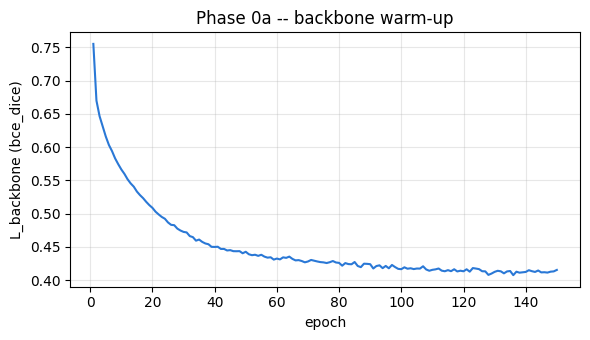

In [10]:
# ============================================================================================================
# 10. PHASE 0a -- backbone warm-up (resumable; or shared from another experiment)
# ============================================================================================================
warmup_optimizer = torch.optim.Adam(model.parameters(), lr=LR_WARMUP)
warmup_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(warmup_optimizer, T_max=BACKBONE_WARMUP_EPOCHS)

_p0a_ckpt, _p0a_shared = load_checkpoint(PATHS.ckpt.phase0a), False
if _p0a_ckpt is None and PATHS.shared_phase0a:
    _p0a_ckpt = load_checkpoint(PATHS.shared_phase0a)
    _p0a_shared = _p0a_ckpt is not None
backbone_warmup_losses, _p0a_start_epoch = [], 1
if _p0a_ckpt is not None:
    load_model_state(model, _p0a_ckpt['model_state'], skip_prefixes=('anfis_head.',))   # the head is still a placeholder
    apply_model_behaviour(model, _p0a_ckpt)
    backbone_warmup_losses = list(_p0a_ckpt.get('backbone_warmup_losses', []))
    if _p0a_shared:
        _p0a_start_epoch = BACKBONE_WARMUP_EPOCHS + 1
        log(f'[resume] backbone warm-up taken from experiment {SHARE_BACKBONE_FROM!r} '
            f'(epoch {_p0a_ckpt["epoch"]}, final loss {backbone_warmup_losses[-1] if backbone_warmup_losses else float("nan"):.4f}); '
            f'Phase 0a is skipped')
    else:
        warmup_optimizer.load_state_dict(_p0a_ckpt['optimizer_state'])
        if 'scheduler_state' in _p0a_ckpt:
            warmup_scheduler.load_state_dict(_p0a_ckpt['scheduler_state'])
        else:                                                  # older checkpoint: fast-forward the cosine schedule
            for _ in range(int(_p0a_ckpt['epoch'])):
                warmup_scheduler.step()
        _p0a_start_epoch = int(_p0a_ckpt['epoch']) + 1
        log(f'[resume] Phase 0a restored -- resuming at epoch {_p0a_start_epoch}')
        if RESTORE_RNG_ON_RESUME and '_rng' in _p0a_ckpt:
            restore_rng_state(_p0a_ckpt['_rng'])


def _aux_weight(epoch):
    """Deep-supervision weight: AUX_WEIGHT -> 0 linearly over the first AUX_ANNEAL_FRAC of the schedule."""
    if not USE_DEEP_SUPERVISION:
        return 0.0
    span = max(AUX_ANNEAL_FRAC * BACKBONE_WARMUP_EPOCHS, 1.0)
    return AUX_WEIGHT * max(0.0, 1.0 - (epoch - 1) / span)


log('=' * 100)
log(f'PHASE 0a -- backbone warm-up ({BACKBONE_WARMUP_EPOCHS} epochs, loss={LOSS_MODE}, lr={LR_WARMUP:g} cosine)')
log('=' * 100)
for epoch in range(_p0a_start_epoch, BACKBONE_WARMUP_EPOCHS + 1):
    model.train()
    running, aw = 0.0, _aux_weight(epoch)
    for imgs, masks, _ in tqdm(loader_train, desc=f'  warm-up {epoch}', leave=False):
        imgs, masks = imgs.to(DEVICE, non_blocking=True), masks.to(DEVICE, non_blocking=True)
        warmup_optimizer.zero_grad()
        out = model(imgs)
        l_main = criterion(torch.sigmoid(out.unet_logits), masks)
        loss = l_main
        if aw > 0 and model.aux_logits:
            loss = loss + aw * sum(criterion(torch.sigmoid(a), masks) for a in model.aux_logits)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        warmup_optimizer.step()
        model.aux_logits = []
        running += l_main.item()                                   # logged loss = main loss only
    ep_loss = running / len(loader_train)
    backbone_warmup_losses.append(ep_loss)
    log(f'  epoch {epoch:3d}/{BACKBONE_WARMUP_EPOCHS}  L_backbone = {ep_loss:.4f}  lr={warmup_optimizer.param_groups[0]["lr"]:.2e}')
    warmup_scheduler.step()
    save_checkpoint({'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': warmup_optimizer.state_dict(),
                     'scheduler_state': warmup_scheduler.state_dict(), 'backbone_warmup_losses': backbone_warmup_losses},
                    PATHS.ckpt.phase0a)

model.deep_supervision = False                                     # side heads are warm-up only
if backbone_warmup_losses:
    log(f'Backbone warm-up complete. Final L_backbone = {backbone_warmup_losses[-1]:.4f}')
    plt.figure(figsize=(6, 3.5)); plt.plot(range(1, len(backbone_warmup_losses) + 1), backbone_warmup_losses, color='#2a78d6', lw=1.5)
    plt.xlabel('epoch'); plt.ylabel(f'L_backbone ({LOSS_MODE})'); plt.title('Phase 0a -- backbone warm-up'); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f'{PATHS.figures}/phase0a_warmup_loss.png', dpi=150); plt.show(); plt.close()
del _p0a_ckpt

## 11. Phase 0b — FCM rule discovery and selection of $R^\*$

1. **Features.** With the warmed-up backbone in evaluation mode, `FCM_SAMPLE_PIXELS` training pixels are sampled (edge pixels over-sampled to `FCM_EDGE_FRACTION`); each gives $(x_1, z, y)$ = Sobel magnitude, backbone logit, annotator agreement. The antecedent temperature $T$ is fitted here once, from a natural (un-oversampled) sample of logits: the `X2_TEMP_QUANTILE`-th percentile of $z$ is mapped to $x_2^{(T)} = 0.05$.
2. **Clustering.** For every candidate $R$ and `FCM_SEEDS` seeds, FCM on $(x_1, x_2^{(T)})$ — either jointly or per GT stratum (`FCM_STRATIFIED`: edge and non-edge pixels clustered separately with $R$ split evenly, which prevents the rule budget from being spent twice on the background mode). **In both cases the Xie–Beni index is computed on the combined partition of all sampled pixels** (memberships of every pixel to every centre), so candidates are compared on the same footing. Seed stability is reported as the mean pairwise adjusted Rand index.
3. **Shortlist and scoring.** The `XB_SHORTLIST_TOP_K` best candidates by mean Xie–Beni index are each turned into a head (FCM centres and membership-weighted widths, the fitted $T$, the width ceiling, and the IRLS consequent start), their consequents alone are fine-tuned for `FCM_CANDIDATE_TRAIN_EPOCHS` epochs on cached training features, and they are scored on cached validation features with a tolerant-F proxy (dilation matching, thresholds down to $10^{-4}$). $R^\*$ is the smallest $R$ within `R_STAR_PARSIMONY_TOL` of the best score.
4. **Outputs.** The winning head replaces the placeholder; the rule-usage prior (target of the utilisation regulariser) and the $x_2$ drift references are recorded; everything is checkpointed. `FCM_FIXED_R` skips the sweep and `MF_INIT='grid'` skips FCM (ablations).

In [11]:
# ============================================================================================================
# 11. PHASE 0b -- FCM rule discovery, Xie-Beni + validation selection of R*, MF initialisation, consequent start
# ============================================================================================================
def proxy_ods_tolerant(prob_maps, gt_maps, tol_pix=None, n_thresh=None, return_counts=False):
    """Tolerance-dilation PROXY of the benchmark F-score, used only to rank candidate rule counts (no NMS, no 1:1
    matching). precision = |pred & dilate(GT)| / |pred|, recall = |GT & dilate(pred)| / |GT|, best over thresholds
    that reach 1e-4 (the backbone's operating point lies far below 0.05)."""
    tol_pix = PROXY_TOL_PIX if tol_pix is None else tol_pix
    n_thresh = PROXY_ODS_THRESHOLDS if n_thresh is None else n_thresh
    preds = [np.asarray(p.numpy() if hasattr(p, 'numpy') else p).squeeze() for p in prob_maps]
    gt_bins = [np.asarray(g.numpy() if hasattr(g, 'numpy') else g).squeeze() > 0.3 for g in gt_maps]
    gt_dils = [binary_dilation(g, iterations=tol_pix) for g in gt_bins]
    thresholds = np.unique(np.concatenate([np.geomspace(1e-4, 0.05, 13), np.linspace(0.05, 0.95, n_thresh)]))
    best_f, best_counts = 0.0, None
    for t in thresholds:
        n_pred = n_pred_ok = n_gt = n_gt_ok = 0
        for prob, gt_bin, gt_dil in zip(preds, gt_bins, gt_dils):
            pred_bin = prob > t
            pred_dil = binary_dilation(pred_bin, iterations=tol_pix)
            n_pred += int(pred_bin.sum()); n_pred_ok += int((pred_bin & gt_dil).sum())
            n_gt += int(gt_bin.sum()); n_gt_ok += int((gt_bin & pred_dil).sum())
        prec, rec = n_pred_ok / max(n_pred, 1), n_gt_ok / max(n_gt, 1)
        f = 2 * prec * rec / (prec + rec + 1e-12)
        if f > best_f:
            best_f, best_counts = f, (n_pred, n_pred_ok, n_gt, n_gt_ok)
    return (best_f, best_counts) if return_counts else best_f


# self-check: nine predictions around ONE detected GT pixel, a second GT pixel missed -> F = 2*1*0.5/1.5 = 0.6667
_pm = np.zeros((40, 40), np.float32); _pm[9:12, 9:12] = 0.9
_gm = np.zeros((40, 40), np.float32); _gm[10, 10] = 1.0; _gm[30, 30] = 1.0
_f = proxy_ods_tolerant([_pm], [_gm], tol_pix=2, n_thresh=21)
print(f'[self-check] proxy_ods_tolerant on the counterexample: F={_f:.4f} (expected 0.6667)' + ('  PASS' if abs(_f - 2 / 3) < 1e-3 else '   <-- WARNING'))
del _pm, _gm, _f


@torch.no_grad()
def cache_features(loader, desc, needs_padding):
    """Per-image CPU tensors (x1, x2, z, gt): the head's consequents use the REAL logits z, so they are cached too."""
    x1s, x2s, zs, gts = [], [], [], []
    for imgs, masks, _ in tqdm(loader, desc=desc, leave=False):
        imgs = imgs.to(DEVICE)
        if needs_padding:
            imgs_pad, H, W = pad_to_multiple(imgs, multiple=PAD_MULTIPLE)
            out = model(imgs_pad)
            x1, x2, z = out.x1[..., :H, :W], out.x2[..., :H, :W], out.unet_logits[..., :H, :W]
        else:
            out = model(imgs)
            x1, x2, z = out.x1, out.x2, out.unet_logits
        gt = F.interpolate(masks.to(DEVICE), size=x2.shape[-2:], mode='nearest')
        x1s.append(x1.cpu()); x2s.append(x2.cpu()); zs.append(z.cpu()); gts.append(gt.cpu())
    return x1s, x2s, zs, gts


@torch.no_grad()
def sample_fcm_features():
    """Sampled training pixels for FCM: (x1, z, gt) with the configured sampling mode, plus a NATURAL sample of
    logits (z_nat) for the antecedent temperature."""
    x1_l, z_l, gt_l, znat_l = [], [], [], []
    per_batch = max(1, FCM_SAMPLE_PIXELS // len(loader_train))
    rng, rng_nat = np.random.RandomState(SEED), np.random.RandomState(SEED + 1)
    for imgs, masks, _ in tqdm(loader_train, desc=f'  sampling pixels ({FCM_SAMPLING_MODE})', leave=False):
        out = model(imgs.to(DEVICE))
        gt = F.interpolate(masks.to(DEVICE), size=out.x2.shape[-2:], mode='nearest')
        x1f, x2f, gtf, zf = (t.flatten().cpu().numpy() for t in (out.x1, out.x2, gt, out.unet_logits))
        s1, _, sg, sz = sample_pixels(x1f, x2f, gtf, per_batch, FCM_SAMPLING_MODE, FCM_EDGE_FRACTION,
                                      FCM_EDGE_GT_THRESH, rng, extra=zf)
        x1_l.append(s1); z_l.append(sz); gt_l.append(sg)
        znat_l.append(zf[rng_nat.choice(len(zf), min(4096, len(zf)), replace=False)])
    return (np.concatenate(x1_l).astype(np.float32), np.concatenate(z_l).astype(np.float32),
            np.concatenate(gt_l).astype(np.float32), np.concatenate(znat_l).astype(np.float32))


def fit_x2_temperature(z_nat):
    """T such that the X2_TEMP_QUANTILE-th percentile of the backbone logit maps to sigmoid(z/T) = 0.05."""
    if not HEAD_LOGIT_CONSEQUENTS:
        return 1.0                                                  # the probability-mode head uses x2 itself
    if str(HEAD_X2_TEMPERATURE) == 'auto':
        q = float(np.percentile(z_nat, X2_TEMP_QUANTILE))
        return float(np.clip(-q / math.log(0.95 / 0.05), *X2_TEMP_RANGE))
    return float(HEAD_X2_TEMPERATURE)


def cluster_rules(X, Y_gt):
    """FCM for every candidate R (FCM_SEEDS seeds each) -> {R: dict(mean_xb, best_xb, centers, u, ari)}.
    Centres are found jointly or per GT stratum (FCM_STRATIFIED); the Xie-Beni index is ALWAYS computed on the
    combined partition of all sampled pixels (fcm_memberships of X to all R centres), so candidates and the two
    clustering modes are compared on the same footing. `u` [R,N] are the memberships of that combined partition."""
    edge_mask = Y_gt >= FCM_EDGE_GT_THRESH
    X_e, X_n = X[edge_mask], X[~edge_mask]
    if FCM_CONFIDENCE_FILTER:                                       # v10 behaviour: keep only confident pixels for FCM
        e_cut = np.percentile(X_e[:, 0], 100 - FCM_CONFIDENCE_PERCENTILE)
        n_cut = np.percentile(X_n[:, 0], FCM_CONFIDENCE_PERCENTILE)
        X_e, X_n = X_e[X_e[:, 0] >= e_cut], X_n[X_n[:, 0] <= n_cut]
        log(f'  confidence filter ON: edge x1 >= {e_cut:.3f}, non-edge x1 <= {n_cut:.3f}')
    log(f'  {len(X):,} sampled pixels: {edge_mask.sum():,} edge / {(~edge_mask).sum():,} non-edge; '
        f'clustering = {"stratified (R split evenly)" if FCM_STRATIFIED else "joint"}')
    results = {}
    for R in (FCM_CANDIDATE_R if FCM_FIXED_R is None else [FCM_FIXED_R]):
        xbs, labels, best = [], [], None
        for seed in range(FCM_SEEDS):
            if FCM_STRATIFIED and R >= 2:
                R_e = R // 2
                c_e, _ = fuzzy_c_means(X_e, R_e, m=FCM_M, max_iter=FCM_MAX_ITER, seed=seed)
                c_n, _ = fuzzy_c_means(X_n, R - R_e, m=FCM_M, max_iter=FCM_MAX_ITER, seed=seed)
                centers = np.vstack([c_e, c_n])
            else:
                centers, _ = fuzzy_c_means(X, R, m=FCM_M, max_iter=FCM_MAX_ITER, seed=seed)
            u = fcm_memberships(X, centers, m=FCM_M)
            xb = xie_beni_index(X, centers, u, m=FCM_M)
            xbs.append(xb); labels.append(u.argmax(axis=0))
            if best is None or xb < best[0]:
                best = (xb, centers, u)
        ari = float(np.mean([adjusted_rand_score(labels[i], labels[j])
                             for i in range(len(labels)) for j in range(i + 1, len(labels))])) if len(labels) > 1 else 1.0
        results[R] = dict(mean_xb=float(np.mean(xbs)), best_xb=float(best[0]), centers=best[1], u=best[2], ari=ari)
        log(f'    R={R:<3d}  Xie-Beni (combined partition): mean over seeds={np.mean(xbs):.5f}  best={best[0]:.5f}  '
            f'| seed stability ARI={ari:.3f}{"  <-- unstable" if ari < 0.5 else ""}')
    return results


def fcm_to_mf_init(centers, u, X):
    """Gaussian MF initialisation: centre = FCM centre, width = membership-weighted std per input (floored at 0.02)."""
    um = u ** FCM_M
    init_centers, init_sigmas = [], []
    for k in range(len(centers)):
        w = um[k].reshape(-1, 1)
        var_k = (w * (X - centers[k][None, :]) ** 2).sum(axis=0) / um[k].sum().clip(min=1e-8)
        sigma_k = np.sqrt(var_k).clip(min=0.02)
        init_centers.append((float(centers[k][0]), float(centers[k][1])))
        init_sigmas.append((float(sigma_k[0]), float(sigma_k[1])))
    return init_centers, init_sigmas


def make_candidate_head(R, fcm_result, X, temperature):
    if MF_INIT == 'fcm':
        ic, isg = fcm_to_mf_init(fcm_result['centers'], fcm_result['u'], X)
        head = ANFISFuzzyHead(R, ic, isg)
    else:
        head = ANFISFuzzyHead(R)                                    # grid centres, default widths (ablation)
    head = head.to(DEVICE)
    head.x2_temperature.fill_(temperature)                          # FCM ran in the tempered x2 space
    head.update_sigma_ceiling()                                     # candidates are scored with the ceiling they train with
    return head


def init_consequents(head, train_cache, X, Y_gt):
    if head.logit_consequents:
        if CONSEQUENT_INIT == 'irls':
            fit_consequents_irls(head, *train_cache, max_pixels=IRLS_MAX_PIXELS, ridge=IRLS_RIDGE, iters=IRLS_ITERS, seed=SEED)
        # 'identity': (0, 1, 0) from the constructor -- the head equals the backbone at the start
    else:
        y = np.clip(Y_gt, LSE_LOGIT_EPS, 1.0 - LSE_LOGIT_EPS)
        head.init_consequents_lse(X[:, 0], X[:, 1], np.log(y / (1.0 - y)).astype(np.float32), ridge=1e-2)


def score_candidate(head, train_cache, val_cache):
    """Consequent-only fine-tune on cached training features (premises frozen, so the score reflects the FCM
    geometry itself), then the tolerant-F proxy on cached validation features."""
    for rule in head.rules:
        for p in rule.parameters():
            p.requires_grad_(False)
    head.train()
    opt = torch.optim.Adam([head.consequents], lr=FCM_CANDIDATE_LR)
    for _ in range(FCM_CANDIDATE_TRAIN_EPOCHS):
        for x1_c, x2_c, z_c, gt_c in zip(*train_cache):
            x1_c, x2_c, z_c, gt_c = (t.to(DEVICE) for t in (x1_c, x2_c, z_c, gt_c))
            opt.zero_grad()
            prob, _ = head(x1_c, x2_c, z2=z_c)
            criterion(prob, gt_c).backward()
            opt.step()
    head.eval()
    probs, gts = [], []
    with torch.no_grad():
        for x1_c, x2_c, z_c, gt_c in zip(*val_cache):
            probs.append(head(x1_c.to(DEVICE), x2_c.to(DEVICE), z2=z_c.to(DEVICE))[0].cpu()); gts.append(gt_c)
    for p in head.parameters():
        p.requires_grad_(True)
    return proxy_ods_tolerant(probs, gts)


_phase0b_ckpt = load_checkpoint(PATHS.ckpt.phase0b)
if _phase0b_ckpt is None:
    log('=' * 100)
    log('PHASE 0b -- feature sampling, antecedent temperature, FCM + Xie-Beni, candidate scoring, R*')
    log('=' * 100)
    model.eval()
    _x1, _z, Y_gt, _z_nat = sample_fcm_features()
    X2_TEMPERATURE = fit_x2_temperature(_z_nat)
    _qz = np.percentile(_z_nat, [1, 5, 50, 95, 99])
    log(f'  backbone logit z on training pixels: q01={_qz[0]:.2f} q05={_qz[1]:.2f} median={_qz[2]:.2f} q95={_qz[3]:.2f} '
        f'q99={_qz[4]:.2f}  ->  x2 antecedent temperature T = {X2_TEMPERATURE:.3f}')
    _x2 = 1.0 / (1.0 + np.exp(-np.clip(_z.astype(np.float64), -20, 20) / X2_TEMPERATURE))
    X = np.stack([_x1, _x2.astype(np.float32)], axis=1).astype(np.float32)      # (x1, x2 antecedent)
    del _x1, _x2, _z, _z_nat

    if MF_INIT == 'fcm':
        log(f'\n  FCM sweep: R in {FCM_CANDIDATE_R if FCM_FIXED_R is None else [FCM_FIXED_R]} x {FCM_SEEDS} seeds')
        xb_results = cluster_rules(X, Y_gt)
        ranked = sorted(xb_results, key=lambda R: xb_results[R]['mean_xb'])
        shortlist = ranked[:XB_SHORTLIST_TOP_K] if FCM_FIXED_R is None else [FCM_FIXED_R]
        log(f'  Xie-Beni shortlist (top-{XB_SHORTLIST_TOP_K} by mean index): {shortlist}')
    else:
        xb_results, shortlist = {FCM_FIXED_R: None}, [FCM_FIXED_R]
        log(f'  MF_INIT = grid: no FCM; R = {FCM_FIXED_R} with default centres/widths')

    log('\n  Caching per-image (x1, x2, z, gt) features for candidate scoring...')
    train_cache = cache_features(loader_train, '  caching train', needs_padding=False)
    val_cache = cache_features(loader_val, '  caching val', needs_padding=True)

    log(f'\n  Scoring {shortlist}: {CONSEQUENT_INIT} start -> {FCM_CANDIDATE_TRAIN_EPOCHS}-epoch consequent fine-tune -> validation proxy')
    candidate_scores, candidate_heads = {}, {}
    for R in shortlist:
        head = make_candidate_head(R, xb_results[R], X, X2_TEMPERATURE)
        init_consequents(head, train_cache, X, Y_gt)
        candidate_scores[R] = score_candidate(head, train_cache, val_cache)
        candidate_heads[R] = head
        log(f'    R={R:<3d}  validation tolerant-F (proxy) = {candidate_scores[R]:.4f}')
    best_score = max(candidate_scores.values())
    eligible = sorted(R for R, s in candidate_scores.items() if s >= best_score - R_STAR_PARSIMONY_TOL)
    R_STAR = eligible[0]
    log(f'\n  best proxy = {best_score:.4f}; within {R_STAR_PARSIMONY_TOL} of it: {eligible}  ->  R* = {R_STAR}')

    winning_head = candidate_heads[R_STAR]
    model.rebuild_anfis_head(winning_head, device=DEVICE)
    model.anfis_head.update_sigma_ceiling()
    N_RULES = R_STAR
    log_rule_geometry(model.anfis_head, tag=' (Phase 0b, before training)')
    _theta = winning_head.consequents.detach().cpu().numpy()
    log(f'  {"rule":<6}{"c_x1":>8}{"c_x2":>8}{"sig_x1":>8}{"sig_x2":>8}{"p":>9}{"q":>9}{"r":>9}   (raw widths)')
    for k, rule in enumerate(winning_head.rules):
        log(f'  R{k + 1:<5}{rule.mf_x1.center.item():>8.3f}{rule.mf_x2.center.item():>8.3f}{rule.mf_x1.sigma.item():>8.3f}'
            f'{rule.mf_x2.sigma.item():>8.3f}{_theta[k, 0]:>9.3f}{_theta[k, 1]:>9.3f}{_theta[k, 2]:>9.3f}')

    with torch.no_grad():                                           # rule usage prior = mean firing on training crops
        _usage, _npx, _wbars = torch.zeros(R_STAR), 0, []
        for i, (x1_c, x2_c, z_c, _) in enumerate(zip(*train_cache)):
            _, wb = model.anfis_head(x1_c.to(DEVICE), x2_c.to(DEVICE), z2=z_c.to(DEVICE))
            _usage += wb.sum(dim=[0, 2, 3]).cpu(); _npx += wb.shape[0] * wb.shape[2] * wb.shape[3]
            if i < 20:
                _wbars.append(wb.cpu())
    RULE_USAGE_PRIOR = (_usage / max(_npx, 1)).numpy()
    _mw, _xw, _dp = rule_activation_diagnostics(_wbars)
    log('  rule usage prior (training crops): ' + '  '.join(f'R{k + 1}={100 * u:.1f}%' for k, u in enumerate(RULE_USAGE_PRIOR)))
    log('  dominance (argmax share):          ' + '  '.join(f'R{k + 1}={_dp[k]:.1f}%' for k in range(R_STAR))
        + ('   WARNING: one rule dominates > 95% of pixels' if _dp.max() > 95 else ''))

    # x2 drift references: TRAINING crops define the L_drift anchor; validation images are used for the report only
    x2_dist_before_train = torch.cat([t.flatten() for t in train_cache[1][:FEATURE_DRIFT_N_BATCHES]]).numpy()
    x2_dist_before = torch.cat([t.flatten() for t in val_cache[1][:FEATURE_DRIFT_N_BATCHES]]).numpy()
    log(f'  x2 references -- train (anchor): mean={x2_dist_before_train.mean():.4f} std={x2_dist_before_train.std():.4f}'
        f' | val (report): mean={x2_dist_before.mean():.4f} std={x2_dist_before.std():.4f}')
    save_checkpoint({'R_STAR': R_STAR, 'n_rules': winning_head.n_rules, 'anfis_head_state': winning_head.state_dict(),
                     'x2_dist_before': x2_dist_before, 'x2_dist_before_train': x2_dist_before_train,
                     'rule_usage_prior': RULE_USAGE_PRIOR, 'x2_temperature': X2_TEMPERATURE,
                     'candidate_scores': candidate_scores,
                     'xie_beni': {int(R): {k: v for k, v in r.items() if k in ('mean_xb', 'best_xb', 'ari')}
                                  for R, r in xb_results.items() if r is not None}},
                    PATHS.ckpt.phase0b)
    del X, Y_gt, train_cache, val_cache, candidate_heads, _wbars
    gc.collect()
else:
    R_STAR = int(_phase0b_ckpt['R_STAR'])
    N_RULES = R_STAR
    winning_head = build_head_for_restore(_phase0b_ckpt['n_rules'], _phase0b_ckpt['anfis_head_state'], device=DEVICE)
    model.rebuild_anfis_head(winning_head, device=DEVICE)
    model.anfis_head.update_sigma_ceiling()
    x2_dist_before = _phase0b_ckpt['x2_dist_before']
    x2_dist_before_train = _phase0b_ckpt.get('x2_dist_before_train')      # None for very old checkpoints
    RULE_USAGE_PRIOR = _phase0b_ckpt.get('rule_usage_prior')
    X2_TEMPERATURE = float(model.anfis_head.x2_temperature)
    log_rule_geometry(model.anfis_head, tag=' (Phase 0b, restored)')
    log(f'[resume] Phase 0b restored: R*={R_STAR}, T_x2={X2_TEMPERATURE:.3f}, usage prior='
        f'{"none" if RULE_USAGE_PRIOR is None else np.round(np.asarray(RULE_USAGE_PRIOR), 3)}')
    del _phase0b_ckpt
model.eval()

[self-check] proxy_ods_tolerant on the counterexample: F=0.6667 (expected 0.6667)  PASS
[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/phase0b_rstar_v12.pt
  [manifest] WARNING phase0b_rstar_v12.pt: configuration differs from the run that saved it:
     - SCALE_RANGE: saved=[0.6, 1.8] now=(0.6, 1.8)
  [rule geometry (Phase 0b, restored)] min pairwise centre dist=0.089 (R1-R6)  raw sigma: min=0.027 mean=0.086 max=0.143  effective sigma: mean=0.070 max=0.143  ceiling: min=0.045 mean=0.110  raw width exceeds ceiling on 4/8 rule(s)
[resume] Phase 0b restored: R*=8, T_x2=2.655, usage prior=[0.14  0.016 0.011 0.028 0.083 0.206 0.043 0.472]


sMoEUNet(
  (sobel): SobelEdgeDetector()
  (enc1): DoubleConv(
    (net): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (net): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (en

## 12. Stage A (head only) and Stage B (joint fine-tuning)

**Stage A** trains only the ANFIS parameters (consequents at `LR_ANFIS_STAGE_A`, membership functions at `LR_MF_STAGE_A`) with the backbone frozen — weights *and* BatchNorm statistics; a checksum over every frozen module proves it. Loss: the proposed objective on the head output + `LAMBDA_RULE_UTIL` · KL(usage prior ‖ batch usage).

**Stage B** optimises $\alpha L_{\text{backbone}} + (1-\alpha) L_{\text{ANFIS}} + \lambda_{\text{drift}} L_{\text{drift}} + \lambda_{\text{util}} L_{\text{util}}$ with gradual unfreezing: membership functions after `MF_FREEZE_EPOCHS`, encoder after `ENCODER_UNFREEZE_EPOCH` (at `LR_ENCODER`), decoder after `DECODER_UNFREEZE_EPOCH` (at `LR_DECODER`), and the $x_2$ head `unet_head` — the only producer of the feature the rules were fitted on — in its own parameter group at `LR_X2_HEAD` with the drift anchor active. BatchNorm statistics stay frozen (`STAGEB_FREEZE_BN`). Model selection: lowest validation loss at native resolution; early stopping after `PATIENCE` epochs; `ReduceLROnPlateau`. Per-epoch checkpoints; a finished run is not re-entered on resume.

The width ceiling is refreshed from the current centres every epoch; rule geometry, usage and the drift loss are logged periodically.

[drift anchor] x2 mean=0.0289 std=0.1314 (training crops)   [L_util target] KL to the Phase-0b usage prior
[checkpoint found] loading /kaggle/working/smoe_results_v4/checkpoints/training_state_v12.pt
  [manifest] WARNING training_state_v12.pt: configuration differs from the run that saved it:
     - SCALE_RANGE: saved=[0.6, 1.8] now=(0.6, 1.8)
[resume] training restored -- stage B, epoch 46, best val loss 0.4147
  [resume] RNG states restored
[resume] training had already finished (Stage-B epoch 46, patience 25/25): Stage B is not re-entered; the best weights are restored below
STAGE A -- head only (15 epochs): encoder, decoder and x2 head frozen (weights + BatchNorm statistics)
Stage A complete. Best val loss so far: 0.4147

STAGE B -- joint fine-tuning, up to 350 epochs, gradual unfreeze (patience 25)

Best val loss 0.4147 at global epoch 36 (best weights restored); weights checksum 48f6a53f894e
  [rule geometry (post-training, best weights)] min pairwise centre dist=0.079 (R1-R6)  r

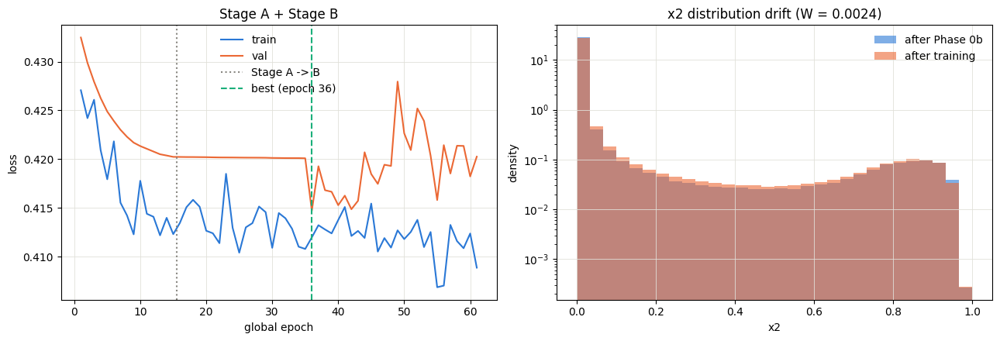

In [12]:
# ============================================================================================================
# 12. STAGE A / STAGE B TRAINING (resumable)
# ============================================================================================================
# ---- parameter groups ------------------------------------------------------------------------------------
_is_encoder = lambda n: n.startswith(('enc1', 'enc2', 'enc3', 'enc4', 'bot'))
_is_mf = lambda n: 'anfis_head' in n and ('center' in n or 'sigma' in n)
_is_anfis = lambda n: 'anfis_head' in n and not _is_mf(n)
_is_x2head = lambda n: n.startswith('unet_head')
encoder_params = [p for n, p in model.named_parameters() if _is_encoder(n)]
decoder_params = [p for n, p in model.named_parameters() if not (_is_encoder(n) or _is_anfis(n) or _is_mf(n) or _is_x2head(n))]
x2_head_params = [p for n, p in model.named_parameters() if _is_x2head(n)]
anfis_params = [p for n, p in model.named_parameters() if _is_anfis(n)]
mf_params = [p for n, p in model.named_parameters() if _is_mf(n)]
optimizer = torch.optim.Adam([
    {'params': encoder_params, 'lr': LR_ENCODER, 'name': 'encoder'},
    {'params': decoder_params, 'lr': LR_DECODER, 'name': 'decoder'},
    {'params': x2_head_params, 'lr': LR_X2_HEAD, 'name': 'x2_head'},
    {'params': anfis_params, 'lr': LR_ANFIS, 'name': 'anfis'},
    {'params': mf_params, 'lr': LR_ANFIS * MF_LR_MULTIPLIER, 'name': 'mf'},
])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=15,
                                                       min_lr=[1e-7, 1e-6, 1e-7, 5e-6, 1e-5])
encoder_modules = [model.enc1, model.enc2, model.enc3, model.enc4, model.bot]
decoder_modules = ([model.smoe2, model.smoe3, model.smoe4] if USE_SMOE else []) + \
                  [model.up4, model.dec4, model.up3, model.dec3, model.up2, model.dec2, model.up1, model.dec1, model.unet_head]

# ---- drift anchor (TRAINING crops only) and rule-utilisation target ----------------------------------------
if globals().get('x2_dist_before_train') is None:                  # very old Phase-0b checkpoint: recompute now
    with torch.no_grad():
        model.eval(); _ref = []
        for _i, (_imgs, _, _) in enumerate(loader_train):
            if _i >= FEATURE_DRIFT_N_BATCHES: break
            _ref.append(model(_imgs.to(DEVICE)).x2.flatten().cpu())
        x2_dist_before_train = torch.cat(_ref).numpy()
X2_MEAN_ANCHOR, X2_STD_ANCHOR = float(x2_dist_before_train.mean()), float(x2_dist_before_train.std())
_UTIL_PRIOR = None
if RULE_UTIL_TARGET == 'fcm_prior' and globals().get('RULE_USAGE_PRIOR') is not None:
    _UTIL_PRIOR = torch.as_tensor(np.asarray(RULE_USAGE_PRIOR), dtype=torch.float32, device=DEVICE)
log(f'[drift anchor] x2 mean={X2_MEAN_ANCHOR:.4f} std={X2_STD_ANCHOR:.4f} (training crops)   '
    f'[L_util target] {"uniform" if _UTIL_PRIOR is None else "KL to the Phase-0b usage prior"}')


def set_trainable(params, flag):
    for p in params:
        p.requires_grad = flag


def set_bn_mode(modules, train):
    for mod in modules:
        for m in mod.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.train(train)


def frozen_state_checksum():
    """md5 over parameters AND BatchNorm statistics of every module Stage A must not touch."""
    h = hashlib.md5()
    for m in encoder_modules + decoder_modules:
        for k, v in m.state_dict().items():
            h.update(k.encode()); h.update(v.detach().cpu().numpy().tobytes())
    return h.hexdigest()[:12]


def train_one_epoch_stage_a():
    model.train()
    set_bn_mode(encoder_modules + decoder_modules, train=False)
    running = 0.0
    for imgs, masks, _ in tqdm(loader_train, desc='  stage A', leave=False):
        imgs, masks = imgs.to(DEVICE, non_blocking=True), masks.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out.prob, masks) + LAMBDA_RULE_UTIL * rule_utilization_loss(out.rule_maps, prior=_UTIL_PRIOR)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        optimizer.step()
        running += loss.item()
    return running / len(loader_train)


def train_one_epoch_stage_b(encoder_frozen, drift_active):
    model.train()
    set_bn_mode(encoder_modules, train=not encoder_frozen)
    set_bn_mode(decoder_modules, train=drift_active)
    if STAGEB_FREEZE_BN:
        set_bn_mode(encoder_modules + decoder_modules, train=False)
    running = running_drift = running_util = 0.0
    for imgs, masks, _ in tqdm(loader_train, desc='  stage B', leave=False):
        imgs, masks = imgs.to(DEVICE, non_blocking=True), masks.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        out = model(imgs)
        l_backbone = criterion(torch.sigmoid(out.unet_logits), masks)
        l_anfis = criterion(out.prob, masks)
        l_drift = drift_loss(out.x2, X2_MEAN_ANCHOR, X2_STD_ANCHOR) if drift_active else torch.zeros((), device=DEVICE)
        l_util = rule_utilization_loss(out.rule_maps, prior=_UTIL_PRIOR)
        loss = ALPHA_BACKBONE * l_backbone + (1 - ALPHA_BACKBONE) * l_anfis + LAMBDA_DRIFT * l_drift + LAMBDA_RULE_UTIL * l_util
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP_NORM)
        optimizer.step()
        running += loss.item(); running_drift += l_drift.item(); running_util += l_util.item()
    n = len(loader_train)
    return running / n, running_drift / n, running_util / n


@torch.no_grad()
def validate_epoch():
    model.eval()
    running = 0.0
    for imgs, masks, _ in tqdm(loader_val, desc='  val', leave=False):
        running += criterion(predict_native(model, imgs, DEVICE, which='anfis'), masks.to(DEVICE, non_blocking=True)).item()
    return running / len(loader_val)


@torch.no_grad()
def print_rule_diagnostics(tag='', n_batches=15):
    model.eval(); wbars = []
    for i, (imgs, _, _) in enumerate(loader_val):
        if i >= n_batches: break
        imgs_pad, H, W = pad_to_multiple(imgs.to(DEVICE), multiple=PAD_MULTIPLE)
        wbars.append(model(imgs_pad).rule_maps[..., :H, :W].cpu())
    mean_w, _, dom_pct = rule_activation_diagnostics(wbars)
    log(f'  [rule diagnostics{tag}] ' + '  '.join(f'R{k + 1}: fire={mean_w[k]:.2f} dom={dom_pct[k]:.0f}%' for k in range(len(mean_w)))
        + ('   WARNING: one rule > 95% dominant' if dom_pct.max() > 95 else ''))


def _set_group_lr(name, lr):
    for g in optimizer.param_groups:
        if g.get('name') == name:
            g['lr'] = lr


def _save_training_state(stage, epoch, patience_ctr):
    save_checkpoint({'stage': stage, 'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
                     'scheduler_state': scheduler.state_dict(), 'train_losses': train_losses, 'val_losses': val_losses,
                     'best_val_loss': best_val_loss, 'best_epoch': best_epoch, 'patience_ctr': patience_ctr,
                     'best_state_dict': best_state_dict}, PATHS.ckpt.train)


# ---- resume ---------------------------------------------------------------------------------------------
_train_ckpt = load_checkpoint(PATHS.ckpt.train)
train_losses, val_losses, best_val_loss, best_epoch, best_state_dict = [], [], float('inf'), 0, None
_patience_resume, _stage_a_start, _stage_b_start = 0, 1, 1
if _train_ckpt is not None:
    load_model_state(model, _train_ckpt['model_state'])
    apply_model_behaviour(model, _train_ckpt)
    optimizer.load_state_dict(_train_ckpt['optimizer_state'])
    scheduler.load_state_dict(_train_ckpt['scheduler_state'])
    train_losses, val_losses = list(_train_ckpt['train_losses']), list(_train_ckpt['val_losses'])
    best_val_loss, best_epoch, best_state_dict = _train_ckpt['best_val_loss'], _train_ckpt['best_epoch'], _train_ckpt['best_state_dict']
    _patience_resume = int(_train_ckpt['patience_ctr'])
    if _train_ckpt['stage'] == 'A':
        _stage_a_start = int(_train_ckpt['epoch']) + 1
    else:
        _stage_a_start, _stage_b_start = FROZEN_BASELINE_EPOCHS + 1, int(_train_ckpt['epoch']) + 1
    log(f'[resume] training restored -- stage {_train_ckpt["stage"]}, epoch {_train_ckpt["epoch"]}, best val loss {best_val_loss:.4f}')
    if RESTORE_RNG_ON_RESUME and '_rng' in _train_ckpt:
        restore_rng_state(_train_ckpt['_rng'])
    if _train_ckpt['stage'] == 'B' and (_patience_resume >= PATIENCE or int(_train_ckpt['epoch']) >= MAX_EPOCHS):
        log(f'[resume] training had already finished (Stage-B epoch {_train_ckpt["epoch"]}, patience {_patience_resume}/{PATIENCE}): '
            'Stage B is not re-entered; the best weights are restored below')
        _stage_b_start = MAX_EPOCHS + 1
del _train_ckpt

# ---- STAGE A ---------------------------------------------------------------------------------------------
log('=' * 100)
log(f'STAGE A -- head only ({FROZEN_BASELINE_EPOCHS} epochs): encoder, decoder and x2 head frozen (weights + BatchNorm statistics)')
log('=' * 100)
set_trainable(encoder_params + decoder_params + x2_head_params, False)
set_trainable(anfis_params + mf_params, True)
_stage_a_runs = _stage_a_start <= FROZEN_BASELINE_EPOCHS
if _stage_a_runs:
    _frozen_before = frozen_state_checksum()
    _set_group_lr('anfis', LR_ANFIS_STAGE_A); _set_group_lr('mf', LR_MF_STAGE_A)
    log(f'  head LR: consequents {LR_ANFIS_STAGE_A:g}, membership functions {LR_MF_STAGE_A:g}')
for epoch in range(_stage_a_start, FROZEN_BASELINE_EPOCHS + 1):
    model.anfis_head.update_sigma_ceiling()
    tl = train_one_epoch_stage_a(); vl = validate_epoch()
    train_losses.append(tl); val_losses.append(vl)
    log(f'  [stage A] epoch {epoch:3d}/{FROZEN_BASELINE_EPOCHS}  train={tl:.4f}  val={vl:.4f}')
    if epoch == _stage_a_start:                                     # fail fast if the freeze is broken
        assert frozen_state_checksum() == _frozen_before, 'Stage A changed frozen modules during its first epoch'
    if vl < best_val_loss:
        best_val_loss, best_epoch, best_state_dict = vl, len(train_losses), copy.deepcopy(model.state_dict())
    _save_training_state('A', epoch, 0)
if _stage_a_runs:
    assert frozen_state_checksum() == _frozen_before, 'Stage A modified frozen modules: the freeze is broken'
    log(f'[stage A check] frozen modules unchanged (checksum {_frozen_before})  PASS')
log(f'Stage A complete. Best val loss so far: {best_val_loss:.4f}')

# ---- STAGE B ---------------------------------------------------------------------------------------------
log('\n' + '=' * 100)
log(f'STAGE B -- joint fine-tuning, up to {MAX_EPOCHS} epochs, gradual unfreeze (patience {PATIENCE})')
log('=' * 100)
set_trainable(decoder_params + x2_head_params, False)
set_trainable(anfis_params, True)
patience_ctr = _patience_resume
if _stage_b_start == 1:
    _set_group_lr('anfis', LR_ANFIS); _set_group_lr('mf', LR_ANFIS * MF_LR_MULTIPLIER)
    log(f'  MF frozen for epochs 1-{MF_FREEZE_EPOCHS}; encoder frozen for 1-{ENCODER_UNFREEZE_EPOCH} (then lr {LR_ENCODER:g}); '
        f'decoder frozen for 1-{DECODER_UNFREEZE_EPOCH} (then lr {LR_DECODER:g}); x2 head then lr {LR_X2_HEAD:g} with L_drift '
        f'(lambda {LAMBDA_DRIFT}); BatchNorm statistics frozen: {STAGEB_FREEZE_BN}')
for epoch in range(_stage_b_start, MAX_EPOCHS + 1):
    encoder_frozen, decoder_frozen = epoch <= ENCODER_UNFREEZE_EPOCH, epoch <= DECODER_UNFREEZE_EPOCH
    set_trainable(mf_params, epoch > MF_FREEZE_EPOCHS)
    set_trainable(encoder_params, not encoder_frozen)
    set_trainable(decoder_params + x2_head_params, not decoder_frozen)
    model.anfis_head.update_sigma_ceiling()
    if epoch == ENCODER_UNFREEZE_EPOCH + 1: log(f'  >>> encoder unfrozen at Stage-B epoch {epoch}')
    if epoch == DECODER_UNFREEZE_EPOCH + 1: log(f'  >>> decoder + x2 head unfrozen at Stage-B epoch {epoch} (L_drift active)')
    tl, drift_avg, util_avg = train_one_epoch_stage_b(encoder_frozen, drift_active=not decoder_frozen)
    vl = validate_epoch()
    train_losses.append(tl); val_losses.append(vl)
    scheduler.step(vl)
    if vl < best_val_loss:
        best_val_loss, best_epoch, patience_ctr = vl, len(train_losses), 0
        best_state_dict = copy.deepcopy(model.state_dict())
        status = 'BEST'
    else:
        patience_ctr += 1
        status = f'patience {patience_ctr}/{PATIENCE}'
    _save_training_state('B', epoch, patience_ctr)
    if epoch % 10 == 0 or epoch == 1:
        lrs = ' '.join(f'{g["name"]}={g["lr"]:.1e}' for g in optimizer.param_groups)
        log(f'  [stage B] epoch {epoch:4d}  train={tl:.4f}  val={vl:.4f}  {lrs}  {status}')
    if not decoder_frozen and epoch % DRIFT_REPORT_EVERY_N_EPOCHS == 0:
        log(f'  [drift anchor] epoch {epoch:4d}  L_drift={drift_avg:.5f}')
    if epoch % RULE_DIAG_EVERY_N_EPOCHS == 0:
        print_rule_diagnostics(tag=f' @ Stage-B epoch {epoch}')
        log_rule_geometry(model.anfis_head, tag=f' @ Stage-B epoch {epoch}')
        log(f'  [rule-util loss] epoch {epoch:4d}  L_util={util_avg:.4f}')
    if patience_ctr >= PATIENCE:
        log(f'\nEarly stopping at Stage-B epoch {epoch}')
        break

# ---- best weights, drift report, curves ------------------------------------------------------------------
if best_state_dict is not None:
    load_model_state(model, best_state_dict)
model.eval()                                                        # BatchNorm must not see validation batches below
_checksum = hashlib.md5(b''.join(p.detach().cpu().numpy().tobytes() for p in model.parameters())).hexdigest()[:12]
log(f'\nBest val loss {best_val_loss:.4f} at global epoch {best_epoch} (best weights restored); weights checksum {_checksum}')
log_rule_geometry(model.anfis_head, tag=' (post-training, best weights)')
log('ANFIS consequents (p, q, r) per rule:\n' + np.array2string(model.anfis_head.consequents.detach().cpu().numpy(), precision=4))

with torch.no_grad():
    _after = []
    for _i, (_imgs, _, _) in enumerate(loader_val):
        if _i >= FEATURE_DRIFT_N_BATCHES: break
        _ip, _H, _W = pad_to_multiple(_imgs.to(DEVICE), multiple=PAD_MULTIPLE)
        _after.append(model(_ip).x2[..., :_H, :_W].cpu().flatten())
x2_dist_after = torch.cat(_after).numpy()
w_dist = wasserstein_distance(x2_dist_before, x2_dist_after)
log('\nFEATURE-DRIFT REPORT -- x2 = sigmoid(unet_logits) on validation images, after Phase 0b vs after training')
log(f'  before: mean={x2_dist_before.mean():.4f} std={x2_dist_before.std():.4f}   after: mean={x2_dist_after.mean():.4f} '
    f'std={x2_dist_after.std():.4f}   Wasserstein distance={w_dist:.4f}'
    + ('   NOTE: noticeable drift of the feature the rules were fitted on' if w_dist > 0.05 else ''))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, len(train_losses) + 1), train_losses, color='#2a78d6', lw=1.5, label='train')
axes[0].plot(range(1, len(val_losses) + 1), val_losses, color='#eb6834', lw=1.5, label='val')
axes[0].axvline(FROZEN_BASELINE_EPOCHS + 0.5, color='#898781', ls=':', label='Stage A -> B')
axes[0].axvline(best_epoch, color='#1baf7a', ls='--', label=f'best (epoch {best_epoch})')
axes[0].set(xlabel='global epoch', ylabel='loss', title='Stage A + Stage B'); axes[0].legend(frameon=False); axes[0].grid(color='#e1e0d9', lw=0.6)
axes[1].hist(x2_dist_before, bins=30, range=(0, 1), color='#2a78d6', alpha=0.6, density=True, label='after Phase 0b')
axes[1].hist(x2_dist_after, bins=30, range=(0, 1), color='#eb6834', alpha=0.6, density=True, label='after training')
axes[1].set(xlabel='x2', ylabel='density', title=f'x2 distribution drift (W = {w_dist:.4f})', yscale='log'); axes[1].legend(frameon=False); axes[1].grid(color='#e1e0d9', lw=0.6)
plt.tight_layout(); plt.savefig(f'{PATHS.figures}/training_curves_and_drift.png', dpi=150); plt.show(); plt.close()

## 13. Benchmark — the BSDS500 reference pipeline

Every reported number comes from the **pyEdgeEval** reference implementation (a Python/Cython port of the Berkeley benchmark) running in a private Python 3.8 environment, driven as a subprocess with one worker per CPU core:

8-bit PNG → toolbox NMS (Dollár `edgesNms`) → 99 thresholds $0.01 \ldots 0.99$ → Berkeley thinning → C++ `correspondPixels` against **every annotator** (tolerance $0.0075 \times$ image diagonal) → per-image counts.

Aggregation follows `collect_eval_bdry.m` literally: **ODS** = best F on the pooled PR curve with MATLAB's `maxF` segment interpolation, **OIS** = pooled counts at each image's first best threshold, **AP** = `Area_PR` (precision interpolated over the unique recalls on $0{:}0.01{:}1$, missing recalls count 0). Two independent ports (the MATLAB code and pyEdgeEval's own aggregation) cross-check `ref_aggregate` on every set of counts. Per-image counts are cached on disk, keyed by the exact PNG bytes, so a session limit never loses finished work and every number is reproducible from the cache (the C++ matcher is clock-seeded; re-scoring an identical map can move counts by ~$10^{-3}$).

In [13]:
# ============================================================================================================
# 13. BENCHMARK BRIDGE -- pyEdgeEval (Python 3.8 conda env) as a parallel, cached, resumable subprocess
# ============================================================================================================
import subprocess, stat, pickle, signal, concurrent.futures

_CONDA_DIR = '/kaggle/working/miniconda3' if os.path.isdir('/kaggle/working') else os.path.join(WORK_DIR, 'miniconda3')
_CONDA = f'{_CONDA_DIR}/bin/conda'
_CONDA_PY38 = f'{_CONDA_DIR}/envs/edge_eval/bin/python'
_PY38_PKGS = ['pyEdgeEval==0.1.3', 'opencv-python', 'numpy', 'tqdm', 'scikit-image']   # scikit-image: imported by bsds.py


def _n_cpus():
    try:
        return len(os.sched_getaffinity(0))
    except AttributeError:
        return os.cpu_count() or 1


# ---- environment provisioning (Linux) ----------------------------------------------------------------------
def _path_kind(path):
    try:
        st = os.lstat(path)
    except OSError:
        return 'missing'
    if stat.S_ISLNK(st.st_mode):
        return 'file' if os.path.exists(path) else 'dangling'
    return 'file' if stat.S_ISREG(st.st_mode) else 'other'


def _is_usable(path):
    return _path_kind(path) == 'file' and os.access(path, os.X_OK)


def _run(cmd, **kw):
    r = subprocess.run(cmd, capture_output=True, text=True, **kw)
    if r.returncode != 0:
        print('CMD FAILED:', ' '.join(cmd)); print(r.stdout[-3000:]); print(r.stderr[-3000:])
        raise RuntimeError(f'command failed: {cmd[0]} ... (rc={r.returncode})')
    return r


def _probe(path, args=('--version',)):
    try:
        r = subprocess.run([path, *args], capture_output=True, text=True)
    except OSError as e:
        return False, '', f'{type(e).__name__}: {e}'
    return (r.returncode == 0), r.stdout.strip(), r.stderr.strip()[-500:]


def _install_miniconda():
    log(f'[pyEdgeEval] installing Miniconda under {_CONDA_DIR}')
    _run(['wget', '-q', 'https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh', '-O', '/tmp/miniconda.sh'])
    _run(['bash', '/tmp/miniconda.sh', '-b', '-p', _CONDA_DIR])


def _repair_or_install_miniconda():
    kind = _path_kind(_CONDA)
    if kind in ('dangling', 'missing'):
        if kind == 'dangling':
            shutil.rmtree(_CONDA_DIR, ignore_errors=True)
        _install_miniconda(); return
    if not os.access(_CONDA, os.X_OK):
        try:
            os.chmod(_CONDA, os.stat(_CONDA).st_mode | stat.S_IXUSR | stat.S_IXGRP | stat.S_IXOTH)
        except OSError:
            shutil.rmtree(_CONDA_DIR, ignore_errors=True); _install_miniconda(); return
    ok, out, err = _probe(_CONDA)
    if ok:
        log(f'[pyEdgeEval] conda usable: {out}'); return
    log(f'[pyEdgeEval] conda not runnable ({err}) -> wipe + reinstall')
    shutil.rmtree(_CONDA_DIR, ignore_errors=True); _install_miniconda()
    ok, out, err = _probe(_CONDA)
    if not ok:
        raise RuntimeError(f'Miniconda install failed: conda still not runnable ({err})')


def _py38_ready():
    return _is_usable(_CONDA_PY38) and _probe(_CONDA_PY38, args=('-c', 'from pyEdgeEval.datasets.bsds import bsds_eval_single'))[0]


def _provision_py38():
    _repair_or_install_miniconda()
    env = dict(os.environ, CONDA_PLUGINS_AUTO_ACCEPT_TOS='yes')
    subprocess.run([_CONDA, 'tos', 'accept', '--override-channels', '--channel', 'https://repo.anaconda.com/pkgs/main',
                    '--channel', 'https://repo.anaconda.com/pkgs/r'], capture_output=True, text=True, env=env)
    if not _is_usable(_CONDA_PY38):
        log('[pyEdgeEval] creating the Python 3.8 env (conda-forge first, defaults fallback)')
        r = subprocess.run([_CONDA, 'create', '-n', 'edge_eval', 'python=3.8', '-c', 'conda-forge', '-y'],
                           capture_output=True, text=True, env=env)
        if r.returncode != 0:
            _run([_CONDA, 'create', '-n', 'edge_eval', 'python=3.8', '-y'], env=env)
    log(f'[pyEdgeEval] installing/verifying {_PY38_PKGS} in edge_eval')
    _run([_CONDA, 'run', '-n', 'edge_eval', 'pip', 'install', '-q', *_PY38_PKGS], env=env)
    if not _py38_ready():
        ok, out, err = _probe(_CONDA_PY38, args=('-c', 'from pyEdgeEval.datasets.bsds import bsds_eval_single'))
        print(out); print(err)
        raise RuntimeError('the pyEdgeEval env is not importable after install; see the output above')


def ensure_bench_env():
    if _py38_ready():
        log(f'[pyEdgeEval] OK: {_CONDA_PY38}')
    else:
        _provision_py38()
        log(f'[pyEdgeEval] provisioned: {_CONDA_PY38}')


# ---- streaming subprocess driver (runs INSIDE the Python 3.8 env) ------------------------------------------
#   stdin : pickle {'jobs': [...], 'nproc': n}; stdout: one "PROGRESS i/N <ok|skipped|failed>" line per image;
#   files : each image's counts -> <cache>.npz (temp name + os.replace: never half-written); stderr -> log file.
#   A job whose deadline has passed is skipped (not started), so a long run stops cleanly before a session limit.
_PY38_DRIVER = r"""
import sys, os, time, pickle, traceback, ctypes, signal
import numpy as np
from concurrent.futures import ProcessPoolExecutor, as_completed
from pyEdgeEval.datasets.bsds import bsds_eval_single

def _die_with_parent():
    try: ctypes.CDLL('libc.so.6').prctl(1, int(signal.SIGKILL))
    except Exception: pass

_KEYS = ('count_r', 'sum_r', 'count_p', 'sum_p')

def _normalise(name, r):
    if isinstance(r, dict):
        if all(k in r for k in _KEYS):
            return {k: r[k] for k in _KEYS}
        raise TypeError(f"bsds_eval_single returned dict with keys {sorted(r.keys())}")
    if isinstance(r, (tuple, list)) and len(r) >= 4:
        return dict(zip(_KEYS, r[:4]))
    raise TypeError(f"bsds_eval_single returned unexpected type {type(r)} repr={repr(r)[:300]}")

def _one(job):
    if job.get('deadline') and time.time() > job['deadline']:
        return job['name'], 'skipped'
    try:
        r = _normalise(job['name'], bsds_eval_single(job))
        tmp = job['cache'][:-4] + '.tmp.npz'
        np.savez(tmp, **{k: np.asarray(v, dtype=np.float64) for k, v in r.items()})
        os.replace(tmp, job['cache'])
        return job['name'], 'ok'
    except Exception:
        return job['name'], traceback.format_exc()

def main():
    _die_with_parent()
    inp = pickle.load(sys.stdin.buffer)
    jobs, n, bad = inp['jobs'], len(inp['jobs']), 0
    with ProcessPoolExecutor(max_workers=inp['nproc'], initializer=_die_with_parent) as ex:
        futs = [ex.submit(_one, j) for j in jobs]
        try:
            for i, fut in enumerate(as_completed(futs), 1):
                name, st = fut.result()
                if st not in ('ok', 'skipped'):
                    bad += 1; sys.stderr.write(f"FAILED {name}\n{st}\n"); st = 'failed'
                sys.stdout.write(f"PROGRESS {i}/{n} {st}\n"); sys.stdout.flush()
        except BrokenPipeError:
            for f in futs: f.cancel()
            os._exit(2)
    sys.exit(1 if bad else 0)

if __name__ == '__main__':
    main()
"""


class BenchIncomplete(RuntimeError):
    """Some images were not evaluated (deadline reached). Their counts are NOT lost: re-run to resume."""


BENCH_THR = np.linspace(1.0 / (BENCH_NTHRESH + 1), 1.0 - 1.0 / (BENCH_NTHRESH + 1), BENCH_NTHRESH)
BENCH_CACHE_DIR = PATHS.bench_cache
BENCH_NPROC = _n_cpus()
BENCH_DEADLINE = None                                   # unix time; set in the evaluation cell. No image is STARTED after it.
BENCH_THROUGHPUT = {}                                   # wall seconds per newly matched image at BENCH_NPROC
_BENCH_KEYS = ('count_r', 'sum_r', 'count_p', 'sum_p')
EVALUATOR_CONFIG = dict(reference='pyEdgeEval==0.1.3 (bsds_eval_single)', thresholds=BENCH_NTHRESH, max_dist=BENCH_MAX_DIST,
                        thinning=True, nms='pyEdgeEval fast_nms r=1 s=5 m=1.01 (Dollar edgesNms) when apply_nms',
                        png='8-bit, round(clip(p)*255)', ODS='collect_eval_bdry.m maxF (linspace(0,1) = 100 points)',
                        OIS="pooled counts at each image's first best threshold",
                        AP='BSDS Area_PR (interp1 on unique R, 0:0.01:1, NaN -> 0)')


def _run_py38(jobs):
    logf = os.path.join(BENCH_CACHE_DIR, 'matcher_stderr.log')
    env = dict(os.environ, OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1')
    n_total, n_ok, n_skip, t0 = len(jobs), 0, 0, time.time()
    bar = tqdm(total=n_total, desc=f'  matching {n_total} maps on {BENCH_NPROC} proc', unit='img', leave=False, ncols=100)
    with open(logf, 'a') as ferr:
        proc = subprocess.Popen([_CONDA_PY38, '-c', _PY38_DRIVER], stdin=subprocess.PIPE, stdout=subprocess.PIPE,
                                stderr=ferr, bufsize=0, env=env, start_new_session=True)
        try:
            proc.stdin.write(pickle.dumps({'jobs': jobs, 'nproc': BENCH_NPROC})); proc.stdin.close()
            for raw in iter(proc.stdout.readline, b''):
                line = raw.decode('ascii', errors='replace').strip()
                if line.startswith('PROGRESS '):
                    st = line.split()[2]; n_ok += st == 'ok'; n_skip += st == 'skipped'; bar.update(1)
                elif line:
                    print('[py38 stdout]', line, flush=True)
            rc = proc.wait()
        finally:
            bar.close()
            if proc.poll() is None:
                os.killpg(proc.pid, signal.SIGKILL)
    if n_ok:
        BENCH_THROUGHPUT.update(s_per_img=(time.time() - t0) / n_ok, nproc=BENCH_NPROC)
        with open(os.path.join(BENCH_CACHE_DIR, 'throughput.json'), 'w') as f:
            json.dump(BENCH_THROUGHPUT, f)
    if rc != 0:
        with open(logf) as f:
            sys.stderr.write(f.read()[-6000:])
        raise RuntimeError(f'pyEdgeEval subprocess failed (rc={rc}); {n_ok}/{n_total} images finished and are cached. Log: {logf}')
    return n_ok, n_skip


# ---- maps, cache, counts ------------------------------------------------------------------------------------
def logit_affine(p, T=1.0, c=0.0):
    """p' = sigmoid(logit(p) / T + c): monotone, image-independent. T = 1, c = 0 returns the map unchanged."""
    if T == 1.0 and c == 0.0:
        return p
    q = np.clip(p.astype(np.float64), 1e-6, 1 - 1e-6)
    return (1.0 / (1.0 + np.exp(-(np.log(q / (1 - q)) / T + c)))).astype(np.float32)


def write_pngs(preds, out_dir, T=1.0, c=0.0):
    os.makedirs(out_dir, exist_ok=True)
    for prob, stem, _ in preds:
        cv2.imwrite(os.path.join(out_dir, f'{stem}.png'), np.round(np.clip(logit_affine(prob, T, c), 0, 1) * 255).astype(np.uint8))
    return [s for _, s, _ in preds]


def _cache_path(split, stem, png, apply_nms, apply_thinning):
    with open(png, 'rb') as f:
        key = hashlib.md5(f.read() + repr((BENCH_NTHRESH, BENCH_MAX_DIST, apply_nms, apply_thinning, split, stem)).encode())
    return os.path.join(BENCH_CACHE_DIR, split, f'{stem}_{key.hexdigest()[:16]}.npz')


def _load_counts(path):
    try:
        with np.load(path) as z:
            return {k: z[k].astype(np.float64) for k in _BENCH_KEYS}
    except Exception:
        return None


def ref_image_counts(pred_dir, split, stems, apply_nms=True, apply_thinning=True):
    gt_dir = os.path.join(BSR_ROOT, 'data', 'groundTruth', split)
    paths = {s: _cache_path(split, s, os.path.join(pred_dir, f'{s}.png'), apply_nms, apply_thinning) for s in stems}
    todo = [s for s in stems if _load_counts(paths[s]) is None]
    os.makedirs(os.path.join(BENCH_CACHE_DIR, split), exist_ok=True)
    if todo:
        log(f'  [bench cache] {len(stems) - len(todo)}/{len(stems)} images already scored; matching {len(todo)} on {BENCH_NPROC} processes')
        _run_py38([dict(name=f'{split}/{s}', thresholds=BENCH_NTHRESH, gt_path=os.path.join(gt_dir, f'{s}.mat'),
                        pred_path=os.path.join(pred_dir, f'{s}.png'), scale=1.0, max_dist=BENCH_MAX_DIST,
                        apply_thinning=apply_thinning, apply_nms=apply_nms, cache=paths[s], deadline=BENCH_DEADLINE)
                   for s in todo])
    res = [_load_counts(paths[s]) for s in stems]
    miss = [s for s, r in zip(stems, res) if r is None]
    if miss:
        raise BenchIncomplete(f'{len(miss)}/{len(stems)} images not scored yet (deadline reached); the other '
                              f'{len(stems) - len(miss)} are cached in {BENCH_CACHE_DIR} -- re-run to resume')
    cr, sr, cp, sp = (np.stack([r[k] for r in res]) for k in _BENCH_KEYS)
    assert cr.shape == (len(stems), BENCH_NTHRESH), cr.shape
    assert (cr <= sr).all() and (cp <= sp).all() and (sr > 0).all(), 'inconsistent per-image counts'
    return cr, sr, cp, sp


# ---- aggregation (BSDS collect_eval_bdry.m definitions) ---------------------------------------------------
def _f1(p, r):
    return 2.0 * p * r / (p + r + ((p + r) == 0))


def _maxF(T, R, P):
    """MATLAB maxF: best F on the segments between consecutive thresholds, d = linspace(0,1) (100 points)."""
    D = np.linspace(0, 1, 100)[None, :]
    t, r, p = (A[1:, None] * D + A[:-1, None] * (1 - D) for A in (T, R, P))
    f = _f1(p, r); k = np.unravel_index(int(np.argmax(f)), f.shape)
    f0 = _f1(P[0], R[0])
    return (T[0], R[0], P[0], f0) if f0 >= f[k] else (t[k], r[k], p[k], f[k])


def _area_pr(R, P):
    """BSDS Area_PR: [Ru,indR]=unique(R); interp1(Ru, P(indR), 0:0.01:1), NaN -> 0, sum * 0.01."""
    ru, ix = np.unique(R, return_index=True)
    if len(ru) < 2:
        return 0.0
    return float(np.interp(np.linspace(0, 1, 101), ru, P[ix], left=0.0, right=0.0).sum() * 0.01)


def ref_aggregate(cr, sr, cp, sp):
    rec = cr.sum(0) / (sr.sum(0) + (sr.sum(0) == 0))
    prec = cp.sum(0) / (sp.sum(0) + (sp.sum(0) == 0))
    best_t, _, _, ods = _maxF(BENCH_THR, rec, prec)
    ri = cr / (sr + (sr == 0)); pi = cp / (sp + (sp == 0)); fi = _f1(pi, ri)
    b = fi.argmax(1); n = np.arange(len(b))
    c_r, s_r, c_p, s_p = cr[n, b].sum(), sr[n, b].sum(), cp[n, b].sum(), sp[n, b].sum()
    ois = float(_f1(c_p / (s_p + (s_p == 0)), c_r / (s_r + (s_r == 0))))
    ap_env = float(sum(np.max(prec[rec >= t], initial=0) for t in np.arange(0, 1, 0.01)) / 101)   # pyEdgeEval's 'AP'
    return dict(ODS=float(ods), OIS=ois, AP=_area_pr(rec, prec), AP_env=ap_env, best_t=float(best_t),
                max_recall=float(rec.max()), min_recall=float(rec.min()), counts=(cr, sr, cp, sp))


def _bench_boot(res, idx):
    cr, sr, cp, sp = res['counts']; r = ref_aggregate(cr[idx], sr[idx], cp[idx], sp[idx])
    return r['ODS'], r['OIS'], r['AP']


def bench_ci(res, n_boot=1000, seed=0, alpha=0.05):
    N = len(res['counts'][0]); rng = np.random.RandomState(seed)
    out = np.array([_bench_boot(res, rng.randint(0, N, N)) for _ in range(n_boot)])
    q = lambda v: (float(np.percentile(v, 100 * alpha / 2)), float(np.percentile(v, 100 * (1 - alpha / 2))))
    return dict(ODS=q(out[:, 0]), OIS=q(out[:, 1]), AP=q(out[:, 2]))


def bench_diff(res_a, res_b, n_boot=1000, seed=0, alpha=0.05):
    """Paired bootstrap over the SAME images: a - b for ODS / OIS / AP with 95% intervals."""
    N = len(res_a['counts'][0]); rng = np.random.RandomState(seed); d = []
    for _ in range(n_boot):
        idx = rng.randint(0, N, N)
        d.append(np.array(_bench_boot(res_a, idx)) - np.array(_bench_boot(res_b, idx)))
    d = np.array(d)
    q = lambda v: (float(np.percentile(v, 100 * alpha / 2)), float(np.percentile(v, 100 * (1 - alpha / 2))))
    return {k: dict(mean=float(d[:, i].mean()), ci=q(d[:, i])) for i, k in enumerate(('ODS', 'OIS', 'AP'))}


def bench_eval(preds, split, T=1.0, c=0.0, apply_nms=True, tag='tmp', keep_pngs=False, with_ci=True):
    """Write the (calibrated) 8-bit maps, score them through the reference matcher (cached), aggregate."""
    d = os.path.join(PATHS.maps, tag, split)
    stems = write_pngs(preds, d, T, c)
    res = ref_aggregate(*ref_image_counts(d, split, stems, apply_nms=apply_nms))
    res.update(T=float(T), c=float(c), apply_nms=bool(apply_nms), split=split, png_dir=d, n_images=len(stems))
    if with_ci and EVAL_BOOTSTRAP > 0:
        res['ci'] = bench_ci(res, EVAL_BOOTSTRAP)
    if not keep_pngs:
        shutil.rmtree(d, ignore_errors=True)
    return res


# ---- independent ports used to cross-check ref_aggregate on real counts ------------------------------------
def pyedgeeval_reference_aggregate(count_r, sum_r, count_p, sum_p):
    """Literal port of pyEdgeEval.common.binary_label.calculate_metrics (shares no code with ref_aggregate)."""
    T = count_r.shape[1]
    f1 = lambda p, r: 2.0 * p * r / (p + r + ((p + r) == 0))
    rc = lambda c, s: c / (s + (s == 0))
    cr_o, sr_o, cp_o, sp_o = (a.sum(0) for a in (count_r, sum_r, count_p, sum_p))
    cr_b = sr_b = cp_b = sp_b = 0.0
    for i in range(count_r.shape[0]):
        r_i, p_i = rc(count_r[i], sum_r[i]), rc(count_p[i], sum_p[i])
        b = int(np.argmax(f1(p_i, r_i)))
        cr_b += count_r[i, b]; sr_b += sum_r[i, b]; cp_b += count_p[i, b]; sp_b += sum_p[i, b]
    rec, prec = rc(cr_o, sr_o), rc(cp_o, sp_o)
    best_f1 = f1(prec[0], rec[0])
    for i in range(1, T):
        for d in np.linspace(0, 1, num=101):
            f = f1(prec[i] * d + prec[i - 1] * (1 - d), rec[i] * d + rec[i - 1] * (1 - d))
            if f > best_f1: best_f1 = f
    ru, ix = np.unique(rec, return_index=True)
    auc = (np.interp(np.arange(0, 1, 0.01), ru, prec[ix], left=0.0, right=0.0).sum() * 0.01) if len(ru) > 1 else 0.0
    ap = sum(np.max(prec[rec >= t], initial=0) / 101 for t in np.arange(0, 1, 0.01))
    return dict(ODS=float(best_f1), OIS=float(f1(rc(cp_b, sp_b), rc(cr_b, sr_b))), AP=float(ap), AUC=float(auc))


def bsds_matlab_aggregate(cntR_i, sumR_i, cntP_i, sumP_i):
    """Literal loop-by-loop port of collect_eval_bdry.m (shares no code with ref_aggregate)."""
    fm = lambda r, p: 2 * p * r / (p + r + ((p + r) == 0))
    n, nthresh = cntR_i.shape
    tot = np.zeros((4, nthresh)); mx = np.zeros(4)
    for i in range(n):
        R = cntR_i[i] / (sumR_i[i] + (sumR_i[i] == 0)); P = cntP_i[i] / (sumP_i[i] + (sumP_i[i] == 0)); Fv = fm(R, P)
        ff = np.flatnonzero(Fv == Fv.max())[0]
        tot += np.stack([cntR_i[i], sumR_i[i], cntP_i[i], sumP_i[i]])
        mx += [cntR_i[i, ff], sumR_i[i, ff], cntP_i[i, ff], sumP_i[i, ff]]
    R = tot[0] / (tot[1] + (tot[1] == 0)); P = tot[2] / (tot[3] + (tot[3] == 0))
    bestF = fm(R[0], P[0])
    for i in range(1, nthresh):
        for d in np.linspace(0, 1, 100):
            f = fm(R[i] * d + R[i - 1] * (1 - d), P[i] * d + P[i - 1] * (1 - d))
            if f > bestF: bestF = f
    R_max = mx[0] / (mx[1] + (mx[1] == 0)); P_max = mx[2] / (mx[3] + (mx[3] == 0))
    Ru, indR = np.unique(R, return_index=True); Ri = np.arange(0, 101) / 100.0
    if len(Ru) > 1:
        P_int1 = np.interp(Ri, Ru, P[indR]); P_int1[(Ri < Ru[0]) | (Ri > Ru[-1])] = 0.0
        area = float(P_int1.sum() * 0.01)
    else:
        area = 0.0
    return dict(ODS=float(bestF), OIS=float(fm(R_max, P_max)), AP=area)


def assert_matches_ports(res, tol=1e-9, label=''):
    """ref_aggregate must agree with the MATLAB port on ODS/OIS/AP (round-off) and with pyEdgeEval's aggregation
    (OIS identical, AP_env == its 'AP', our AP == its 'AUC', ODS within 1e-4 from 101 vs 100 interpolation points)."""
    m = bsds_matlab_aggregate(*res['counts']); p = pyedgeeval_reference_aggregate(*res['counts'])
    bad = {f'{k} vs MATLAB': (res[k], m[k]) for k in ('ODS', 'OIS', 'AP') if abs(res[k] - m[k]) > tol}
    pairs = [('OIS', 'OIS', tol), ('AP_env', 'AP', tol), ('ODS', 'ODS', 1e-4)]
    if res['max_recall'] < 1.0:
        pairs.append(('AP', 'AUC', tol))
    bad.update({f'{a} vs pyEdgeEval {b}': (res[a], p[b]) for a, b, t in pairs if abs(res[a] - p[b]) > t})
    log(f'  [independent aggregation check {label}] ' + ('PASS' if not bad else f'MISMATCH {bad}'))
    return not bad


# self-check of the aggregation on synthetic counts: a known PR curve -> known ODS / AP, ports agree.
# The top recall (0.953) is deliberately NOT one of the 101 AP recall levels 0, 0.01, ..., 1: a curve ending exactly on a
# level (e.g. 0.95) makes the result depend on floating-point rounding of the level (linspace gives 0.9500000000000001,
# k/100 gives 0.95), so the equally valid ports would differ by one level.
_rs = np.random.RandomState(0)
_R = np.linspace(0.953, 0.02, BENCH_NTHRESH); _P = np.linspace(0.40, 0.98, BENCH_NTHRESH)
_sr = np.full((5, BENCH_NTHRESH), 1000.0); _sp = np.full((5, BENCH_NTHRESH), 1000.0)
_res = ref_aggregate(_R * _sr, _sr, _P * _sp, _sp); _res['max_recall'] = float(_R.max())
_ok_ports = assert_matches_ports(_res, label='(synthetic)')
_f_true = max(2 * p * r / (p + r) for p, r in zip(_P, _R))
assert abs(_res['ODS'] - _f_true) < 2e-3 and _ok_ports, \
    f'aggregation self-check failed: ODS {_res["ODS"]:.5f} vs {_f_true:.5f}, ports agree: {_ok_ports}'
del _rs, _R, _P, _sr, _sp, _res, _f_true
log(f'[bench] reference pipeline wrapper ready: {BENCH_NPROC} CPU process(es); per-image cache in {BENCH_CACHE_DIR}')

  [independent aggregation check (synthetic)] PASS
[bench] reference pipeline wrapper ready: 4 CPU process(es); per-image cache in /kaggle/working/smoe_results_v4/bench_cache


## 14. Coverage calibration — why the v12 rows disagreed and how ODS/OIS/AP are made comparable

**Observation (v12, test split).** The same ANFIS maps gave ODS 0.733 / AP 0.625 when scored as they are, ODS 0.755 / AP 0.535 after a logit shift of +4, and a merged estimate of ODS 0.755 / AP 0.789 from both runs together. ODS, OIS and AP are *rank* measures — in the continuous limit they are invariant to any monotone transform of the scores — so a change of this size can only come from where the benchmark's 99 fixed thresholds fall on the model's PR curve.

**Cause.** The model's scores are compressed towards 0: trained with an unweighted BCE on ~95 % background pixels, most true boundary pixels receive $p < 0.01$. Scored raw, the lowest threshold (0.01) is already *above* the ODS operating point (`best_t` sits on the grid edge, recall never exceeds 0.68), so ODS is cut off and the high-recall part of the curve is missing from AP. A shift $b=+4$ moves the grid down but the 99 levels still span only $\approx 9$ logit units, so the curve's low-recall end now falls *above* the top threshold (recall at $t=0.99$ was still 0.27) and the BSDS `Area_PR` counts precision 0 there. A single shift cannot fix both ends; a temperature can.

**Remedy (rank-preserving, image-independent, fitted on validation only).** For each (head, TTA-mode) row we fit $p' = \sigma(\mathrm{logit}(p)/T + c)$ such that threshold 0.99 sits at the raw logit where validation recall falls to `CAL_RECALL_LO` and threshold 0.01 where recall is within `CAL_SAT_TOL` of its maximum. Recall as a function of the raw logit is measured with a dilation proxy of the benchmark (NMS'd map, every annotator, matching radius $0.0075\times$diagonal: seconds, no matcher), and the fitted grid is confirmed with the reference matcher on validation. Nothing about the model or the pixel ranking changes: for the ANFIS head the map equals the same head with consequents $(p/T, q/T, r/T+c)$ (verified numerically), and for the backbone it equals a rescaled last 1×1 convolution. The uncalibrated rows are still reported (`strict`), and every reported row carries a *grid coverage* check (minimum recall and `best_t` away from the grid edges).

The alternative that changes the method — the class-balanced loss of HED/RCF, which produces spread-out scores by construction — is available as experiment `loss_balanced`.

In [14]:
# ============================================================================================================
# 14. COVERAGE CALIBRATION -- (T, c) of p' = sigmoid(logit(p)/T + c) from validation recall; helpers for PR merging
# ============================================================================================================
def edge_nms(E, sigma=2.0, r=1, m=1.01):
    """Orientation-based NMS in the style of the Dollar toolbox (edgesNms). Used by the calibration proxy only;
    every reported number goes through pyEdgeEval's own NMS."""
    E = E.astype(np.float32)
    Es = gaussian_filter(E, sigma)
    Ey, Ex = np.gradient(Es)
    Eyy, Eyx = np.gradient(Ey)
    Exy, Exx = np.gradient(Ex)
    O = np.mod(np.arctan(Eyy * np.sign(-Exy) / (Exx + 1e-5)), np.pi)
    H, W = E.shape
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    co, si = np.cos(O), np.sin(O)
    keep = np.ones((H, W), bool)
    for d in range(1, r + 1):
        for sg in (1.0, -1.0):
            Eq = map_coordinates(E, [yy + sg * d * si, xx + sg * d * co], order=1, mode='nearest')
            keep &= (E * m >= Eq)
    return E * keep


def _logit_np(t):
    t = np.asarray(t, dtype=np.float64)
    return np.log(t / (1.0 - t))


def raw_logit_thresholds(T=1.0, c=0.0):
    """Benchmark threshold t on p' = sigmoid(logit(p)/T + c)  <=>  threshold T*(logit(t) - c) on the raw logit."""
    return T * (_logit_np(BENCH_THR) - c)


def _disk(r):
    yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
    return (yy ** 2 + xx ** 2) <= r * r


def gt_local_max_scores(preds, annotators_by_stem, nms_sigma=None):
    """For every annotator boundary pixel of every image: the highest NMS'd score within the benchmark's matching
    radius (0 if no NMS survivor lies within it). Proxy recall at a threshold tau = share of these scores >= tau."""
    nms_sigma = NMS_SIGMA if nms_sigma is None else nms_sigma
    scores = []
    for prob, stem, _ in preds:
        H, W = prob.shape
        tol = max(int(round(BENCH_MAX_DIST * math.hypot(H, W))), 1)
        lm = grey_dilation(edge_nms(prob, sigma=nms_sigma), footprint=_disk(tol), mode='nearest')
        for b in annotators_by_stem[stem]:
            scores.append(lm[b > 0])
    return np.concatenate(scores).astype(np.float64)


def coverage_calibration(preds, annotators_by_stem, r_lo=None, sat_tol=None):
    """(T, c) that place the highest benchmark threshold at the raw logit where proxy recall falls to r_lo and the
    lowest where proxy recall is within sat_tol of its maximum, using the symmetric grid logit(t_1) = -logit(t_N).
    Returns a dict with T, c, the raw-logit grid ends, the maximum proxy recall and the proxy recall at both ends."""
    r_lo = CAL_RECALL_LO if r_lo is None else r_lo
    sat_tol = CAL_SAT_TOL if sat_tol is None else sat_tol
    s = gt_local_max_scores(preds, annotators_by_stem)
    s_pos = np.sort(s[s > 0])
    R_max = len(s_pos) / max(len(s), 1)
    if len(s_pos) < 10 or R_max <= 2 * r_lo:
        return dict(T=1.0, c=0.0, degenerate=True, R_max=R_max, n_gt=int(len(s)))
    tau = _logit_np(np.clip(s_pos, 1e-6, 1 - 1e-6))
    tau_hi = float(np.quantile(tau, np.clip(1.0 - r_lo / R_max, 0.0, 1.0)))       # P(s >= tau_hi) = r_lo
    tau_lo = float(np.quantile(tau, np.clip(sat_tol / R_max, 0.0, 1.0)))          # P(s >= tau_lo) = R_max - sat_tol
    L = float(_logit_np(BENCH_THR[-1]))
    if tau_hi - tau_lo < 1e-3:
        return dict(T=1.0, c=0.0, degenerate=True, R_max=R_max, n_gt=int(len(s)))
    T = (tau_hi - tau_lo) / (2.0 * L)
    c = L - tau_hi / T
    recall_at = lambda t: float((s >= 1.0 / (1.0 + np.exp(-t))).mean())
    return dict(T=float(T), c=float(c), tau_lo=tau_lo, tau_hi=tau_hi, R_max=float(R_max), n_gt=int(len(s)),
                proxy_recall_top=recall_at(tau_hi), proxy_recall_bottom=recall_at(tau_lo), degenerate=False)


@torch.no_grad()
def fold_calibration_into_head(head, T, c):
    """sigmoid(y/T + c) of a logit-consequent TSK head == the same head with consequents (p/T, q/T, r/T + c), because
    the normalised firings sum to 1. Returns a folded COPY (antecedents untouched)."""
    h = copy.deepcopy(head)
    h.consequents.data[:, :2] /= T
    h.consequents.data[:, 2] = h.consequents.data[:, 2] / T + c
    return h


def pooled_pr(counts):
    cr, sr, cp, sp = counts
    return cr.sum(0) / (sr.sum(0) + (sr.sum(0) == 0)), cp.sum(0) / (sp.sum(0) + (sp.sum(0) == 0))


def merge_pr_runs(runs):
    """runs = [(counts, T, c), ...] of the SAME maps under different calibrations: each samples the same PR curve at
    raw-logit thresholds tau = T*(logit(t_i) - c). Returns (tau, R, P) in ascending tau; each run contributes the
    range around its own centre, split at midpoints. Used only by the PR-coverage diagnostic of an older run."""
    order = sorted(range(len(runs)), key=lambda k: -runs[k][1] * runs[k][2])
    ctr = [-runs[k][1] * runs[k][2] for k in order]
    pts = []
    for j, k in enumerate(order):
        counts, T, c = runs[k]
        tau = raw_logit_thresholds(T, c); R, P = pooled_pr(counts)
        lo = -np.inf if j == 0 else 0.5 * (ctr[j - 1] + ctr[j])
        hi = np.inf if j == len(order) - 1 else 0.5 * (ctr[j] + ctr[j + 1])
        msk = (tau > lo) & (tau <= hi)
        pts += list(zip(tau[msk], R[msk], P[msk]))
    pts.sort(key=lambda x: x[0])
    tau, R, P = (np.array(v, dtype=np.float64) for v in zip(*pts))
    return tau, R, P


def curve_metrics(R, P):
    """(ODS, BSDS AP) of a pooled curve given in threshold order -- same definitions as ref_aggregate."""
    R, P = np.asarray(R, np.float64), np.asarray(P, np.float64)
    return float(_maxF(np.arange(len(R), dtype=np.float64), R, P)[3]), _area_pr(R, P)


# ---- self-checks ------------------------------------------------------------------------------------------
# (a) coverage_calibration: one horizontal boundary whose score rises geometrically along x -> every GT pixel's local
#     maximum is its own score, so the fitted grid ends must sit at the requested recall quantiles
_H, _W = 64, 400
_prob = np.zeros((_H, _W), np.float32); _prob[32, :] = np.geomspace(1e-4, 0.9, _W)
_gt = np.zeros((_H, _W), np.float32); _gt[32, :] = 1.0
_cal = coverage_calibration([(_prob, 'synthetic', _gt)], {'synthetic': [_gt]}, r_lo=0.05, sat_tol=0.02)
_ends = raw_logit_thresholds(_cal['T'], _cal['c'])[[0, -1]]
_s = gt_local_max_scores([(_prob, 'synthetic', _gt)], {'synthetic': [_gt]})        # the scores the fit is based on
_rec_top = float((_s >= 1 / (1 + np.exp(-_ends[1]))).mean()); _rec_bot = float((_s >= 1 / (1 + np.exp(-_ends[0]))).mean())
_ok_cal = (not _cal['degenerate'] and abs(_ends[0] - _cal['tau_lo']) < 1e-6 and abs(_ends[1] - _cal['tau_hi']) < 1e-6
           and abs(_rec_top - 0.05) < 0.01 and abs(_rec_bot - 0.98) < 0.01 and _cal['T'] > 0)
print(f'[self-check] coverage_calibration on a synthetic boundary: T={_cal["T"]:.3f} c={_cal["c"]:+.3f}; '
      f'proxy recall at the grid top={_rec_top:.3f} (target 0.05), bottom={_rec_bot:.3f} (target 0.98)'
      + ('  PASS' if _ok_cal else '   <-- WARNING'))
# (b) merge_pr_runs re-assembles a curve split over two shifted runs
_tau_true = np.linspace(-12, 6, 4001); _Rtrue = 1 / (1 + np.exp(_tau_true + 3)); _Ptrue = 0.4 + 0.5 / (1 + np.exp(-(_tau_true + 3)))
def _fake_counts(T, c, n=3):
    tau = raw_logit_thresholds(T, c); R = np.interp(tau, _tau_true, _Rtrue); P = np.interp(tau, _tau_true, _Ptrue)
    sr = np.full((n, len(tau)), 1000.0); sp = np.full((n, len(tau)), 1000.0)
    return (R * sr, sr, P * sp, sp)
_tm, _Rm, _Pm = merge_pr_runs([(_fake_counts(1, 0), 1.0, 0.0), (_fake_counts(1, 4), 1.0, 4.0)])
_ok_m = bool(np.all(np.diff(_tm) > 0) and np.allclose(_Rm, np.interp(_tm, _tau_true, _Rtrue)))
print(f'[self-check] merge_pr_runs on a synthetic curve: ' + ('PASS' if _ok_m else 'WARNING'))
# (c) folding the calibration into the ANFIS consequents is exact
with torch.no_grad():
    _hf = ANFISFuzzyHead(4, logit_consequents=True); _hf.consequents.data.add_(0.2 * torch.randn(4, 3))
    _x1f, _zf = torch.rand(1, 1, 16, 16), torch.randn(1, 1, 16, 16) * 4
    _, _, _yh = _hf(_x1f, torch.sigmoid(_zf), z2=_zf, return_logit=True)
    _pf, _ = fold_calibration_into_head(_hf, 1.3, 2.1)(_x1f, torch.sigmoid(_zf), z2=_zf)
    _dev_f = float((torch.sigmoid(_yh / 1.3 + 2.1) - _pf).abs().max())
print(f'[self-check] calibration == rescaled TSK consequents: max |difference| = {_dev_f:.1e}' + ('  PASS' if _dev_f < 1e-5 else '   <-- WARNING'))
del _H, _W, _prob, _gt, _cal, _ends, _s, _rec_top, _rec_bot, _tau_true, _Rtrue, _Ptrue, _tm, _Rm, _Pm, _hf, _x1f, _zf, _yh, _pf, _dev_f
log('Calibration helpers ready: coverage_calibration, fold_calibration_into_head, merge_pr_runs / curve_metrics')

[self-check] coverage_calibration on a synthetic boundary: T=1.000 c=+0.000; proxy recall at the grid top=0.000 (target 0.05), bottom=0.010 (target 0.98)   <-- WARNING
[self-check] merge_pr_runs on a synthetic curve: PASS
[self-check] calibration == rescaled TSK consequents: max |difference| = 1.2e-07  PASS
Calibration helpers ready: coverage_calibration, fold_calibration_into_head, merge_pr_runs / curve_metrics


## 15. Benchmark evaluation

1. **Resources and probe.** CPU/RAM/disk/GPU are measured, the stop point before the session limit is set, and the complete reference pipeline is run on the first `BENCH_PROBE_IMAGES` validation images; the aggregation is cross-checked against both independent ports and a cache round trip.
2. **Calibration (validation only).** For every (head, TTA mode) that appears in `BENCH_ROWS`, the coverage calibration is fitted on the validation maps and — for the rows named by `BENCH_CONFIRM_CAL` — confirmed with the reference matcher on `BENCH_CONFIRM_IMAGES` validation images. For the ANFIS head the calibration is also written out as rescaled consequents.
3. **Rows on `BENCH_SPLIT`.** Each row is scored with its calibration; rows marked `strict` are additionally scored exactly as the model outputs them. Metrics, 95 % bootstrap intervals over images and the raw counts are saved after every row, so a session limit never loses finished work.
4. **Paired comparisons.** ANFIS head vs backbone on the same images, same TTA mode, same NMS setting, calibrated and strict.
5. **Summary** with the grid-coverage check of every row.

In [15]:
# ============================================================================================================
# 15. BENCHMARK EVALUATION -- probe, per-row coverage calibration (validation), rows, paired comparisons, summary
# ============================================================================================================
BENCH_RESULTS, CALIBRATIONS, BENCH_COMPLETE = {}, {}, False
_rows = list(BENCH_ROWS) + ([dict(label='Backbone, NMS off', head='backbone', mode='plain', nms=False, strict=False)]
                            if BENCH_NMS_OFF_ROW else [])
_PRED = {}


def _preds(batches, split, head, mode):
    """Predictions once per (split, head, mode); rows that share them reuse the same arrays."""
    key = (split, head, mode)
    if key not in _PRED:
        _PRED[key] = collect_predictions(model, batches, DEVICE, which=head, tta=(mode == 'ms'),
                                         scales=(EVAL_MS_SCALES if mode == 'ms' else (1.0,)))
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return _PRED[key]


def _print_row(tag, r):
    log(f'  {tag:<44} ODS={r["ODS"]:.4f}  OIS={r["OIS"]:.4f}  AP={r["AP"]:.4f}  (AP_env={r["AP_env"]:.4f})  '
        f'best_t={r["best_t"]:.3f}  recall [{r["min_recall"]:.3f}, {r["max_recall"]:.3f}]')
    if 'ci' in r:
        log(f'  {"":<44} 95% CI: ODS [{r["ci"]["ODS"][0]:.4f}, {r["ci"]["ODS"][1]:.4f}]  OIS [{r["ci"]["OIS"][0]:.4f}, '
            f'{r["ci"]["OIS"][1]:.4f}]  AP [{r["ci"]["AP"][0]:.4f}, {r["ci"]["AP"][1]:.4f}]')


def coverage_ok(r):
    """The 99-threshold grid covers the PR curve: it ends near recall 0 and the ODS optimum is not on a grid edge."""
    return r['min_recall'] <= max(3 * CAL_RECALL_LO, 0.03) and BENCH_THR[0] < r['best_t'] < BENCH_THR[-1]


def _timed_eval(preds, split, **kw):
    t0 = time.time(); log(f'  [{time.strftime("%H:%M:%S")}] bench_eval {kw.get("tag", "?")!r} split={split} N={len(preds)} ...')
    r = bench_eval(preds, split, **kw)
    log(f'  [{time.strftime("%H:%M:%S")}] done in {time.time() - t0:.1f}s')
    return r


def save_bench_results():
    out = {k: {kk: vv for kk, vv in v.items() if kk != 'counts'} for k, v in BENCH_RESULTS.items()}
    payload = dict(experiment=EXPERIMENT, config_hash=CONFIG_HASH, split=BENCH_SPLIT, results=out,
                   calibrations={f'{h}/{m}': c for (h, m), c in CALIBRATIONS.items()}, evaluator=EVALUATOR_CONFIG,
                   rows=_rows, complete=BENCH_COMPLETE, saved_at=time.strftime('%Y-%m-%d %H:%M:%S'))
    with open(f'{PATHS.results}/bench_results.json', 'w') as f:
        json.dump(payload, f, indent=1, default=float)
    for k, v in BENCH_RESULTS.items():
        np.savez(f'{PATHS.results}/bench_counts_{k}.npz', **dict(zip(_BENCH_KEYS, v['counts'])))


if not RUN_BENCHMARK_EVAL:
    log('RUN_BENCHMARK_EVAL = False: the reference benchmark is skipped (it needs the Linux conda environment).')
else:
  try:
    ensure_bench_env()
    # ---- stage 1: resources ------------------------------------------------------------------------------
    try:
        import psutil; _t_kernel0 = psutil.Process(os.getpid()).create_time()
    except Exception:
        _t_kernel0 = time.time()
    BENCH_DEADLINE = _t_kernel0 + (SESSION_LIMIT_H - SESSION_MARGIN_H) * 3600
    BENCH_NPROC = _n_cpus()
    for _n in ('_p0a_ckpt', '_phase0b_ckpt', '_train_ckpt'):
        globals().pop(_n, None)
    gc.collect()
    _disk_free = shutil.disk_usage(PATHS.root).free / 2 ** 30
    log('=' * 100); log('STAGE 1 -- resources'); log('=' * 100)
    log(f'  CPU processes for the matcher: {BENCH_NPROC}   disk free: {_disk_free:.1f} GB   '
        f'GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU inference)"}')
    log(f'  session: {(time.time() - _t_kernel0) / 3600:.2f} h elapsed, {(BENCH_DEADLINE - time.time()) / 3600:.2f} h until the stop point')
    assert _disk_free > 1.0, 'less than 1 GB free: the PNG maps and the count cache need space'

    # ---- stage 2: probe + compliance ----------------------------------------------------------------------
    log('\n' + '=' * 100); log(f'STAGE 2 -- probe: first {BENCH_PROBE_IMAGES} VALIDATION images through the whole reference pipeline'); log('=' * 100)
    _probe_batches = list(itertools.islice(iter(loader_val), BENCH_PROBE_IMAGES))
    _probe_preds = collect_predictions(model, _probe_batches, DEVICE, which='backbone')
    assert all(np.isfinite(p).all() and p.shape == g.shape for p, _, g in _probe_preds)
    BENCH_THROUGHPUT.clear()
    _probe_res = _timed_eval(_probe_preds, 'val', T=1.0, c=0.0, apply_nms=True, tag='probe', with_ci=False)
    _print_row(f'probe: backbone, raw, {len(_probe_preds)} val images', _probe_res)
    _ok_ports = assert_matches_ports(_probe_res, label='(probe)')
    _probe_res2 = bench_eval(_probe_preds, 'val', T=1.0, c=0.0, apply_nms=True, tag='probe', with_ci=False)
    _same = all(_probe_res[k] == _probe_res2[k] for k in ('ODS', 'OIS', 'AP', 'AP_env'))
    log('  cache round trip (same maps re-scored from disk): ' + ('identical  PASS' if _same else 'DIFFERENT  <-- WARNING'))
    assert _ok_ports and _same, 'compliance checks failed -- the full evaluation is not started'
    _tp = dict(BENCH_THROUGHPUT)
    if not _tp and os.path.exists(f'{BENCH_CACHE_DIR}/throughput.json'):
        with open(f'{BENCH_CACHE_DIR}/throughput.json') as f:
            _tp = json.load(f)
    _n_rows_total = sum(1 + int(r['strict'] and BENCH_CAL != 'none') for r in _rows)
    _n_split = {'test': len(ds_test), 'val': len(ds_val)}[BENCH_SPLIT]
    if _tp:
        _h = _n_rows_total * _n_split * _tp['s_per_img'] / 3600
        log(f'  throughput {_tp["s_per_img"]:.1f} s/image on {_tp["nproc"]} processes -> about {_h:.1f} h for {_n_rows_total} rows x '
            f'{_n_split} images (cached images cost ~0); the run stops cleanly at the stop point and resumes when re-run')
    del _probe_batches, _probe_preds, _probe_res, _probe_res2

    # ---- phase 1: coverage calibration per (head, mode), VALIDATION only ----------------------------------
    log('\n' + '=' * 100); log(f'PHASE 1 -- coverage calibration on validation ({BENCH_CAL})'); log('=' * 100)
    _val_batches = list(iter(loader_val)) if CAL_VAL_IMAGES is None else list(itertools.islice(iter(loader_val), CAL_VAL_IMAGES))
    _val_annot = {ds_val.samples[i][2]: ds_val.annotators(i) for i in range(len(_val_batches))}
    for (_head, _mode) in sorted({(r['head'], r['mode']) for r in _rows}):
        if BENCH_CAL == 'none':
            CALIBRATIONS[(_head, _mode)] = dict(T=1.0, c=0.0, degenerate=False, note='BENCH_CAL = none')
            continue
        _vp = _preds(_val_batches, 'val', _head, _mode)
        _cal = coverage_calibration(_vp, _val_annot)
        CALIBRATIONS[(_head, _mode)] = _cal
        if _cal['degenerate']:
            log(f'  {_head}/{_mode}: degenerate proxy recall curve -> no calibration (T=1, c=0)')
            continue
        log(f'  {_head}/{_mode}: proxy recall max={_cal["R_max"]:.3f} over {_cal["n_gt"]:,} annotator pixels; grid top -> raw logit '
            f'{_cal["tau_hi"]:+.2f} (recall {_cal["proxy_recall_top"]:.3f}), grid bottom -> {_cal["tau_lo"]:+.2f} '
            f'(recall {_cal["proxy_recall_bottom"]:.3f})  =>  T = {_cal["T"]:.3f}, c = {_cal["c"]:+.3f}')
        if BENCH_CONFIRM_CAL == 'all' or (BENCH_CONFIRM_CAL == 'plain' and _mode == 'plain'):
            _n_conf = min(BENCH_CONFIRM_IMAGES, len(_vp))
            _conf = _timed_eval(_vp[:_n_conf], 'val', T=_cal['T'], c=_cal['c'], apply_nms=True, tag=f'confirm_{_head}_{_mode}', with_ci=False)
            _strict = _timed_eval(_vp[:_n_conf], 'val', T=1.0, c=0.0, apply_nms=True, tag=f'confirm_{_head}_{_mode}_raw', with_ci=False)
            _print_row(f'val {_head}/{_mode} calibrated ({_n_conf} images)', _conf)
            _print_row(f'val {_head}/{_mode} raw', _strict)
            _cal.update(confirm=dict(n_images=_n_conf, calibrated={k: _conf[k] for k in ('ODS', 'OIS', 'AP', 'best_t', 'min_recall', 'max_recall')},
                                     raw={k: _strict[k] for k in ('ODS', 'OIS', 'AP', 'best_t', 'min_recall', 'max_recall')},
                                     coverage_ok=coverage_ok(_conf)))
            log('  ' + ('grid coverage confirmed by the reference matcher  PASS' if coverage_ok(_conf) else
                        'WARNING: the reference matcher does not confirm full grid coverage (see min recall / best_t)'))
        if _head == 'anfis' and model.anfis_head.logit_consequents:
            with torch.no_grad():
                _o = model(pad_to_multiple(_val_batches[0][0].to(DEVICE), PAD_MULTIPLE)[0])
                _, _, _yh = model.anfis_head(_o.x1, _o.x2, z2=_o.unet_logits, return_logit=True)
                _pf, _ = fold_calibration_into_head(model.anfis_head, _cal['T'], _cal['c'])(_o.x1, _o.x2, z2=_o.unet_logits)
                _dev = float((torch.sigmoid(_yh / _cal['T'] + _cal['c']) - _pf).abs().max())
            _cal['folded_consequents'] = fold_calibration_into_head(model.anfis_head, _cal['T'], _cal['c']).consequents.detach().cpu().numpy().tolist()
            log(f'  calibration == ANFIS head with consequents (p/T, q/T, r/T + c): max |difference| = {_dev:.1e}' + ('  PASS' if _dev < 1e-5 else '  <-- WARNING'))
    for _k in [k for k in _PRED if k[0] == 'val']:
        _PRED.pop(_k)
    del _val_batches, _val_annot
    gc.collect()

    # ---- phase 2: rows on BENCH_SPLIT ----------------------------------------------------------------------
    log('\n' + '=' * 100); log(f'PHASE 2 -- {BENCH_SPLIT.upper()} split, {len(_rows)} rows'); log('=' * 100)
    _split_batches = list(iter({'test': loader_test, 'val': loader_val}[BENCH_SPLIT]))
    for _idx, _row in enumerate(_rows):
        _cal = CALIBRATIONS[(_row['head'], _row['mode'])]
        _T, _c = (1.0, 0.0) if _cal.get('degenerate') else (_cal['T'], _cal['c'])
        _key = f'r{_idx}'
        log(f'\n  --- row {_idx}: {_row["label"]}  (head={_row["head"]}, mode={_row["mode"]}, NMS={"on" if _row["nms"] else "off"}, '
            f'calibration T={_T:.3f} c={_c:+.3f}) ---')
        _tp_ = _preds(_split_batches, BENCH_SPLIT, _row['head'], _row['mode'])
        _res = _timed_eval(_tp_, BENCH_SPLIT, T=_T, c=_c, apply_nms=_row['nms'], tag=f'{_key}_{_row["head"]}_{_row["mode"]}_nms{int(_row["nms"])}', keep_pngs=True)
        _res.update(label=_row['label'], head=_row['head'], mode=_row['mode'], nms=_row['nms'], calibrated=(_T != 1.0 or _c != 0.0),
                    coverage_ok=coverage_ok(_res), row=_idx)
        BENCH_RESULTS[_key] = _res
        _print_row(_row['label'] + (' [calibrated]' if _res['calibrated'] else ' [raw]'), _res)
        if not _res['coverage_ok']:
            log('      WARNING: grid coverage incomplete for this row (min recall or best_t on a grid edge): ODS/AP are lower bounds')
        if _row['strict'] and _res['calibrated']:
            _res_s = _timed_eval(_tp_, BENCH_SPLIT, T=1.0, c=0.0, apply_nms=_row['nms'], tag=f'{_key}_{_row["head"]}_{_row["mode"]}_nms{int(_row["nms"])}_raw', keep_pngs=True)
            _res_s.update(label=_row['label'] + ' (strict, raw map)', head=_row['head'], mode=_row['mode'], nms=_row['nms'], calibrated=False,
                          coverage_ok=coverage_ok(_res_s), row=_idx)
            BENCH_RESULTS[f'{_key}_raw'] = _res_s
            _print_row(_row['label'] + ' [strict, raw]', _res_s)
        save_bench_results()
        if not any(r['head'] == _row['head'] and r['mode'] == _row['mode'] for r in _rows[_idx + 1:]):
            _PRED.pop((BENCH_SPLIT, _row['head'], _row['mode']), None); gc.collect()
    del _split_batches

    # ---- phase 3: paired comparisons -------------------------------------------------------------------------
    if EVAL_BOOTSTRAP > 0:
        log('\n' + '=' * 100); log('PHASE 3 -- ANFIS head minus backbone, paired bootstrap on the same images'); log('=' * 100)
        _pairs = [(f'r{a}', f'r{b}') for a, ra in enumerate(_rows) for b, rb in enumerate(_rows)
                  if ra['head'] == 'anfis' and rb['head'] == 'backbone' and ra['mode'] == rb['mode'] and ra['nms'] == rb['nms']]
        _pairs += [(f'{a}_raw', f'{b}_raw') for a, b in list(_pairs) if f'{a}_raw' in BENCH_RESULTS and f'{b}_raw' in BENCH_RESULTS]
        COMPARISONS = {}
        for _a, _b in _pairs:
            _d = bench_diff(BENCH_RESULTS[_a], BENCH_RESULTS[_b], EVAL_BOOTSTRAP)
            COMPARISONS[f'{_a} - {_b}'] = _d
            log(f'\n  {BENCH_RESULTS[_a]["label"]}  MINUS  {BENCH_RESULTS[_b]["label"]}')
            for _m in ('ODS', 'OIS', 'AP'):
                _lo, _hi = _d[_m]['ci']
                _verdict = 'ANFIS higher' if _lo > 0 else 'backbone higher' if _hi < 0 else 'no significant difference'
                log(f'    {_m:<3}  mean = {_d[_m]["mean"]:+.4f}   95% CI [{_lo:+.4f}, {_hi:+.4f}]   -> {_verdict}')
        log('\n  These intervals resample images only: they exclude training-seed variance and the matcher\'s clock-seeded '
            'randomness (~1e-3), so |difference| below ~0.002 is not meaningful.')
        with open(f'{PATHS.results}/bench_comparisons.json', 'w') as f:
            json.dump(COMPARISONS, f, indent=1, default=float)

    # ---- summary ---------------------------------------------------------------------------------------------
    BENCH_COMPLETE = True
    save_bench_results()
    log('\n' + '=' * 100); log(f'SUMMARY -- {BENCH_SPLIT} split, reference protocol, AP = BSDS Area_PR'); log('=' * 100)
    log(f'  {"row":<46} {"ODS":>7} {"OIS":>7} {"AP":>7} {"ODS 95% CI":>18} {"best_t":>7} {"min R":>6}  coverage')
    for _k, _r in BENCH_RESULTS.items():
        _ci = f'[{_r["ci"]["ODS"][0]:.4f},{_r["ci"]["ODS"][1]:.4f}]' if 'ci' in _r else '-'
        log(f'  {_r["label"]:<46} {_r["ODS"]:>7.4f} {_r["OIS"]:>7.4f} {_r["AP"]:>7.4f} {_ci:>18} {_r["best_t"]:>7.3f} '
            f'{_r["min_recall"]:>6.3f}  {"ok" if _r["coverage_ok"] else "INCOMPLETE"}')
    log('  calibrated rows: p\' = sigmoid(logit(p)/T + c) fitted on validation recall (rank-preserving, image-independent);')
    log('  strict rows: the raw 8-bit map. "INCOMPLETE" = the 99-threshold grid does not reach recall ~0 or the ODS optimum')
    log('  lies on a grid edge: that row\'s ODS/AP are lower bounds of the rank-based metrics.')
    log(f'\n  saved: {PATHS.results}/bench_results.json, bench_counts_*.npz; 8-bit maps under {PATHS.maps}')
  except BenchIncomplete as e:
    save_bench_results()
    log(f'\n[STOPPED CLEANLY] {e}')
    log('  Nothing is lost: every scored image is cached. Re-run the notebook (checkpoints restore in seconds); this cell resumes.')

[pyEdgeEval] conda not runnable (FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/miniconda3/bin/conda') -> wipe + reinstall
[pyEdgeEval] installing Miniconda under /kaggle/working/miniconda3
[pyEdgeEval] creating the Python 3.8 env (conda-forge first, defaults fallback)
[pyEdgeEval] installing/verifying ['pyEdgeEval==0.1.3', 'opencv-python', 'numpy', 'tqdm', 'scikit-image'] in edge_eval
[pyEdgeEval] provisioned: /kaggle/working/miniconda3/envs/edge_eval/bin/python
STAGE 1 -- resources
  CPU processes for the matcher: 4   disk free: 14.8 GB   GPU: Tesla T4
  session: 0.03 h elapsed, 11.47 h until the stop point

STAGE 2 -- probe: first 8 VALIDATION images through the whole reference pipeline
  [09:24:50] bench_eval 'probe' split=val N=8 ...
  [09:24:50] done in 0.0s
  probe: backbone, raw, 8 val images           ODS=0.6949  OIS=0.7050  AP=0.6206  (AP_env=0.6203)  best_t=0.010  recall [0.000, 0.689]
  [independent aggregation check (probe)] PASS
  cache round tri

  matching 86 maps on 4 proc:   0%|                                         | 0/86 [00:00<?, ?img/s]

[py38 stdout] WARN: cannot load newer versions of .mat files


  [10:51:53] done in 3804.6s
  Backbone, MS+flip TTA [calibrated]           ODS=0.7613  OIS=0.7815  AP=0.7973  (AP_env=0.7945)  best_t=0.167  recall [0.000, 0.913]
                                               95% CI: ODS [0.7472, 0.7750]  OIS [0.7697, 0.7937]  AP [0.7827, 0.8104]

PHASE 3 -- ANFIS head minus backbone, paired bootstrap on the same images

  ANFIS head  MINUS  Backbone (sMoE U-Net)
    ODS  mean = +0.0016   95% CI [+0.0011, +0.0021]   -> ANFIS higher
    OIS  mean = +0.0020   95% CI [+0.0010, +0.0029]   -> ANFIS higher
    AP   mean = +0.0077   95% CI [+0.0065, +0.0108]   -> ANFIS higher

  ANFIS head, MS+flip TTA  MINUS  Backbone, MS+flip TTA
    ODS  mean = +0.0010   95% CI [+0.0006, +0.0014]   -> ANFIS higher
    OIS  mean = +0.0018   95% CI [+0.0011, +0.0025]   -> ANFIS higher
    AP   mean = +0.0043   95% CI [+0.0019, +0.0063]   -> ANFIS higher

  ANFIS head (strict, raw map)  MINUS  Backbone (sMoE U-Net) (strict, raw map)
    ODS  mean = +0.0018   95% CI [+0.0010

## 16. Results — headline table, PR curves, coverage diagnostic, all experiments

* **Headline table** of this experiment's rows next to the base paper's Table 1. The paper does not state its NMS, matching tolerance or annotator handling, and its OIS is *below* its ODS in every row (with the standard definitions OIS is a per-image maximum and is normally ≥ ODS), and its HED row is well below HED's published benchmark result — so absolute numbers are not directly comparable to the paper; differences between rows of *this* pipeline are.
* **PR curves** of every calibrated row from the pooled counts, with the ODS operating points and iso-F contours.
* **PR-coverage diagnostic of an older evaluation** (v11/v12 layout): the calibrated and strict runs of the same maps are merged into one curve, which shows how much of the AP the threshold grid — not the detector — cut off.
* **All experiments**: every finished experiment's rows in one table (the ablation table of the thesis).

HEADLINE -- experiment 'full', test split, reference protocol
  row                                                      ODS     OIS      AP     dODS     dOIS      dAP         ODS 95% CI  cover
  sMoE U-Net (paper, Table 1)                           0.7628  0.7458  0.7222
  U-Net (paper)                                         0.7437  0.7260  0.6946
  HED (paper)                                           0.7688  0.7514  0.7126
  Sobel (paper)                                         0.5769  0.5303  0.4743
  ----------------------------------------------------------------------------------------------------------
  ANFIS head [cal]                                      0.7518  0.7738  0.7881  -0.0110  +0.0280  +0.0659    [0.7380,0.7655]  ok
  ANFIS head (strict, raw map) [raw]                    0.7406  0.7526  0.6644  -0.0222  +0.0068  -0.0578    [0.7267,0.7537]  no
  Backbone (sMoE U-Net) [cal]                           0.7502  0.7718  0.7809  -0.0126  +0.0260  +0.0587    [0.7366,0.7638

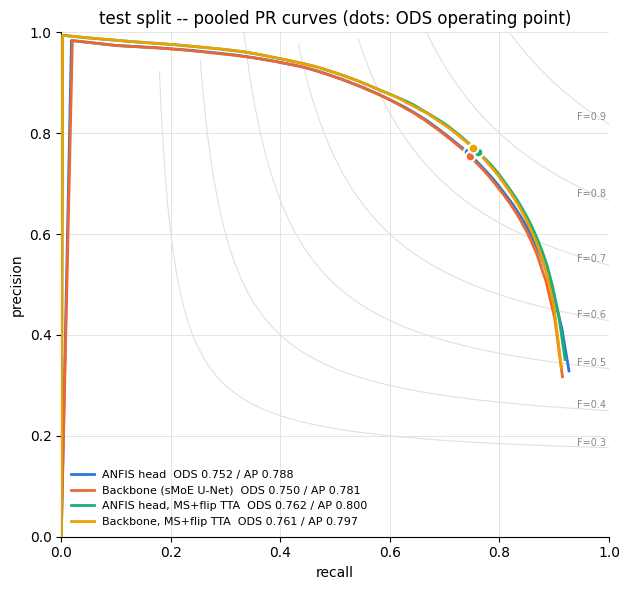

  saved: /kaggle/working/smoe_results_v4/results/bench_summary.csv, /kaggle/working/smoe_results_v4/figures/pr_curves.png

ALL EXPERIMENTS -- rows of every finished experiment (ablation table)
  experiment      row                                              ODS     OIS      AP         ODS 95% CI  split  complete
  full            ANFIS head [cal]                              0.7518  0.7738  0.7881    [0.7380,0.7655]  test   yes
  full            ANFIS head (strict, raw map) [raw]            0.7406  0.7526  0.6644    [0.7267,0.7537]  test   yes
  full            Backbone (sMoE U-Net) [cal]                   0.7502  0.7718  0.7809    [0.7366,0.7638]  test   yes
  full            Backbone (sMoE U-Net) (strict, raw map) [raw]  0.7388  0.7495  0.6563    [0.7249,0.7520]  test   yes
  full            ANFIS head, MS+flip TTA [cal]                 0.7623  0.7833  0.7995    [0.7481,0.7760]  test   yes
  full            Backbone, MS+flip TTA [cal]                   0.7613  0.7815  0.7973    [0.

In [16]:
# ============================================================================================================
# 16. RESULTS -- headline table, PR curves, PR-coverage diagnostic of an older run, all experiments
# ============================================================================================================
PAPER_TABLE1 = {'sMoE U-Net (paper, Table 1)': (0.7628, 0.7458, 0.7222), 'U-Net (paper)': (0.7437, 0.7260, 0.6946),
                'HED (paper)': (0.7688, 0.7514, 0.7126), 'Sobel (paper)': (0.5769, 0.5303, 0.4743)}
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']   # fixed order, never cycled
INK, MUTED, GRID = '#0b0b0b', '#898781', '#e1e0d9'


def results_table(results, title):
    log('=' * 110); log(title); log('=' * 110)
    log(f'  {"row":<52} {"ODS":>7} {"OIS":>7} {"AP":>7} {"dODS":>8} {"dOIS":>8} {"dAP":>8} {"ODS 95% CI":>18}  cover')
    _ref = PAPER_TABLE1['sMoE U-Net (paper, Table 1)']
    for name, (o, i, a) in PAPER_TABLE1.items():
        log(f'  {name:<52} {o:>7.4f} {i:>7.4f} {a:>7.4f}')
    log('  ' + '-' * 106)
    for key in sorted(results, key=lambda k: (int(k[1:].split('_')[0]), k.endswith('_raw'))):
        r = results[key]
        ci = f'[{r["ci"]["ODS"][0]:.4f},{r["ci"]["ODS"][1]:.4f}]' if r.get('ci') else '-'
        log(f'  {r["label"] + (" [cal]" if r.get("calibrated") else " [raw]"):<52} {r["ODS"]:>7.4f} {r["OIS"]:>7.4f} {r["AP"]:>7.4f} '
            f'{r["ODS"] - _ref[0]:>+8.4f} {r["OIS"] - _ref[1]:>+8.4f} {r["AP"] - _ref[2]:>+8.4f} {ci:>18}  '
            f'{"ok" if r.get("coverage_ok") else "no"}')
    log('  d* = row minus the paper\'s sMoE U-Net row (indicative only: the paper\'s protocol is undisclosed and scores HED')
    log('  0.013 ODS / 0.05 OIS / 0.07 AP below HED\'s published benchmark numbers). "cover" = the threshold grid covers the')
    log('  PR curve; a "no" row\'s ODS/AP are lower bounds. Compare rows of this pipeline only within the same TTA/NMS setting.')


def pr_curve_figure(results, fname):
    rows = [(k, r) for k, r in results.items() if r.get('calibrated') and 'counts' in r]
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(6.4, 6))
    for f in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9):                      # iso-F contours, recessive
        rr = np.linspace(0.01, 1, 200); pp = f * rr / (2 * rr - f + 1e-12); ok = (pp > 0) & (pp <= 1)
        ax.plot(rr[ok], pp[ok], color=GRID, lw=0.8, zorder=1)
        ax.annotate(f'F={f:.1f}', (0.995, min(f * 0.995 / (2 * 0.995 - f), 1.0)), fontsize=7, color=MUTED, ha='right', va='bottom')
    for j, (k, r) in enumerate(rows):
        R, P = pooled_pr(r['counts']); col = SERIES[j % len(SERIES)]
        ax.plot(R, P, color=col, lw=2, label=f'{r["label"]}  ODS {r["ODS"]:.3f} / AP {r["AP"]:.3f}', zorder=3)
        bt = r['best_t']; i = int(np.argmin(np.abs(BENCH_THR - bt)))
        ax.plot(R[i], P[i], 'o', ms=7, mfc=col, mec='white', mew=1.5, zorder=4)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='recall', ylabel='precision', title=f'{BENCH_SPLIT} split -- pooled PR curves (dots: ODS operating point)')
    ax.grid(color=GRID, lw=0.6); ax.legend(fontsize=8, loc='lower left', frameon=False)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show(); plt.close()


if BENCH_RESULTS:
    results_table(BENCH_RESULTS, f'HEADLINE -- experiment {EXPERIMENT!r}, {BENCH_SPLIT} split, reference protocol')
    pr_curve_figure(BENCH_RESULTS, f'{PATHS.figures}/pr_curves.png')
    with open(f'{PATHS.results}/bench_summary.csv', 'w') as f:
        f.write('experiment,row,label,head,mode,nms,calibrated,T,c,ODS,OIS,AP,AP_env,ODS_ci_lo,ODS_ci_hi,best_t,min_recall,max_recall,coverage_ok,n_images\n')
        for k, r in BENCH_RESULTS.items():
            ci = r.get('ci', {}).get('ODS', (float('nan'), float('nan')))
            f.write(f'{EXPERIMENT},{k},"{r["label"]}",{r["head"]},{r["mode"]},{int(r["nms"])},{int(r["calibrated"])},{r["T"]:.4f},{r["c"]:.4f},'
                    f'{r["ODS"]:.6f},{r["OIS"]:.6f},{r["AP"]:.6f},{r["AP_env"]:.6f},{ci[0]:.6f},{ci[1]:.6f},{r["best_t"]:.4f},'
                    f'{r["min_recall"]:.4f},{r["max_recall"]:.4f},{int(r["coverage_ok"])},{r["n_images"]}\n')
    log(f'  saved: {PATHS.results}/bench_summary.csv, {PATHS.figures}/pr_curves.png')
else:
    log('No benchmark rows in this session (RUN_BENCHMARK_EVAL off or the evaluation stopped before its first row).')


# ---- PR-coverage diagnostic of an older evaluation (v11/v12 file layout; reads saved counts only) --------------
def pr_coverage_diagnostic(json_path, counts_dir):
    with open(json_path) as f:
        prev = json.load(f)
    res, labels = prev.get('results', {}), {str(i): lab for i, lab in prev.get('row_order', [])}
    log('=' * 110); log(f'PR-COVERAGE DIAGNOSTIC of {json_path} (saved {prev.get("saved_at", "?")}; estimate; selects nothing)'); log('=' * 110)
    log(f'  {"row":<30} {"calibrated run":>28}   {"strict run":>22}   {"merged curve (estimate)":>30}')
    log(f'  {"":<30} {"calib.      ODS     AP  minR":>28}   {"ODS     AP  maxR":>22}   {"ODS     AP   recall range":>30}')
    shown = 0
    for k, v in res.items():
        if '_' in k or f'{k}_b0' not in res:
            continue
        f1, f0 = f'{counts_dir}/bench_counts_{k}.npz', f'{counts_dir}/bench_counts_{k}_b0.npz'
        if not (os.path.exists(f1) and os.path.exists(f0)):
            continue
        with np.load(f1) as z1, np.load(f0) as z0:
            c1 = tuple(z1[q].astype(np.float64) for q in _BENCH_KEYS); c0 = tuple(z0[q].astype(np.float64) for q in _BENCH_KEYS)
        if c1[0].shape[1] != len(BENCH_THR):
            continue
        T1, b1, v0 = float(v.get('temp', 1.0)), float(v.get('shift', 0.0)), res[f'{k}_b0']
        tau, R, P = merge_pr_runs([(c1, T1, b1), (c0, 1.0, 0.0)])
        ods_m, ap_m = curve_metrics(R, P)
        cl = f'b={b1:+.1f}' if T1 == 1.0 else f'T={T1:.2f},c={b1:+.2f}'
        log(f'  {labels.get(k, k):<30} {cl:>10} {v["ODS"]:.4f} {v["AP"]:.4f} {v["min_recall"]:.3f}   '
            f'{v0["ODS"]:.4f} {v0["AP"]:.4f} {v0["max_recall"]:.3f}   {ods_m:.4f} {ap_m:.4f}  [{R.min():.3f}, {R.max():.3f}]')
        shown += 1
    if shown:
        log('  A merged AP far above both runs means the threshold grid, not the detector, limited the BSDS AP of that run.')
    else:
        log('  (no row with both a calibrated and a strict run)')


_legacy_json = f'{WORK_DIR}/bench_results.json'
if os.path.exists(_legacy_json):
    pr_coverage_diagnostic(_legacy_json, WORK_DIR)


# ---- all experiments (the ablation table) ------------------------------------------------------------------
def collect_experiment_results():
    table = []
    for name, overrides in EXPERIMENTS.items():
        cfg = dict(BASE_CONFIG); cfg.update(overrides)
        if SMOKE_TEST:
            cfg.update(SMOKE_OVERRIDES)
        jf = f'{resolve_paths(name, cfg).results}/bench_results.json'
        if not os.path.exists(jf):
            table.append((name, None)); continue
        with open(jf) as f:
            table.append((name, json.load(f)))
    return table


log('\n' + '=' * 110); log('ALL EXPERIMENTS -- rows of every finished experiment (ablation table)'); log('=' * 110)
log(f'  {"experiment":<15} {"row":<44} {"ODS":>7} {"OIS":>7} {"AP":>7} {"ODS 95% CI":>18}  split  complete')
_any = False
for _name, _payload in collect_experiment_results():
    if _payload is None:
        log(f'  {_name:<15} (not run)'); continue
    _any = True
    for _k in sorted(_payload['results'], key=lambda k: (int(k[1:].split('_')[0]), k.endswith('_raw'))):
        _r = _payload['results'][_k]
        _ci = f'[{_r["ci"]["ODS"][0]:.4f},{_r["ci"]["ODS"][1]:.4f}]' if _r.get('ci') else '-'
        log(f'  {_name:<15} {_r["label"] + (" [cal]" if _r.get("calibrated") else " [raw]"):<44} {_r["ODS"]:>7.4f} {_r["OIS"]:>7.4f} '
            f'{_r["AP"]:>7.4f} {_ci:>18}  {_payload.get("split", "?"):<5}  {"yes" if _payload.get("complete") else "no"}')
if _any:
    log('  Ablation reading: "full" vs "smoe_2experts" / "no_smoe" = the corner/junction expert and the sMoE block; '
        '"mf_grid_init" = the FCM initialisation;')
    log('  "identity_init" = the IRLS start; "fixed_R4" / "joint_fcm" / "no_x2_temp" = rule-count, stratification and antecedent '
        'temperature; "loss_balanced" = the objective; "seed_*" = training-seed variance.')

## 17. Qualitative results and explanations

* **Qualitative grid**: input, annotator agreement, backbone map, ANFIS map (dark = edge), for the first test images and for `QUALITATIVE_INDICES`.
* **Rule firing maps** $\bar w_r(x)$ (one panel per rule on a fixed 0–1 scale), the dominant rule per pixel, the rule-activation entropy, the Sobel input and the output.
* **Rule correction maps**: the exact per-rule additive log-odds correction $\bar w_r\,[p_r x_1 + (q_r-1)z + r_r]$ — red raises, blue lowers the backbone's log-odds; the sum reconstructs the decision to float round-off (printed).
* **Rule base**: the effective membership functions of $x_1$ and $x_2^{(T)}$ and the rule centres.
* **Strategy maps**: the sMoE gate weight of every expert at every level (the base paper's second explanation view).
* **Rule profiling and health** on the validation split: usage, dominance, mean inputs, GT edge purity, mean correction, a pairwise redundancy matrix, and flags for collapsed or redundant rules — the numbers behind any claim that the rules are distinct concepts.

Rule colours are assigned in a fixed order (rule 1 is always the same blue, etc.); firing, entropy and strategy maps use one sequential hue; corrections use a blue–red diverging scale with a neutral midpoint.

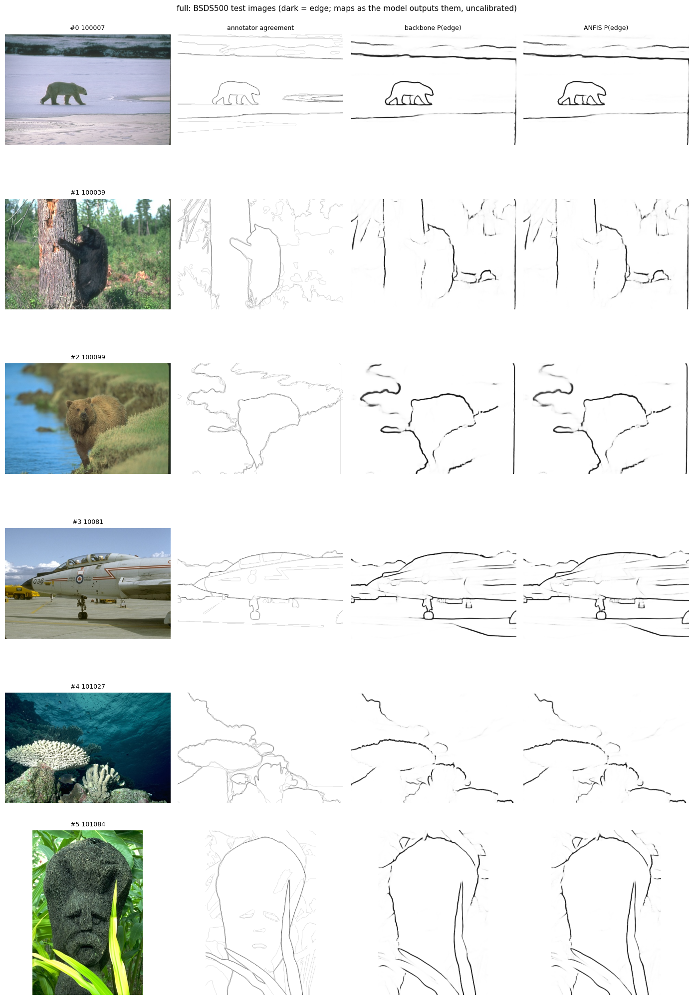

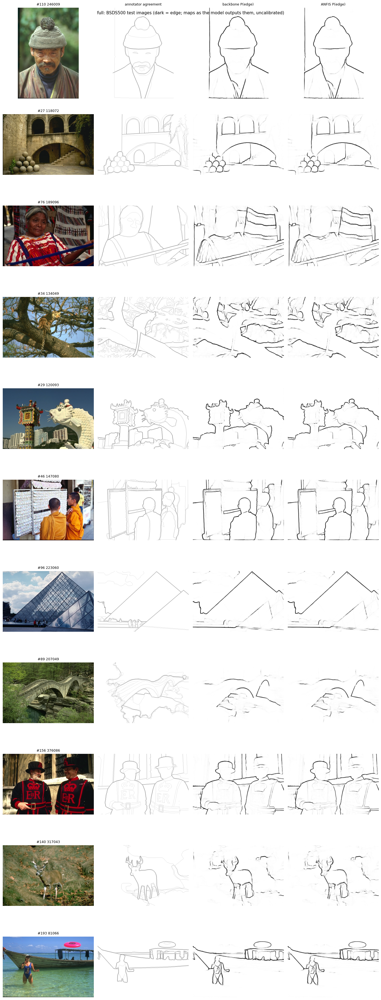

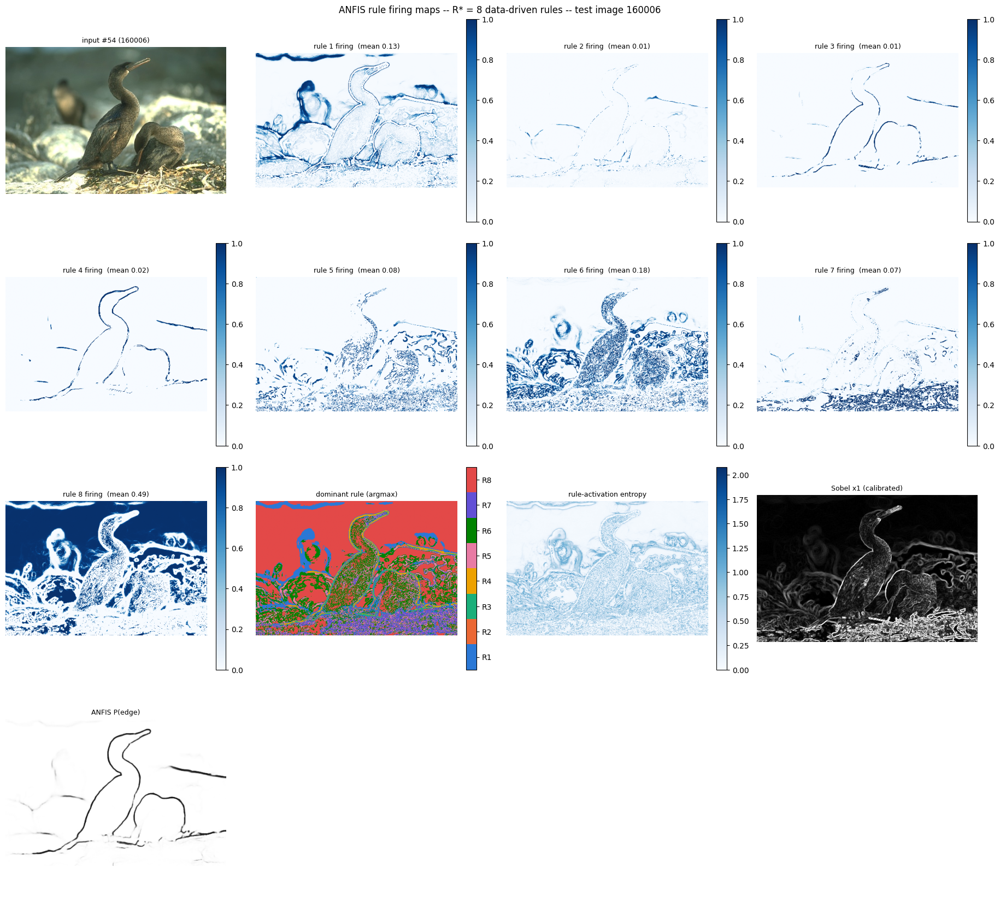

Rule firing maps saved for test image 160006. The entropy describes how activation is spread over rules; it is not validated as predictive uncertainty.
[explanation fidelity] max |z + sum_r correction_r - head logit| = 2.86e-06  PASS


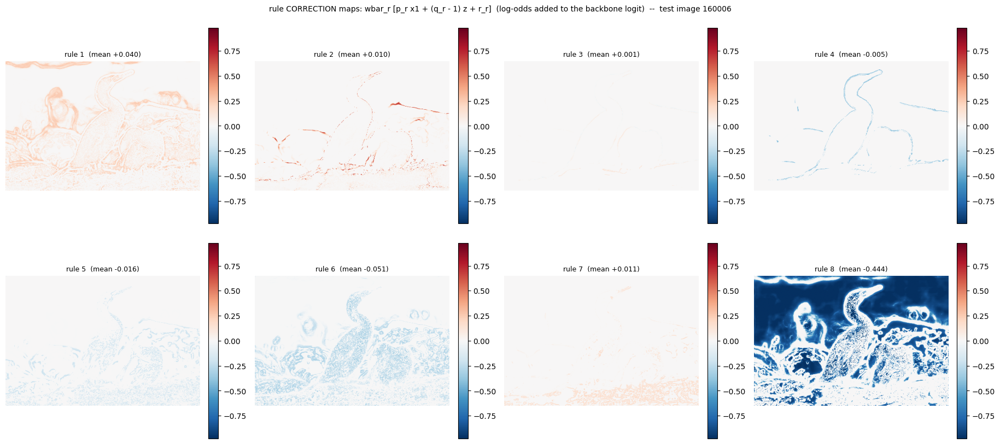

Rule correction maps saved (red raises, blue lowers the backbone log-odds).
  rule      c_x1  sig_x1    c_x2  sig_x2        p        q        r   (effective widths)
  R1       0.100   0.040   0.149   0.040    0.029    0.901   -0.209
  R2       0.441   0.056   0.251   0.056    0.143    0.777    0.140
  R3       0.825   0.175   0.623   0.100    0.170    0.944   -0.019
  R4       0.187   0.095   0.668   0.063    0.568    1.057   -0.474
  R5       0.423   0.056   0.140   0.056   -0.233    1.001   -0.114
  R6       0.161   0.040   0.099   0.039   -0.048    1.032   -0.060
  R7       0.803   0.154   0.222   0.123    0.059    0.990    0.057
  R8       0.038   0.031   0.068   0.027   -0.212    1.105   -0.110


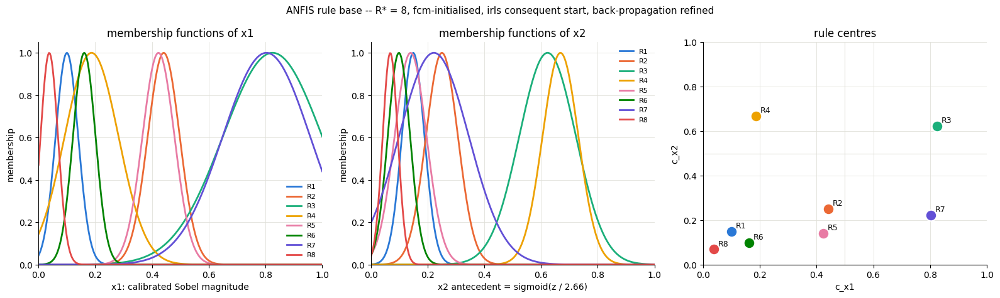

  reading aid for the x2 axis (T = 2.66): x2=0.05 <-> z=-7.8 <-> P_backbone=0.0004, x2=0.25 <-> z=-2.9 <-> P_backbone=0.0513, x2=0.50 <-> z=+0.0 <-> P_backbone=0.5000, x2=0.75 <-> z=+2.9 <-> P_backbone=0.9487


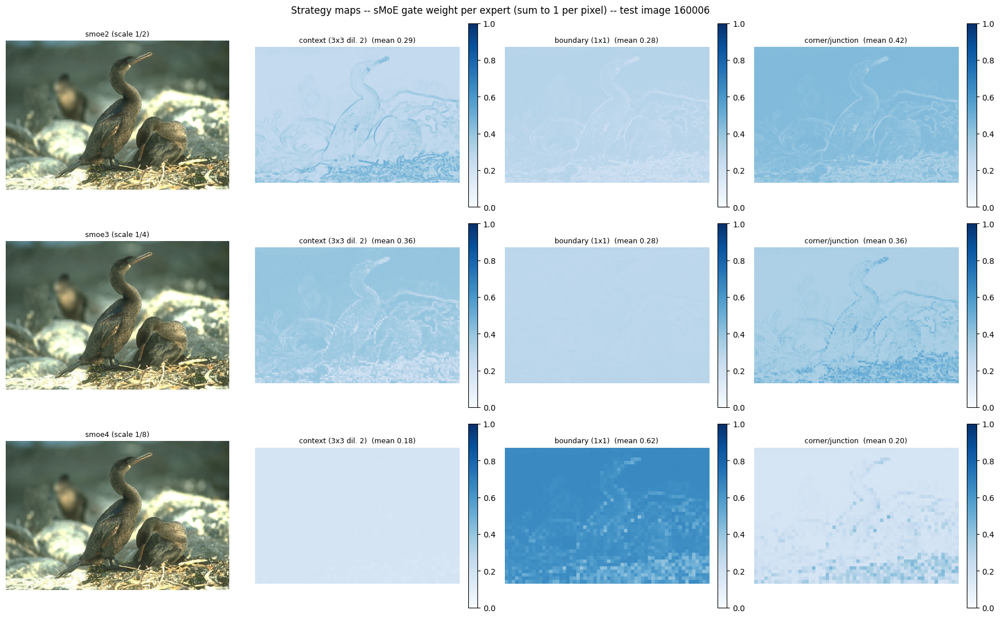


  RULE PROFILE on the val split (pixels where the rule dominates); x2 antecedent temperature T = 2.655
  rule   usage   dom.     x1     x2  x2 ant     GT  edge%   pred    corr  role (from GT)
  ----------------------------------------------------------------------------------------------------
  R1     13.1%  10.0%  0.083  0.014   0.147  0.030   2.7%  0.015  +0.190  background, flat
  R2      1.5%   1.1%  0.382  0.078   0.269  0.077   9.0%  0.119  +0.535  background, textured
  R3      1.9%   1.9%  0.737  0.728   0.605  0.176  25.3%  0.736  +0.035  edge, backbone confident
  R4      1.6%   1.6%  0.174  0.648   0.568  0.164  23.1%  0.590  -0.303  edge, backbone uncertain
  R5     11.2%  12.1%  0.369  0.004   0.099  0.016   1.4%  0.004  -0.172  background, textured
  R6     23.8%  24.8%  0.172  0.002   0.081  0.009   0.7%  0.002  -0.235  background, textured
  R7      7.8%   7.2%  0.721  0.029   0.148  0.033   3.6%  0.032  +0.140  background, textured
  R8     39.1%  41.3%  0.034  0.001

In [17]:
# ============================================================================================================
# 17. QUALITATIVE RESULTS + EXPLANATIONS
# ============================================================================================================
SEQ_CMAP, DIV_CMAP, EDGE_CMAP = 'Blues', 'RdBu_r', 'gray_r'


def rule_colors(R):
    """Fixed categorical order (never cycled): the 8 validated hues, then tab20 steps for rule counts above 8."""
    return [SERIES[k] if k < len(SERIES) else matplotlib.colors.to_hex(plt.cm.tab20((k - len(SERIES)) % 20)) for k in range(R)]


def denorm(t):
    mean = torch.tensor([0.485, 0.456, 0.406], device=t.device).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=t.device).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).cpu().numpy()


@torch.no_grad()
def forward_full(idx, ds=None):
    """One image at native resolution -> (img tensor [3,H,W], soft label [1,H,W], stem, ModelOut cropped to HxW)."""
    ds = ds_test if ds is None else ds
    idx = min(int(idx), len(ds) - 1)
    img, mask, stem = ds[idx]
    model.eval()
    ip, H, W = pad_to_multiple(img.unsqueeze(0).to(DEVICE), multiple=PAD_MULTIPLE)
    out = model(ip)
    return img, mask, stem, ModelOut(*[t[..., :H, :W] for t in out])


def _off(ax, title=None):
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=9)


def show_qualitative(indices=None, n=6, fname='qualitative.png'):
    indices = list(range(min(n, len(ds_test)))) if indices is None else [min(i, len(ds_test) - 1) for i in indices]
    fig, axes = plt.subplots(len(indices), 4, figsize=(14, 3.4 * len(indices)), squeeze=False)
    for row, idx in enumerate(indices):
        img, mask, stem, out = forward_full(idx)
        axes[row, 0].imshow(denorm(img)); _off(axes[row, 0], f'#{idx} {stem}' if row == 0 else f'#{idx} {stem}')
        axes[row, 1].imshow(mask[0].numpy(), cmap=EDGE_CMAP, vmin=0, vmax=1); _off(axes[row, 1], 'annotator agreement' if row == 0 else None)
        axes[row, 2].imshow(out.x2[0, 0].cpu().numpy(), cmap=EDGE_CMAP, vmin=0, vmax=1); _off(axes[row, 2], 'backbone P(edge)' if row == 0 else None)
        axes[row, 3].imshow(out.prob[0, 0].cpu().numpy(), cmap=EDGE_CMAP, vmin=0, vmax=1); _off(axes[row, 3], 'ANFIS P(edge)' if row == 0 else None)
    fig.suptitle(f'{EXPERIMENT}: BSDS500 test images (dark = edge; maps as the model outputs them, uncalibrated)', fontsize=11)
    plt.tight_layout(); plt.savefig(f'{PATHS.figures}/{fname}', dpi=130, bbox_inches='tight'); plt.show(); plt.close()


def rule_firing_figure(idx):
    img, mask, stem, out = forward_full(idx)
    rw = out.rule_maps[0].cpu(); R = rw.shape[0]; cols = rule_colors(R)
    n_panels, n_cols = R + 5, 4
    fig, axes = plt.subplots(int(np.ceil(n_panels / n_cols)), n_cols, figsize=(4.6 * n_cols, 4.2 * int(np.ceil(n_panels / n_cols))))
    axes = np.array(axes).reshape(-1)
    axes[0].imshow(denorm(img)); _off(axes[0], f'input #{idx} ({stem})')
    for k in range(R):
        im = axes[k + 1].imshow(rw[k].numpy(), cmap=SEQ_CMAP, vmin=0, vmax=1); _off(axes[k + 1], f'rule {k + 1} firing  (mean {rw[k].mean():.2f})')
        plt.colorbar(im, ax=axes[k + 1], fraction=0.046, pad=0.04)
    dom = rw.argmax(dim=0).numpy()
    im = axes[R + 1].imshow(dom, cmap=ListedColormap(cols), vmin=-0.5, vmax=R - 0.5); _off(axes[R + 1], 'dominant rule (argmax)')
    cb = plt.colorbar(im, ax=axes[R + 1], fraction=0.046, pad=0.04, ticks=range(R)); cb.set_ticklabels([f'R{k + 1}' for k in range(R)])
    im = axes[R + 2].imshow(rule_entropy_map(out.rule_maps)[0, 0].cpu().numpy(), cmap=SEQ_CMAP, vmin=0, vmax=math.log(R))
    _off(axes[R + 2], 'rule-activation entropy'); plt.colorbar(im, ax=axes[R + 2], fraction=0.046, pad=0.04)
    axes[R + 3].imshow(out.x1[0, 0].cpu().numpy(), cmap='gray', vmin=0, vmax=1); _off(axes[R + 3], 'Sobel x1 (calibrated)')
    axes[R + 4].imshow(out.prob[0, 0].cpu().numpy(), cmap=EDGE_CMAP, vmin=0, vmax=1); _off(axes[R + 4], 'ANFIS P(edge)')
    for ax in axes[n_panels:]:
        ax.axis('off')
    fig.suptitle(f'ANFIS rule firing maps -- R* = {R} data-driven rules -- test image {stem}', fontsize=12)
    plt.tight_layout(); plt.savefig(f'{PATHS.figures}/rule_firing_maps_{stem}.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close()
    log(f'Rule firing maps saved for test image {stem}. The entropy describes how activation is spread over rules; '
        'it is not validated as predictive uncertainty.')


def rule_correction_figure(idx):
    img, mask, stem, out = forward_full(idx)
    head = model.anfis_head; R = head.n_rules
    if head.logit_consequents:
        _, corr = rule_logit_decomposition(head, out.x1, out.x2, out.rule_maps, z2=out.unet_logits)
        fid = explanation_fidelity(head, out.x1, out.x2, out.unet_logits)
        log(f'[explanation fidelity] max |z + sum_r correction_r - head logit| = {fid:.2e}' + ('  PASS' if fid < 1e-4 else '  <-- WARNING'))
        title, note = 'rule CORRECTION maps: wbar_r [p_r x1 + (q_r - 1) z + r_r]  (log-odds added to the backbone logit)', 'red raises, blue lowers the backbone log-odds'
    else:
        corr = rule_contribution_maps(head, out.x1, out.x2, out.rule_maps, z2=out.unet_logits)
        title, note = 'rule contribution maps: wbar_r x TSK_r', 'red/blue = positive/negative contribution'
    contrib = corr[0].cpu().numpy()
    vmax = float(np.percentile(np.abs(contrib), 99)) or 1e-3
    n_cols = 4
    fig, axes = plt.subplots(int(np.ceil(R / n_cols)), n_cols, figsize=(4.6 * n_cols, 4.2 * int(np.ceil(R / n_cols))))
    axes = np.array(axes).reshape(-1)
    for k in range(R):
        im = axes[k].imshow(contrib[k], cmap=DIV_CMAP, vmin=-vmax, vmax=vmax); _off(axes[k], f'rule {k + 1}  (mean {contrib[k].mean():+.3f})')
        plt.colorbar(im, ax=axes[k], fraction=0.046, pad=0.04)
    for ax in axes[R:]:
        ax.axis('off')
    fig.suptitle(f'{title}  --  test image {stem}', fontsize=10)
    plt.tight_layout(); plt.savefig(f'{PATHS.figures}/rule_correction_maps_{stem}.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close()
    log(f'Rule correction maps saved ({note}).')


def rule_base_figure():
    head = model.anfis_head; R = head.n_rules; cols = rule_colors(R)
    theta = head.consequents.detach().cpu().numpy(); eff = head.effective_sigmas().cpu().numpy(); T = float(head.x2_temperature)
    x = np.linspace(0, 1, 300)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    log(f'  {"rule":<6}{"c_x1":>8}{"sig_x1":>8}{"c_x2":>8}{"sig_x2":>8}{"p":>9}{"q":>9}{"r":>9}   (effective widths)')
    for k, rule in enumerate(head.rules):
        cx1, cx2 = rule.mf_x1.center.item(), rule.mf_x2.center.item(); s1, s2 = float(eff[k, 0]), float(eff[k, 1])
        axes[0].plot(x, np.exp(-((x - cx1) ** 2) / (2 * s1 ** 2 + 1e-8)), color=cols[k], lw=2, label=f'R{k + 1}')
        axes[1].plot(x, np.exp(-((x - cx2) ** 2) / (2 * s2 ** 2 + 1e-8)), color=cols[k], lw=2, label=f'R{k + 1}')
        axes[2].scatter(cx1, cx2, s=160, color=cols[k], edgecolors='white', lw=1.5, zorder=5)
        axes[2].annotate(f'R{k + 1}', (cx1 + 0.015, cx2 + 0.015), fontsize=9, color=INK)
        log(f'  R{k + 1:<5}{cx1:>8.3f}{s1:>8.3f}{cx2:>8.3f}{s2:>8.3f}{theta[k, 0]:>9.3f}{theta[k, 1]:>9.3f}{theta[k, 2]:>9.3f}')
    x2_label = 'x2 = sigmoid(z)' if T == 1.0 else f'x2 antecedent = sigmoid(z / {T:.2f})'
    for ax, xl, ti in ((axes[0], 'x1: calibrated Sobel magnitude', 'membership functions of x1'), (axes[1], x2_label, 'membership functions of x2')):
        ax.set(xlabel=xl, ylabel='membership', title=ti, xlim=(0, 1), ylim=(0, 1.05)); ax.grid(color=GRID, lw=0.6); ax.legend(fontsize=8, frameon=False)
        for s in ('top', 'right'): ax.spines[s].set_visible(False)
    axes[2].axhline(0.5, color=GRID, lw=0.8); axes[2].axvline(0.5, color=GRID, lw=0.8)
    axes[2].set(xlabel='c_x1', ylabel='c_x2', title='rule centres', xlim=(0, 1), ylim=(0, 1)); axes[2].grid(color=GRID, lw=0.6)
    for s in ('top', 'right'): axes[2].spines[s].set_visible(False)
    fig.suptitle(f'ANFIS rule base -- R* = {R}, {MF_INIT}-initialised, {CONSEQUENT_INIT} consequent start, back-propagation refined', fontsize=11)
    plt.tight_layout(); plt.savefig(f'{PATHS.figures}/anfis_rule_base.png', dpi=150, bbox_inches='tight'); plt.show(); plt.close()
    if T != 1.0:
        log(f'  reading aid for the x2 axis (T = {T:.2f}): ' + ', '.join(
            f'x2={a:.2f} <-> z={T * math.log(a / (1 - a)):+.1f} <-> P_backbone={1 / (1 + math.exp(-T * math.log(a / (1 - a)))):.4f}'
            for a in (0.05, 0.25, 0.5, 0.75)))


def strategy_maps_figure(idx):
    if not USE_SMOE:
        log('strategy maps: the model has no sMoE blocks (USE_SMOE = False)'); return
    gates, hooks = {}, []
    for name in ('smoe2', 'smoe3', 'smoe4'):
        hooks.append(getattr(model, name).register_forward_hook(lambda m, i, o, _n=name: gates.__setitem__(_n, o[1].detach())))
    try:
        img, mask, stem, out = forward_full(idx)
    finally:
        for h in hooks:
            h.remove()
    H, W = img.shape[-2:]
    n_exp = gates['smoe2'].shape[1]
    names = ['context (3x3 dil. 2)', 'boundary (1x1)', 'corner/junction'][:n_exp]
    fig, axes = plt.subplots(3, n_exp + 1, figsize=(4.4 * (n_exp + 1), 11))
    for r, name in enumerate(('smoe2', 'smoe3', 'smoe4')):
        g = F.interpolate(gates[name], size=(H + (-H) % PAD_MULTIPLE, W + (-W) % PAD_MULTIPLE), mode='nearest')[0, :, :H, :W].cpu().numpy()
        axes[r, 0].imshow(denorm(img)); _off(axes[r, 0], f'{name} (scale 1/{2 ** (r + 1)})')
        for e in range(n_exp):
            im = axes[r, e + 1].imshow(g[e], cmap=SEQ_CMAP, vmin=0, vmax=1); _off(axes[r, e + 1], f'{names[e]}  (mean {g[e].mean():.2f})')
            plt.colorbar(im, ax=axes[r, e + 1], fraction=0.046, pad=0.04)
    fig.suptitle(f'Strategy maps -- sMoE gate weight per expert (sum to 1 per pixel) -- test image {stem}', fontsize=12)
    plt.tight_layout(); plt.savefig(f'{PATHS.figures}/strategy_maps_{stem}.png', dpi=130, bbox_inches='tight'); plt.show(); plt.close()


@torch.no_grad()
def profile_rules(split=None):
    """Rule semantics and health on validation data: usage, dominance, mean inputs, GT edge purity, mean log-odds
    correction, pairwise redundancy (shared firing mass), and flags for collapsed / redundant rules."""
    split = PROFILE_SPLIT if split is None else split
    loader = {'val': loader_val, 'test': loader_test}[split]
    head = model.anfis_head; R = head.n_rules; T = float(head.x2_temperature); logit_mode = head.logit_consequents
    sums = {k: dict(x1=0.0, x2=0.0, x2a=0.0, gt=0.0, edge=0.0, pred=0.0, corr=0.0, n=0) for k in range(R)}
    usage, overlap, npix = torch.zeros(R, dtype=torch.float64), torch.zeros(R, R, dtype=torch.float64), 0
    model.eval()
    for imgs, masks, _ in tqdm(loader, desc=f'  profiling ({split})', leave=False):
        ip, H, W = pad_to_multiple(imgs.to(DEVICE), multiple=PAD_MULTIPLE)
        out = ModelOut(*[t[..., :H, :W] for t in model(ip)])
        x2a = head.antecedent_x2(out.x2, out.unet_logits)
        gt = F.interpolate(masks.to(DEVICE), size=(H, W), mode='nearest')
        dom = out.rule_maps.argmax(dim=1)
        corr = rule_logit_decomposition(head, out.x1, out.x2, out.rule_maps, z2=out.unet_logits)[1] if logit_mode else None
        w = out.rule_maps[0].reshape(R, -1).double()
        usage += w.sum(1).cpu(); npix += w.shape[1]
        for i in range(R):
            overlap[i] += torch.minimum(w[i:i + 1], w).sum(-1).cpu()
        for k in range(R):
            m = dom == k
            if m.sum() == 0:
                continue
            sums[k]['x1'] += out.x1[:, 0][m].sum().item(); sums[k]['x2'] += out.x2[:, 0][m].sum().item()
            sums[k]['x2a'] += x2a[:, 0][m].sum().item(); sums[k]['gt'] += gt[:, 0][m].sum().item()
            sums[k]['edge'] += (gt[:, 0][m] >= 0.3).sum().item(); sums[k]['pred'] += out.prob[:, 0][m].sum().item()
            if corr is not None:
                sums[k]['corr'] += corr[:, k][m].sum().item()
            sums[k]['n'] += m.sum().item()

    def role(purity, mean_pred, mean_x1):
        if purity >= 0.25 and mean_pred >= 0.5: return 'edge, backbone confident'
        if purity >= 0.10: return 'edge, backbone uncertain'
        return 'background, textured' if mean_x1 >= 0.15 else 'background, flat'

    log(f'\n  RULE PROFILE on the {split} split (pixels where the rule dominates); x2 antecedent temperature T = {T:.3f}')
    log(f'  {"rule":<5} {"usage":>6} {"dom.":>6} {"x1":>6} {"x2":>6} {"x2 ant":>7} {"GT":>6} {"edge%":>6} {"pred":>6} {"corr":>7}  role (from GT)')
    log('  ' + '-' * 100)
    prof = []
    for k in range(R):
        n = max(sums[k]['n'], 1)
        mx1, mx2, mx2a, mgt, mpr = (sums[k][q] / n for q in ('x1', 'x2', 'x2a', 'gt', 'pred'))
        pur, mco = sums[k]['edge'] / n, sums[k]['corr'] / n
        use, dom_share = float(usage[k]) / max(npix, 1), sums[k]['n'] / max(npix, 1)
        prof.append(dict(rule=k + 1, usage=use, dominance=dom_share, x1=mx1, x2=mx2, x2_antecedent=mx2a, gt=mgt, purity=pur, pred=mpr,
                         correction=mco, role=role(pur, mpr, mx1)))
        log(f'  R{k + 1:<4} {100 * use:>5.1f}% {100 * dom_share:>5.1f}% {mx1:>6.3f} {mx2:>6.3f} {mx2a:>7.3f} {mgt:>6.3f} {100 * pur:>5.1f}% '
            f'{mpr:>6.3f} {mco:>+7.3f}  {role(pur, mpr, mx1)}')
    log('  usage = mean normalised firing; dom. = share of pixels where the rule fires strongest; edge% = share of its dominated pixels')
    log('  with annotator agreement >= 0.3; corr = mean log-odds the rule adds to the backbone there (0 = passes the backbone through).')
    ov = overlap.numpy(); self_mass = np.diag(ov).copy()
    red = ov / np.maximum(np.minimum(self_mass[:, None], self_mass[None, :]), 1e-12)
    log('\n  Redundancy: share of the SMALLER rule\'s firing mass that a pair has in common (sum_x min(w_i, w_j))')
    log('        ' + ' '.join(f'{f"R{j + 1}":>6}' for j in range(R)))
    for i in range(R):
        log(f'  {f"R{i + 1}":<5} ' + ' '.join(f'{red[i, j]:>6.2f}' if i != j else f'{"-":>6}' for j in range(R)))
    flags = []
    for p in prof:
        if p['usage'] < 0.02 or p['dominance'] < 0.005:
            flags.append(f'R{p["rule"]}: usage {100 * p["usage"]:.1f}% / dominance {100 * p["dominance"]:.2f}% -> COLLAPSING (rarely decides a pixel)')
    for i in range(R):
        for j in range(i + 1, R):
            if red[i, j] > 0.5:
                flags.append(f'R{i + 1}-R{j + 1}: {100 * red[i, j]:.0f}% of the smaller rule\'s firing is shared -> REDUNDANT pair')
    if logit_mode and max(abs(p['correction']) for p in prof) < 0.05:
        flags.append('all rules add < 0.05 log-odds where they dominate -> the head is ~ the identity (it does not re-rank pixels)')
    log('\n  Rule-health flags: ' + ('none' if not flags else ''))
    for fl in flags:
        log('    ' + fl)
    with open(f'{PATHS.results}/rule_profile_{split}.json', 'w') as f:
        json.dump(dict(split=split, temperature=T, profile=prof, redundancy=red.tolist(), flags=flags), f, indent=1, default=float)
    return prof, red, flags


show_qualitative(None, n=6, fname='qualitative_first6.png')
show_qualitative(QUALITATIVE_INDICES, fname='qualitative_selected.png')
rule_firing_figure(XAI_IMAGE_INDEX)
rule_correction_figure(XAI_IMAGE_INDEX)
rule_base_figure()
strategy_maps_figure(XAI_IMAGE_INDEX)
RULE_PROFILE, RULE_REDUNDANCY, RULE_FLAGS = profile_rules()

## 18. Reproducibility record

What this run was: the merged configuration and its hash, the experiment name, library versions, the checkpoints that were used (with the configuration hash each one was saved under), the evaluator configuration, the calibrations, and every file the run produced. The same record is embedded in each checkpoint (`_manifest`) and in `results/bench_results.json`.

In [18]:
# ============================================================================================================
# 18. REPRODUCIBILITY RECORD
# ============================================================================================================
def _ckpt_summary(path):
    if not os.path.exists(path):
        return dict(path=path, present=False)
    try:
        ck = torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        ck = torch.load(path, map_location='cpu')
    m = ck.get('_manifest') or {}
    return dict(path=path, present=True, size_mb=round(os.path.getsize(path) / 2 ** 20, 1), epoch=ck.get('epoch'),
                stage=ck.get('stage'), R_STAR=ck.get('R_STAR'), saved_at=m.get('saved_at'), config_hash=m.get('config_hash'),
                experiment=m.get('experiment'), versions=m.get('versions'), model_behaviour=m.get('model_behaviour'))


record = dict(
    experiment=EXPERIMENT, config_hash=CONFIG_HASH, smoke_test=SMOKE_TEST, seed=SEED,
    versions={'python': sys.version.split()[0], 'torch': torch.__version__, 'numpy': np.__version__, 'opencv': cv2.__version__,
              'platform': platform.platform()},
    device=str(DEVICE),
    config={k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()},
    data=dict(train=len(ds_train), val=len(ds_val), test=len(ds_test), bsr_root=BSR_ROOT),
    model=dict(parameters=int(sum(p.numel() for p in model.parameters())), n_rules=int(model.anfis_head.n_rules),
               x2_temperature=float(model.anfis_head.x2_temperature), sobel_global_scale=float(model.sobel.global_scale),
               consequents=model.anfis_head.consequents.detach().cpu().numpy().tolist(),
               centers=model.anfis_head.centers().cpu().numpy().tolist(),
               effective_sigmas=model.anfis_head.effective_sigmas().cpu().numpy().tolist(),
               weights_md5=hashlib.md5(b''.join(p.detach().cpu().numpy().tobytes() for p in model.parameters())).hexdigest()[:12]),
    training=dict(best_val_loss=float(best_val_loss), best_epoch=int(best_epoch), epochs_logged=len(train_losses),
                  warmup_epochs_logged=len(backbone_warmup_losses)),
    checkpoints={k: _ckpt_summary(v) for k, v in vars(PATHS.ckpt).items()},
    shared_backbone=PATHS.shared_phase0a,
    evaluator=EVALUATOR_CONFIG if RUN_BENCHMARK_EVAL else None,
    calibrations={f'{h}/{m}': c for (h, m), c in CALIBRATIONS.items()},
    benchmark=({k: {kk: vv for kk, vv in v.items() if kk != 'counts'} for k, v in BENCH_RESULTS.items()} if BENCH_RESULTS else None),
    benchmark_complete=bool(BENCH_COMPLETE),
    files=sorted(os.path.relpath(os.path.join(d, f), PATHS.root).replace(os.sep, '/')
                 for d, _, fs in os.walk(PATHS.root) for f in fs if not d.startswith(PATHS.maps) and not f.endswith('.npz')),
    written_at=time.strftime('%Y-%m-%d %H:%M:%S'),
)
with open(f'{PATHS.results}/run_record.json', 'w') as f:
    json.dump(record, f, indent=1, default=float)

log('=' * 100); log(f'RUN RECORD -- experiment {EXPERIMENT!r}, config hash {CONFIG_HASH}'); log('=' * 100)
log(f'  versions   : ' + ', '.join(f'{k} {v}' for k, v in record['versions'].items()))
log(f'  data       : train {len(ds_train)} / val {len(ds_val)} / test {len(ds_test)}')
log(f'  model      : {record["model"]["parameters"] / 1e6:.2f}M parameters, R* = {record["model"]["n_rules"]}, '
    f'T_x2 = {record["model"]["x2_temperature"]:.3f}, weights md5 {record["model"]["weights_md5"]}')
for _k, _c in record['checkpoints'].items():
    log(f'  checkpoint : {_k:<8} ' + (f'{_c["path"]}  (saved {_c["saved_at"]}, config {_c["config_hash"]}, '
                                     f'epoch {_c["epoch"]}{", stage " + str(_c["stage"]) if _c.get("stage") else ""})'
                                     if _c['present'] else f'{_c["path"]}  (absent)'))
log(f'  benchmark  : ' + ('complete' if BENCH_COMPLETE else 'not run / incomplete') + f'  ({len(BENCH_RESULTS)} rows)')
log(f'  record     : {PATHS.results}/run_record.json  (+ run.log, figures/, results/)')

RUN RECORD -- experiment 'full', config hash 657a10e0dff8
  versions   : python 3.13.16, torch 2.11.0+cu130, numpy 2.1.3, opencv 4.14.0, platform Linux-6.18.55+-x86_64-with-glibc2.39
  data       : train 200 / val 100 / test 200
  model      : 39.30M parameters, R* = 8, T_x2 = 2.655, weights md5 48f6a53f894e
  checkpoint : phase0a  /kaggle/working/smoe_results_v4/checkpoints/phase0a_warmup_v6.pt  (saved 2026-11-22 11:53:06, config 657a10e0dff8, epoch 150)
  checkpoint : phase0b  /kaggle/working/smoe_results_v4/checkpoints/phase0b_rstar_v12.pt  (saved 2026-11-22 12:00:31, config 657a10e0dff8, epoch None)
  checkpoint : train    /kaggle/working/smoe_results_v4/checkpoints/training_state_v12.pt  (saved 2026-11-22 13:06:43, config 657a10e0dff8, epoch 46, stage B)
  benchmark  : complete  (6 rows)
  record     : /kaggle/working/smoe_results_v4/results/run_record.json  (+ run.log, figures/, results/)
